# TriNet · Três redes neurais para risco financeiro

**T2 · Aprendizado Profundo (CIC407) · Inteligência Artificial e Aplicações**

**Integrantes (nome completo e RA):** *a preencher*

> **Aviso (leia primeiro).** Este notebook é um **trabalho de curso, com fins educacionais**. Nada aqui é recomendação de
> investimento, e o modelo de crédito **não é** um modelo de decisão de crédito real: os dados são antigos (Taiwan, 2005), os
> custos usados para escolher o limiar são **ilustrativos** e o diagnóstico de equidade mostra limitações, não uma solução.

## Objetivo

Aplicar redes neurais em **TensorFlow/Keras** a três problemas supervisionados de **risco financeiro**, projetando cada arquitetura
**do zero** (camada a camada, com `tf.keras.layers`; nada de `keras.applications`, transfer learning ou modelos prontos),
escolhendo hiperparâmetros por **evidência** (ablações curtas, comparação com baselines) e **justificando** cada decisão:

| # | Problema | Tipo | Dados | Alvo |
|---|---|---|---|---|
| 1 | **Risco de crédito** | Classificação binária (desbalanceada) | *Default of Credit Card Clients* (UCI #350, 30.000 clientes) | inadimplência no mês seguinte |
| 2 | **Risco de mercado, via números** | Regressão | S&P 500, 5 anos (505 ações) | volatilidade realizada dos próximos 5 pregões |
| 3 | **Risco de mercado, via imagem** | CNN (visão computacional, 3 classes) | gráficos OHLC + volume **renderizados** das mesmas ações | regime de volatilidade (baixa/média/alta) |

As redes 2 e 3 modelam a **mesma grandeza** por duas vias, **números × imagem**. Isso permite fechar com uma pergunta honesta:
*o gráfico acrescenta algo além das features numéricas?*

## Estrutura (mesmo esqueleto nas três seções)

0. Capa, setup e versões (esta parte).
1. **Crédito (classificação):** novas instâncias reservadas → dedup → EDA → divisão estratificada → normalização visível →
   ablação → arquitetura final → justificativas → treino → teste (matriz de confusão e relatório) → equidade → novas instâncias.
2. **Volatilidade (regressão):** dados de mercado compartilhados (S&P 500) → features sem vazamento → divisão cronológica →
   normalização → ablação → modelo final → RMSE/MAE e margem relativa → erro por período e regime → novas instâncias.
3. **Gráficos de candlestick (CNN):** renderização determinística → ablação de 4 configurações → CNN final → acurácia e comparação com a rede 2.
4. **Conclusões**, comparação com os baselines, limitações e considerações éticas.
5. **Apêndice (fora da área avaliada):** exporta os modelos treinados (ONNX + manifesto + amostras de referência) para uma API de inferência.

## Dados e licenças

- **Default of Credit Card Clients** (UCI #350): Yeh, I-C. (2009), DOI 10.24432/C55S3H, licença **CC BY 4.0**. Baixado do repositório da UCI.
- **S&P 500, 5 anos** (Kaggle `camnugent/sandp500`): preços diários de fev/2013 a fev/2018. A licença e a origem do arquivo **não foram verificadas**;
  por isso os CSVs **nunca são versionados** (ficam em uma pasta de dados fora do repositório) e as imagens usadas fora do notebook são **sintéticas**.
- Nenhuma credencial é necessária: os dois downloads são anônimos.

## Setup: versões, hardware, seeds e threads

- **Reprodutibilidade:** `keras.utils.set_random_seed(seed)` antes de cada modelo; resultados de ablação em **média ± desvio de 3 seeds**.
  Não usamos `enable_op_determinism` (serializa o `tf.data` e não garante reprodução entre máquinas).
- **CPU:** o treino roda em CPU (`tensorflow==2.21.0`, sem GPU). A variável de ambiente `TRINET_TF_THREADS` limita as threads do TensorFlow (0 = todas).
- **Dados:** `TRINET_DATA_DIR` aponta a pasta de dados brutos (padrão: `data/` ao lado do notebook).

In [1]:
import os
import platform
import random
import sys
import time
import warnings
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # menos ruido do TensorFlow
NOTEBOOK_T0 = time.time()
part_times: dict[str, float] = {}  # segundos por parte, preenchido ao fim de cada uma

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import tensorflow as tf

THREADS = int(os.environ.get("TRINET_TF_THREADS", "0"))
if THREADS > 0:  # precisa vir antes de qualquer operacao do TensorFlow
    tf.config.threading.set_intra_op_parallelism_threads(THREADS)
    tf.config.threading.set_inter_op_parallelism_threads(1)

SEED = 42
DATA_DIR = Path(os.environ.get("TRINET_DATA_DIR", "data")).expanduser().resolve()
DATA_DIR.mkdir(parents=True, exist_ok=True)
(DATA_DIR / "raw").mkdir(exist_ok=True)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "figure.autolayout": True, "axes.titlesize": 11})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


def set_seed(seed: int = SEED) -> None:
    """Fixa as sementes do Python, NumPy e TensorFlow (via Keras) de uma vez."""
    random.seed(seed)
    keras.utils.set_random_seed(seed)


def show(obj) -> None:
    """Mostra um DataFrame/Series no notebook (``display``) ou imprime, se nao houver IPython."""
    try:
        from IPython.display import display

        display(obj)
    except Exception:  # noqa: BLE001 - fallback para execucao como script
        print(obj)


def _cpu_name() -> str:
    try:
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()


def _ram_gb() -> float:
    try:
        return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
    except (ValueError, OSError):
        return float("nan")


HW = f"{_cpu_name()} | {os.cpu_count()} threads | {_ram_gb():.0f} GB RAM | GPU: {'sim' if tf.config.list_physical_devices('GPU') else 'nao (CPU)'}"
set_seed(SEED)
print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__} | Keras {keras.__version__} | NumPy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"Hardware: {HW}")
print(f"Threads do TensorFlow: {'todas' if THREADS == 0 else THREADS} | seed base: {SEED} | dados em: {DATA_DIR}")

I0000 00:00:1794658536.044392 1971144 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794658536.044850 1971144 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794658539.916677 1971144 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794658539.916941 1971144 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Python 3.13.13 | TensorFlow 2.21.0 | Keras 3.15.1 | NumPy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1
Hardware: 11th Gen Intel(R) Core(TM) i7-11370H @ 3.30GHz | 8 threads | 33 GB RAM | GPU: nao (CPU)
Threads do TensorFlow: todas | seed base: 42 | dados em: ~/trinet-data


E0000 00:00:1794658543.716517 1971144 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


# Parte 1 · Risco de crédito: quem vai deixar de pagar? (classificação)

**Problema.** Um banco de Taiwan quer estimar, a cada cliente de cartão de crédito, a **probabilidade de inadimplência no mês seguinte**
(*Default of Credit Card Clients*, UCI #350, Yeh 2009: 30.000 clientes, abr–set/2005).

**Por que é um bom problema de rede neural em classificação?** O alvo é qualitativo e **desbalanceado** (cerca de 22% de inadimplentes),
então a acurácia engana (um modelo que sempre diz "paga" acerta ~78%). Isso força a usar métricas melhores (PR-AUC, F1, KS), `class_weight`,
um **limiar de decisão** escolhido por custo e um diagnóstico de **equidade**: tudo o que se espera de risco de crédito de verdade.

> **Aviso:** conteúdo educacional. Não é um modelo de decisão de crédito real.

## 1.1 Dados, colunas e novas instâncias (reservadas antes de tudo)

O arquivo tem 23 colunas preditoras (`X1..X23`) e o alvo `Y`. Renomeamos para nomes legíveis:

| Coluna | Significado |
|---|---|
| `limit_bal` (X1) | limite de crédito (NT$) |
| `sex` (X2), `marriage` (X4) | sexo (1 = M, 2 = F) e estado civil: **não entram como features** (seção 1.4) |
| `education` (X3) | 1 pós-graduação, 2 universidade, 3 ensino médio, 4 outros (**0, 5 e 6 não são documentados**) |
| `age` (X5) | idade |
| `pay_1..pay_6` (X6–X11) | situação do pagamento de **set → abr/2005**: −1 = em dia, 1..9 = meses de atraso (**−2 e 0 não são documentados**) |
| `bill_amt1..6` (X12–X17) | valor da fatura de set → abr |
| `pay_amt1..6` (X18–X23) | valor pago de set → abr |
| `default` (Y) | **alvo:** 1 = inadimplente no mês seguinte |

**Antes de qualquer coisa**, reservamos **20 linhas reais (10 por classe)** como "novas instâncias": elas não participam de EDA, deduplicação,
normalização nem treino, e só são usadas no fim, como se fossem clientes novos.

In [2]:
import hashlib
import urllib.request

from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split

layers = keras.layers
_t_part = time.time()

CREDIT_URL = "https://archive.ics.uci.edu/static/public/350/data.csv"
credit_csv = DATA_DIR / "raw" / "uci350_default_credit.csv"
if not credit_csv.exists():
    request = urllib.request.Request(CREDIT_URL, headers={"User-Agent": "trinet-notebook (curso)"})  # noqa: S310
    with urllib.request.urlopen(request, timeout=60) as response:  # noqa: S310
        credit_csv.write_bytes(response.read())
credit_data_sha256 = hashlib.sha256(credit_csv.read_bytes()).hexdigest()

RENAME = {"X1": "limit_bal", "X2": "sex", "X3": "education_code", "X4": "marriage", "X5": "age", "Y": "default"}
RENAME |= {f"X{5 + m}": f"pay_{m}" for m in range(1, 7)}
RENAME |= {f"X{11 + m}": f"bill_amt{m}" for m in range(1, 7)}
RENAME |= {f"X{17 + m}": f"pay_amt{m}" for m in range(1, 7)}
credit_raw = pd.read_csv(credit_csv).drop(columns=["ID"]).rename(columns=RENAME)
print(f"{credit_raw.shape[0]:,} linhas x {credit_raw.shape[1]} colunas | NaN: {int(credit_raw.isna().sum().sum())} | SHA-256 do CSV: {credit_data_sha256[:16]}...")

# 20 novas instancias reais (10 por classe), sorteadas entre linhas que NAO tem duplicata no arquivo
_unique_rows = credit_raw[~credit_raw.duplicated(keep=False)]
_rng = np.random.default_rng(SEED)
_new_idx = np.concatenate([_rng.choice(_unique_rows.index[_unique_rows["default"] == c], size=10, replace=False) for c in (0, 1)])
credit_new = credit_raw.loc[_new_idx].copy()
credit_pool = credit_raw.drop(index=_new_idx)
print(f"novas instâncias reservadas: {len(credit_new)} (inadimplentes: {int(credit_new['default'].sum())}) | restam {len(credit_pool):,}")

30,000 linhas x 24 colunas | NaN: 0 | SHA-256 do CSV: 45bcf4df62ff2e23...
novas instâncias reservadas: 20 (inadimplentes: 10) | restam 29,980


## 1.2 Deduplicação e análise exploratória (EDA)

Sem o `ID`, há **35 linhas idênticas** (mesmo cliente repetido ou linhas coincidentes). Duplicatas entre treino e teste inflam a métrica,
então removemos **antes** da divisão. Em seguida: balanceamento de classes, os códigos não documentados, correlações e a relação entre
atraso de pagamento e inadimplência.

duplicatas removidas: 35 | linhas após dedup: 29,945


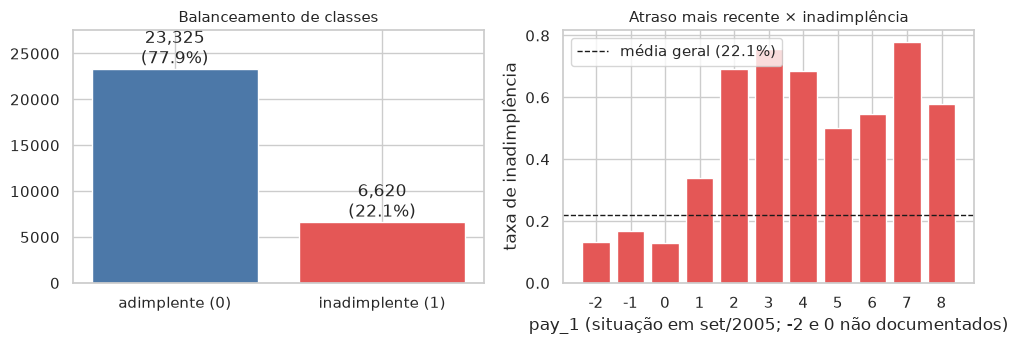

In [3]:
n_dup = int(credit_pool.duplicated().sum())
credit_df = credit_pool.drop_duplicates().reset_index(drop=True)
print(f"duplicatas removidas: {n_dup} | linhas após dedup: {len(credit_df):,}")
assert n_dup == 35

prevalence = credit_df["default"].mean()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
counts = credit_df["default"].value_counts().sort_index()
axes[0].bar(["adimplente (0)", "inadimplente (1)"], counts.to_numpy(), color=["#4c78a8", "#e45756"])
for i, v in enumerate(counts.to_numpy()):
    axes[0].text(i, v, f"{v:,}\n({v / len(credit_df):.1%})", ha="center", va="bottom")
axes[0].set_title("Balanceamento de classes")
axes[0].set_ylim(0, counts.max() * 1.18)
rate = credit_df.groupby("pay_1")["default"].agg(["mean", "size"])
axes[1].bar(rate.index.astype(str), rate["mean"], color="#e45756")
axes[1].axhline(prevalence, color="k", ls="--", lw=1, label=f"média geral ({prevalence:.1%})")
axes[1].set_xlabel("pay_1 (situação em set/2005; -2 e 0 não documentados)")
axes[1].set_ylabel("taxa de inadimplência")
axes[1].set_title("Atraso mais recente × inadimplência")
axes[1].legend()
plt.show()

**Leitura.** O desbalanceamento (≈ 22% × 78%) justifica `class_weight`, PR-AUC/F1 e um limiar escolhido por custo. A situação do pagamento mais
recente (`pay_1`) é **muito informativa**: a taxa de inadimplência é parecida (≈ 13–17%) para quem está em dia (−2, −1, 0) e salta para
≈ 34% com 1 mês de atraso e ≈ 69% com 2 meses. Por isso mantemos `pay_*` como **números** (a ordem do atraso carrega informação), inclusive os
códigos −2 e 0, que não estão no dicionário de dados mas se comportam como "sem atraso".

In [4]:
EDU_LABEL = {0: "(não doc.)", 1: "pós-graduação", 2: "universidade", 3: "ensino médio", 4: "outros", 5: "(não doc.)", 6: "(não doc.)"}
EDU_MAP = {1: "graduate", 2: "university", 3: "high_school", 4: "other", 0: "other", 5: "other", 6: "other"}
EDU_VOCAB = ("graduate", "university", "high_school", "other")

edu_tab = credit_df.groupby("education_code")["default"].agg(linhas="size", inadimplencia="mean")
edu_tab.insert(0, "significado", [EDU_LABEL[c] for c in edu_tab.index])
edu_tab["vira"] = [EDU_MAP[c] for c in edu_tab.index]
print("EDUCATION: códigos 0, 5 e 6 não são documentados; 0, 4, 5 e 6 viram `other` (4 categorias):")
show(edu_tab)
mar = credit_df.groupby("marriage")["default"].agg(linhas="size", inadimplencia="mean")
print("MARRIAGE (não vira feature; 0 não é documentado):")
show(mar)
print(f"BILL_AMT1 negativo (crédito a favor do cliente): {int((credit_df['bill_amt1'] < 0).sum())} linhas, mantidas (é informação real)")
print("PAY_1 (valores):", credit_df["pay_1"].value_counts().sort_index().to_dict())

EDUCATION: códigos 0, 5 e 6 não são documentados; 0, 4, 5 e 6 viram `other` (4 categorias):


,significado,linhas,inadimplencia,vira
education_code,,,,
0,(não doc.),14,0.0000,other
1,pós-graduação,10556,0.1921,graduate
2,universidade,14007,0.2372,university
3,ensino médio,4914,0.2515,high_school
4,outros,123,0.0569,other
5,(não doc.),280,0.0643,other
6,(não doc.),51,0.1569,other


MARRIAGE (não vira feature; 0 não é documentado):


,linhas,inadimplencia
marriage,,
0,54,0.0926
1,13633,0.2344
2,15938,0.2094
3,320,0.2562


BILL_AMT1 negativo (crédito a favor do cliente): 590 linhas, mantidas (é informação real)
PAY_1 (valores): {-2: 2749, -1: 5679, 0: 14727, 1: 3665, 2: 2662, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}


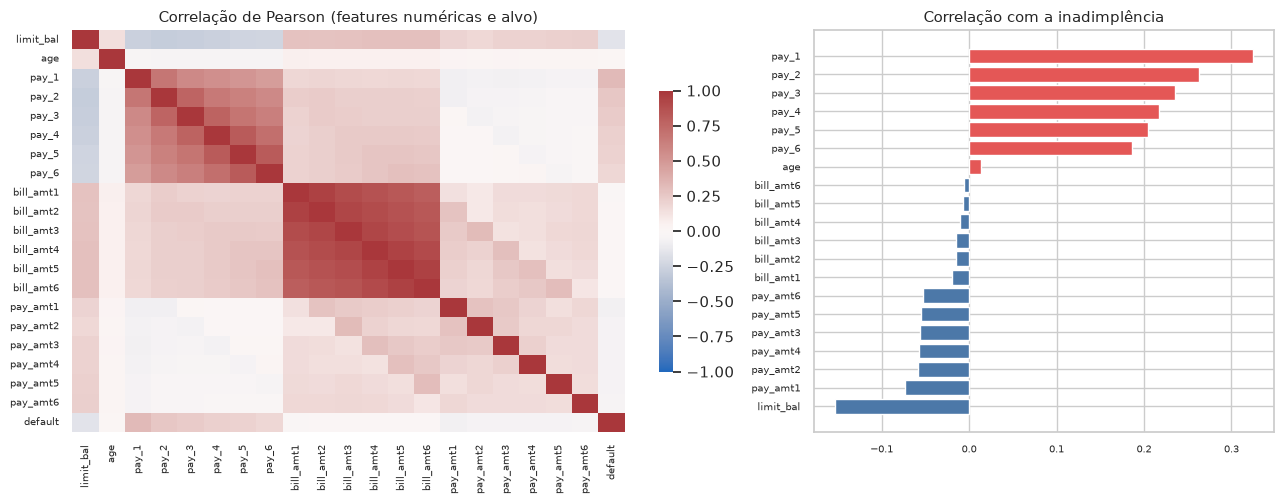

Maiores |correlação| com o alvo: pay_1 (+0.32), pay_2 (+0.26), pay_3 (+0.24), pay_4 (+0.22), pay_5 (+0.20)


In [5]:
num_cols = ["limit_bal", "age"] + [f"pay_{m}" for m in range(1, 7)] + [f"bill_amt{m}" for m in range(1, 7)] + [f"pay_amt{m}" for m in range(1, 7)]
corr = credit_df[[*num_cols, "default"]].corr()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[0], cbar_kws={"shrink": 0.7}, xticklabels=True, yticklabels=True)
axes[0].set_title("Correlação de Pearson (features numéricas e alvo)")
axes[0].tick_params(labelsize=7)
target_corr = corr["default"].drop("default").sort_values()
axes[1].barh(target_corr.index, target_corr.to_numpy(), color=np.where(target_corr.to_numpy() > 0, "#e45756", "#4c78a8"))
axes[1].set_title("Correlação com a inadimplência")
axes[1].tick_params(labelsize=7)
plt.show()
print("Maiores |correlação| com o alvo:", ", ".join(f"{k} ({v:+.2f})" for k, v in target_corr.reindex(target_corr.abs().sort_values(ascending=False).index).head(5).items()))

**Leitura.** `pay_1..pay_6` têm as maiores correlações com o alvo (a mais recente é a mais forte); as seis faturas (`bill_amt*`) são **muito correlacionadas
entre si** (a fatura de um mês é quase a do mês anterior), e o limite de crédito tem correlação **negativa** moderada (limites maiores, menos inadimplência).
A multicolinearidade entre faturas não é um problema para uma rede com `Normalization`, mas é um motivo para criar a **razão de utilização**
`bill_amt1 / limit_bal`, uma feature que o banco usaria de fato.

## 1.3 Preparação dos dados

**Preditoras e alvo.** O alvo é `default`. As features (25 colunas):
- 20 numéricas passadas como estão: `limit_bal`, `age`, `pay_1..6`, `bill_amt1..6`, `pay_amt1..6`;
- **one-hot** de `education` (4 categorias, com os códigos 0, 4, 5 e 6 reunidos em `other`);
- **razão de utilização** `bill_utilisation = bill_amt1 / limit_bal` (o denominador é sempre ≥ 10.000 neste dataset).

**`SEX` e `MARRIAGE` ficam de fora das features.** Em crédito, usar sexo ou estado civil como insumo de decisão é **discriminação por atributo protegido**:
a Regulation B / ECOA (EUA) proíbe os dois; a idade só é admitida em sistemas empiricamente derivados e sem penalizar idosos; e a **LGPD (art. 20)** dá ao titular o direito de
pedir a **revisão de decisões automatizadas** (⚠️ confirmar o texto da lei antes de citar). Mesmo sem usá-los, o modelo pode reproduzi-los por **proxies**
(por exemplo, `age` e `limit_bal`), então guardamos `sex` **apenas** para o **diagnóstico de equidade** no teste (seção 1.9).

**Divisão estratificada 70/15/15** (treino/validação/teste), com a mesma proporção de inadimplentes em cada parte. O teste só é tocado **uma vez**, no fim.

In [6]:
CREDIT_NUMERIC = num_cols
CREDIT_FEATURES = [*CREDIT_NUMERIC, *[f"education={v}" for v in EDU_VOCAB], "bill_utilisation"]
N_CREDIT = len(CREDIT_FEATURES)


def credit_feature_matrix(frame: pd.DataFrame) -> np.ndarray:
    """Linhas cruas -> matriz float32 de 25 colunas (mesma ordem do manifesto: passthrough, one-hot, razão)."""
    edu = frame["education_code"].map(EDU_MAP)
    onehot = np.stack([(edu == v).to_numpy(dtype="float64") for v in EDU_VOCAB], axis=1)
    util = (frame["bill_amt1"] / frame["limit_bal"]).to_numpy(dtype="float64")[:, None]
    return np.concatenate([frame[CREDIT_NUMERIC].to_numpy(dtype="float64"), onehot, util], axis=1).astype("float32")


idx_train, idx_rest = train_test_split(credit_df.index, test_size=0.30, stratify=credit_df["default"], random_state=SEED)
idx_val, idx_test = train_test_split(idx_rest, test_size=0.50, stratify=credit_df.loc[idx_rest, "default"], random_state=SEED)
credit_part = {"treino": idx_train, "validação": idx_val, "teste": idx_test}
print(pd.DataFrame({k: {"linhas": len(v), "inadimplentes": int(credit_df.loc[v, "default"].sum()), "taxa": credit_df.loc[v, "default"].mean()} for k, v in credit_part.items()}).T.to_string())

X_train, X_val, X_test = (credit_feature_matrix(credit_df.loc[i]) for i in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = (credit_df.loc[i, "default"].to_numpy() for i in (idx_train, idx_val, idx_test))
X_new = credit_feature_matrix(credit_new)
y_new = credit_new["default"].to_numpy()
print(f"X_train {X_train.shape} | X_val {X_val.shape} | X_test {X_test.shape} | novas {X_new.shape}")

               linhas  inadimplentes   taxa
treino    20,961.0000     4,634.0000 0.2211
validação  4,492.0000       993.0000 0.2211
teste      4,492.0000       993.0000 0.2211
X_train (20961, 25) | X_val (4492, 25) | X_test (4492, 25) | novas (20, 25)


## 1.4 Normalização (obrigatória), em célula visível

As colunas têm escalas muito diferentes (`limit_bal` na casa de 10⁵, `pay_*` entre −2 e 8, a razão de utilização entre 0 e ~1). Redes treinadas por
gradiente convergem muito melhor com entradas de **média 0 e desvio 1**. Usamos a camada `tf.keras.layers.Normalization`: `adapt()` calcula média e variância
**só no treino** (sem vazar informação de validação/teste) e a camada fica **embutida no modelo** (a API recebe valores brutos).

,média (antes),desvio (antes),média (depois),desvio (depois),média val. (depois)
limit_bal,"167,938.7344","129,765.0703",0.0001,1.0000,-0.0207
age,35.4934,9.2063,0.0000,1.0000,-0.0050
pay_1,-0.0193,1.1174,-0.0000,1.0000,0.0031
pay_2,-0.1335,1.1916,-0.0000,1.0000,0.0076
pay_3,-0.1672,1.1906,-0.0000,0.9999,0.0174
pay_4,-0.2196,1.1661,-0.0000,0.9999,0.0073
pay_5,-0.2653,1.1299,-0.0000,0.9999,-0.0008
pay_6,-0.2888,1.1472,0.0000,1.0000,-0.0021
bill_amt1,"51,586.2852","73,699.4375",0.0000,1.0000,-0.0192
bill_amt2,"49,548.9570","71,270.0078",0.0000,1.0000,-0.0142


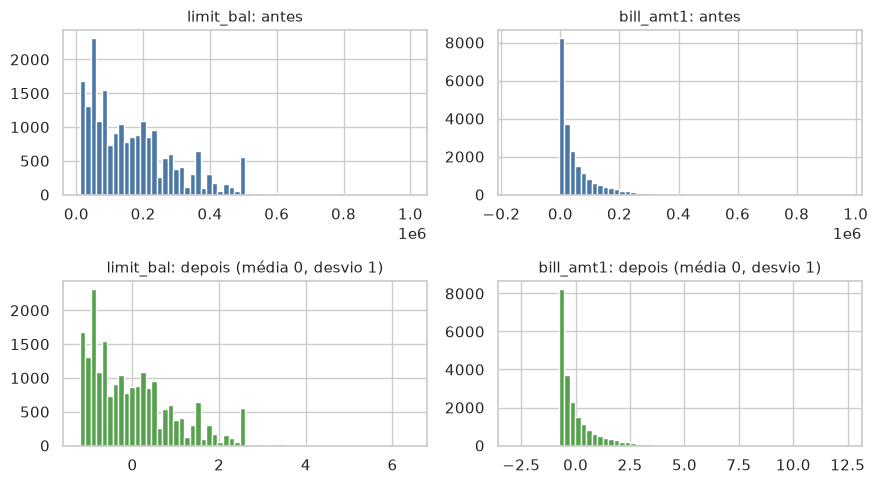

In [7]:
norm_layer = layers.Normalization(axis=-1, name="norm")
norm_layer.adapt(X_train)
norm_mean = np.asarray(norm_layer.mean).reshape(-1)
norm_var = np.asarray(norm_layer.variance).reshape(-1)
Z_train = norm_layer(X_train).numpy()
Z_val = norm_layer(X_val).numpy()
norm_table = pd.DataFrame(
    {
        "média (antes)": X_train.mean(axis=0),
        "desvio (antes)": X_train.std(axis=0),
        "média (depois)": Z_train.mean(axis=0),
        "desvio (depois)": Z_train.std(axis=0),
        "média val. (depois)": Z_val.mean(axis=0),
    },
    index=CREDIT_FEATURES,
)
show(norm_table)
fig, axes = plt.subplots(2, 2, figsize=(9, 5))
for j, name in enumerate(["limit_bal", "bill_amt1"]):
    k = CREDIT_FEATURES.index(name)
    axes[0, j].hist(X_train[:, k], bins=60, color="#4c78a8")
    axes[0, j].set_title(f"{name}: antes")
    axes[1, j].hist(Z_train[:, k], bins=60, color="#54a24b")
    axes[1, j].set_title(f"{name}: depois (média 0, desvio 1)")
plt.show()

**Leitura.** Depois do `adapt`, todas as colunas do **treino** têm média ≈ 0 e desvio ≈ 1; na **validação** a média fica perto de 0 mas não exatamente, e é assim
que deve ser (os parâmetros vêm só do treino). A forma das distribuições não muda (continuam assimétricas, com cauda longa): a normalização muda a **escala**, não a forma.
Outras preparações: remoção de duplicatas, reunião de categorias raras/inválidas de `education`, *one-hot* e a razão de utilização. Não há valores ausentes, então
**não há imputação** (e a API exige todos os campos).

## 1.5 Ablação manual: largura × profundidade × `class_weight` (3 seeds cada)

Em vez de um *tuner*, uma **grade pequena e explícita**, para a escolha ficar **rastreável**:
1. **Largura × profundidade:** largura da 1ª camada oculta ∈ {16, 32, 64, 128} × profundidade ∈ {1, 2, 3} camadas ocultas (cada camada tem a **metade** dos neurônios da anterior, formato de funil, e
   `Dropout(0,2)` depois de cada uma), com `class_weight` balanceado, **3 seeds** por configuração;
2. **Com × sem `class_weight`** na arquitetura escolhida em (1), também com 3 seeds.

Treino por Adam (1e-3), lotes de 512, *early stopping* na **PR-AUC de validação** (a métrica que importa em classe rara) com `restore_best_weights`.
A decisão usa a **validação** (PR-AUC como critério principal; F1 como desempate).

In [8]:
Y_train_oh = keras.utils.to_categorical(y_train, 2)
Y_val_oh = keras.utils.to_categorical(y_val, 2)
_n = np.bincount(y_train)
class_weight = {0: len(y_train) / (2 * _n[0]), 1: len(y_train) / (2 * _n[1])}  # "balanceado": n / (2 n_c)
print(f"class_weight balanceado: {{0: {class_weight[0]:.3f}, 1: {class_weight[1]:.3f}}}")


def build_credit_mlp(width: int, depth: int, dropout: float = 0.2, name: str = "credit_mlp") -> keras.Model:
    """Camada a camada: Input -> Normalization (estatística do treino) -> [Dense(relu) -> Dropout] x depth -> Dense(2, softmax)."""
    inputs = keras.Input(shape=(N_CREDIT,), name="features")
    x = layers.Normalization(axis=-1, mean=norm_mean, variance=norm_var, name="norm")(inputs)
    for i in range(depth):
        x = layers.Dense(max(8, width // 2**i), activation="relu", name=f"dense_{i}")(x)
        x = layers.Dropout(dropout, name=f"dropout_{i}")(x)
    outputs = layers.Dense(2, activation="softmax", name="out")(x)
    return keras.Model(inputs, outputs, name=name)


class ValidationScores(keras.callbacks.Callback):
    """Calcula PR-AUC e ROC-AUC na validação a cada época (entram em ``logs`` para o EarlyStopping)."""

    def __init__(self, x, y):
        super().__init__()
        self.x, self.y = x, y

    def on_epoch_end(self, epoch, logs=None):
        p = self.model(self.x, training=False).numpy()[:, 1]
        logs["val_pr_auc"] = average_precision_score(self.y, p)
        logs["val_roc_auc"] = roc_auc_score(self.y, p)


def best_f1(y_true, p) -> tuple[float, float]:
    """Maior F1 sobre todos os limiares (e o limiar), para comparar modelos sem depender do corte 0,5."""
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    k = int(np.argmax(f1[:-1]))
    return float(f1[k]), float(thr[k])


def fit_credit(width: int, depth: int, seed: int, use_cw: bool, max_epochs: int = 40, patience: int = 6):
    set_seed(seed)
    model = build_credit_mlp(width, depth)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"], jit_compile=False)
    callbacks = [
        ValidationScores(X_val, y_val),
        keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=patience, restore_best_weights=True),
    ]
    history = model.fit(
        X_train, Y_train_oh, validation_data=(X_val, Y_val_oh), epochs=max_epochs, batch_size=512,
        class_weight=class_weight if use_cw else None, callbacks=callbacks, verbose=0,
    )  # fmt: skip
    return model, history


def credit_run(width: int, depth: int, seed: int, use_cw: bool) -> dict:
    t1 = time.time()
    m, h = fit_credit(width, depth, seed, use_cw)
    p = m.predict(X_val, batch_size=4096, verbose=0)[:, 1]
    f1_best, _ = best_f1(y_val, p)
    return {"class_weight": use_cw, "depth": depth, "width": width, "seed": seed, "params": m.count_params(),
            "val_pr_auc": average_precision_score(y_val, p), "val_roc_auc": roc_auc_score(y_val, p),
            "val_f1_05": f1_score(y_val, p >= 0.5), "val_f1_best": f1_best, "epochs": len(h.history["loss"]), "seconds": time.time() - t1}  # fmt: skip


_rows = []
_t0 = time.time()
for depth in (1, 2, 3):
    for width in (16, 32, 64, 128):
        _rows += [credit_run(width, depth, seed, True) for seed in (1, 2, 3)]
    print(f"  profundidade {depth} pronta ({time.time() - _t0:.0f}s)", flush=True)
credit_abl_grid = pd.DataFrame(_rows)
keras.backend.clear_session()

class_weight balanceado: {0: 0.642, 1: 2.262}


  profundidade 1 pronta (58s)


  profundidade 2 pronta (118s)


  profundidade 3 pronta (179s)


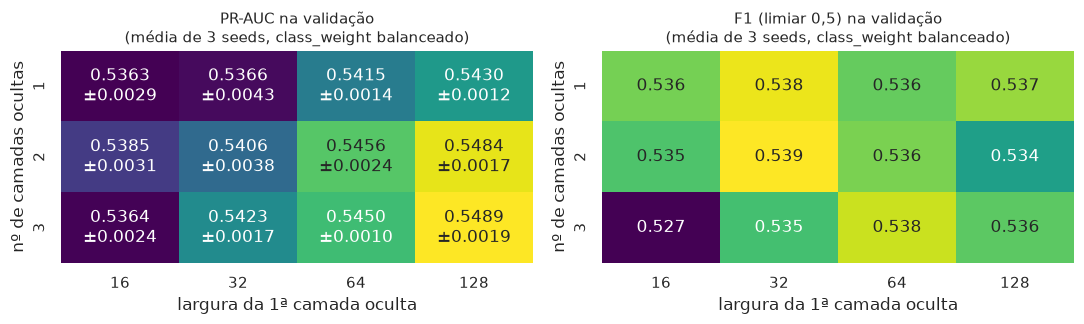

,depth,width,params,pr_auc,pr_auc_std,roc_auc,f1_05,f1_best,epochs,se
11,3,128,13730,0.5489,0.0019,0.7785,0.5358,0.5455,26.6667,0.0011
7,2,128,11714,0.5484,0.0017,0.7783,0.5337,0.5442,28.0000,0.0010
6,2,64,3810,0.5456,0.0024,0.7786,0.5364,0.5445,31.6667,0.0014
10,3,64,4306,0.5450,0.0010,0.7770,0.5377,0.5432,33.3333,0.0006
3,1,128,3586,0.5430,0.0012,0.7773,0.5369,0.5472,27.3333,0.0007
9,3,32,1514,0.5423,0.0017,0.7759,0.5352,0.5402,34.3333,0.0010


melhor PR-AUC: 0.5489 (largura 128, profundidade 3, EP 0.0011) -> regra do 1 EP: largura 128, profundidade 2 (11,714 parâmetros)


In [9]:
agg = (
    credit_abl_grid.groupby(["depth", "width"])
    .agg(params=("params", "first"), pr_auc=("val_pr_auc", "mean"), pr_auc_std=("val_pr_auc", "std"), roc_auc=("val_roc_auc", "mean"),
         f1_05=("val_f1_05", "mean"), f1_best=("val_f1_best", "mean"), epochs=("epochs", "mean"))
    .reset_index()
)  # fmt: skip
agg["se"] = agg["pr_auc_std"] / np.sqrt(3)
top = agg.loc[agg["pr_auc"].idxmax()]
near = agg[agg["pr_auc"] >= top["pr_auc"] - top["se"]]  # regra do 1 erro-padrão: a configuração mais simples dentro do ruído da melhor
chosen = near.sort_values(["params", "pr_auc"], ascending=[True, False]).iloc[0]
CREDIT_WIDTH, CREDIT_DEPTH = int(chosen["width"]), int(chosen["depth"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, col, scol, title in zip(axes, ("pr_auc", "f1_05"), ("pr_auc_std", None), ("PR-AUC na validação", "F1 (limiar 0,5) na validação"), strict=True):
    mean = agg.pivot(index="depth", columns="width", values=col)
    if scol:
        std = agg.pivot(index="depth", columns="width", values=scol)
        labels = mean.map("{:.4f}".format) + "\n±" + std.map("{:.4f}".format)
    else:
        labels = mean.map("{:.3f}".format)
    sns.heatmap(mean, annot=labels, fmt="", cmap="viridis", ax=ax, cbar=False)
    ax.set_title(f"{title}\n(média de 3 seeds, class_weight balanceado)")
    ax.set_xlabel("largura da 1ª camada oculta")
    ax.set_ylabel("nº de camadas ocultas")
plt.show()
show(agg.sort_values("pr_auc", ascending=False).head(6))
print(f"melhor PR-AUC: {top['pr_auc']:.4f} (largura {int(top['width'])}, profundidade {int(top['depth'])}, EP {top['se']:.4f}) -> regra do 1 EP: largura {CREDIT_WIDTH}, profundidade {CREDIT_DEPTH} ({int(chosen['params']):,} parâmetros)")

In [10]:
# class_weight: com x sem, na arquitetura escolhida (3 seeds cada). A configuração "com" já foi treinada na grade.
_rows = [credit_run(CREDIT_WIDTH, CREDIT_DEPTH, seed, False) for seed in (1, 2, 3)]
keras.backend.clear_session()
credit_abl = pd.concat([credit_abl_grid, pd.DataFrame(_rows)], ignore_index=True)
cw_cmp = credit_abl[(credit_abl["width"] == CREDIT_WIDTH) & (credit_abl["depth"] == CREDIT_DEPTH)].groupby("class_weight")[["val_pr_auc", "val_roc_auc", "val_f1_05", "val_f1_best"]].agg(["mean", "std"])
show(cw_cmp)
_pr = credit_abl[(credit_abl["width"] == CREDIT_WIDTH) & (credit_abl["depth"] == CREDIT_DEPTH)].groupby("class_weight")
_m, _s = _pr["val_pr_auc"].mean(), _pr["val_pr_auc"].std() / np.sqrt(3)
_tie = abs(_m[True] - _m[False]) <= max(_s[True], _s[False])  # empate em PR-AUC (dentro de 1 EP) -> desempata pelo F1 em 0,5
_f1 = _pr["val_f1_05"].mean()
use_class_weight = bool(_f1[True] >= _f1[False]) if _tie else bool(_m[True] > _m[False])
print(f"PR-AUC: com {_m[True]:.4f} × sem {_m[False]:.4f} | empate dentro de 1 EP: {_tie} | F1(0,5): com {_f1[True]:.4f} × sem {_f1[False]:.4f}")
print(f"DECISÃO: class_weight = {use_class_weight} | 1ª camada = {CREDIT_WIDTH} neurônios | {CREDIT_DEPTH} camada(s) oculta(s)")
print(f"{len(credit_abl)} treinos na ablação, {credit_abl['seconds'].sum() / 60:.1f} min no total")

val_pr_auc        val_roc_auc        val_f1_05        val_f1_best       
                   mean    std        mean    std      mean    std        mean    std
class_weight                                                                         
False            0.5563 0.0028      0.7785 0.0019    0.4672 0.0014      0.5408 0.0029
True             0.5484 0.0017      0.7783 0.0018    0.5337 0.0052      0.5442 0.0021

PR-AUC: com 0.5484 × sem 0.5563 | empate dentro de 1 EP: False | F1(0,5): com 0.5337 × sem 0.4672
DECISÃO: class_weight = False | 1ª camada = 128 neurônios | 2 camada(s) oculta(s)
39 treinos na ablação, 3.3 min no total


**Leitura da ablação.** O heatmap mostra que a PR-AUC de validação varia **pouco** (de ≈ 0,536 a ≈ 0,549, cerca de 1,3 ponto percentual) em toda a grade: o problema
é **tabular, de baixa dimensão e com sinal concentrado em `pay_*`**, então redes pequenas já capturam quase tudo. A **largura** da primeira camada ajuda um pouco (16 → 128 neurônios) e a
**profundidade** quase nada; o ganho de 2 para 3 camadas está dentro do ruído entre seeds. Por isso a regra é a do **1 erro-padrão** (a configuração mais simples dentro do ruído da melhor),
que também reduz o risco de *overfitting* e o custo de inferência. A decisão sobre `class_weight` foi tomada **na validação** (linhas impressas acima): a PR-AUC não depende do limiar e
ficou **mais alta sem** `class_weight`, enquanto o F1 em 0,5 premia o `class_weight` só porque ele desloca as probabilidades para cima (o mesmo efeito se obtém movendo o limiar, seção 1.8).

## 1.6 Modelo final, camada a camada, e justificativas

```
Input(25) → Normalization → [Dense(w, relu) → Dropout(0,2)] × profundidade → Dense(2, softmax)
```

### Justificativa: Arquitetura (Rede 1)
- **Ativação das ocultas: ReLU.** É barata, não satura para entradas positivas (evita o gradiente que some de `sigmoid`/`tanh` em redes mais profundas), converge rápido
  e é o padrão em MLPs tabulares. Como a entrada já está padronizada, a "metade morta" da ReLU não é um problema e `Dropout(0,2)` regulariza. (`tanh` e `sigmoid` foram descartadas
  por saturar; `softmax` só faz sentido na saída.)
- **Profundidade × largura:** a **grade da seção 1.5** (heatmap, 3 seeds) e a regra do 1 erro-padrão escolheram a configuração impressa acima. O ganho de mais camadas/neurônios foi
  pequeno (≈ 1 ponto percentual de PR-AUC entre a menor e a maior rede), então mantemos a **menor rede indistinguível da melhor**.
- **Saída: `Dense(2, softmax)`.** As duas classes são **mutuamente exclusivas**; o softmax devolve uma distribuição de probabilidade (`p(adimplente)`, `p(inadimplente)`) que soma 1 e
  casa com a `categorical_crossentropy`. (Uma saída única com `sigmoid` seria equivalente; usamos dois neurônios por consistência com a matriz de confusão e com os rótulos one-hot.)

### Justificativa: Compilação (Rede 1)
- **Loss: `categorical_crossentropy`** (rótulos one-hot): é a log-verossimilhança da distribuição prevista, penaliza com força previsões confiantes erradas e produz probabilidades
  utilizáveis para escolher limiar e medir calibração. **Desbalanceamento (≈ 22%):** foi tratado de duas formas, `class_weight` balanceado (testado na ablação, seção 1.5) e **limiar de decisão por custo**
  (seção 1.8). Na validação, `class_weight` **não melhorou a PR-AUC** (ficou ligeiramente abaixo) e deslocou as probabilidades para cima, e como o limiar por custo já resolve o compromisso entre precisão
  e revocação, o modelo final usa a decisão impressa na ablação (ver a linha `DECISÃO`).
- **Taxa de aprendizado: Adam com 1e-3.** É o valor padrão de Adam, estável para MLPs com entrada padronizada; as curvas (seção 1.7) mostram descida suave sem oscilação, e o *early stopping*
  pela PR-AUC de validação interrompe antes do *overfitting* (restaurando os melhores pesos).
- **Métricas:** acompanhamos `accuracy` (só como referência: ≈ 78% é o piso "sempre adimplente") e, principalmente, **PR-AUC** (área sob a curva precisão × revocação), que **não depende do limiar**,
  **não é inflada pela classe majoritária** e mede o que importa em classe rara: achar os inadimplentes sem alarmes demais. F1 e ROC-AUC são complementares; KS e Brier entram na avaliação final.

In [11]:
set_seed(SEED)
credit_model = build_credit_mlp(CREDIT_WIDTH, CREDIT_DEPTH, name="credit_default_mlp")
credit_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"], jit_compile=False)
credit_model.summary()

Model: "credit_default_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm (Normalization)            │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_0 (Dense)                 │ (None, 128)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_0 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ out (Dense)                     │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,714 (45.76 KB)

 Trainable params: 11,714 (45.76 KB)

 Non-trainable params: 0 (0.00 B)

## 1.7 Treino final e curvas

Treino com os dados de treino e **monitoramento na validação**. O `EarlyStopping` (PR-AUC de validação, paciência 10) restaura os melhores pesos.

75 épocas em 11s | melhor época (PR-AUC de validação): 65 | PR-AUC val = 0.5607


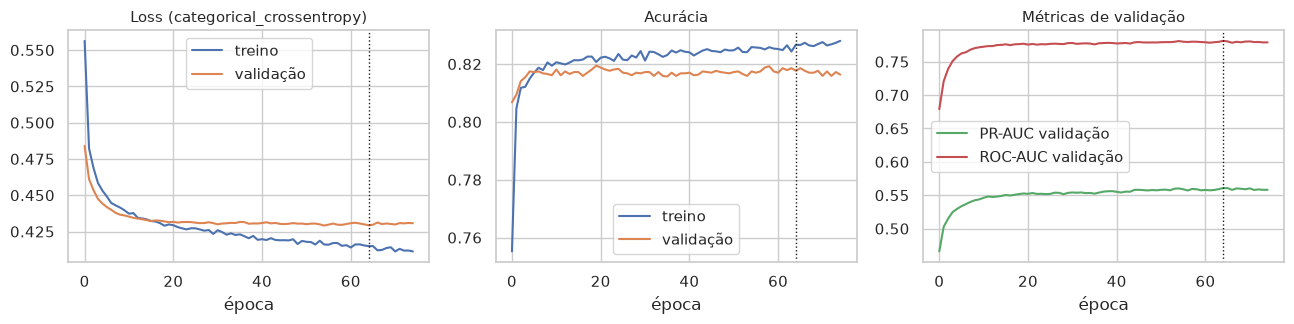

In [12]:
_t1 = time.time()
credit_hist = credit_model.fit(
    X_train, Y_train_oh, validation_data=(X_val, Y_val_oh), epochs=100, batch_size=512,
    class_weight=class_weight if use_class_weight else None,
    callbacks=[ValidationScores(X_val, y_val), keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=10, restore_best_weights=True)],
    verbose=0,
)  # fmt: skip
credit_train_seconds = time.time() - _t1
hist = pd.DataFrame(credit_hist.history)
best_epoch = int(hist["val_pr_auc"].idxmax()) + 1
print(f"{len(hist)} épocas em {credit_train_seconds:.0f}s | melhor época (PR-AUC de validação): {best_epoch} | PR-AUC val = {hist['val_pr_auc'].max():.4f}")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(hist["loss"], label="treino")
axes[0].plot(hist["val_loss"], label="validação")
axes[0].set_title("Loss (categorical_crossentropy)")
axes[1].plot(hist["accuracy"], label="treino")
axes[1].plot(hist["val_accuracy"], label="validação")
axes[1].set_title("Acurácia")
axes[2].plot(hist["val_pr_auc"], color="C2", label="PR-AUC validação")
axes[2].plot(hist["val_roc_auc"], color="C3", label="ROC-AUC validação")
axes[2].set_title("Métricas de validação")
for ax in axes:
    ax.axvline(best_epoch - 1, color="k", ls=":", lw=1)
    ax.set_xlabel("época")
    ax.legend()
plt.show()

**Leitura.** A descida inicial é rápida e suave (sem oscilação com Adam 1e-3). A loss de treino continua caindo devagar enquanto a de validação **estaciona** em torno de 0,43 e a
distância entre as duas cresce: sinal de *overfitting* **leve** (a rede é pequena e há `Dropout`). A acurácia de validação fica em ≈ 0,82, acima do piso de 78% da classe majoritária, e a
ROC-AUC/PR-AUC de validação ficam praticamente planas depois de ≈ 20 épocas. O `EarlyStopping` (linha pontilhada = melhor PR-AUC de validação) restaura os pesos dessa época;
como a diferença entre as épocas finais é minúscula, a escolha do ponto de parada importa pouco aqui.

## 1.8 Limiar de decisão pelo custo (escolhido na validação)

O corte 0,5 não tem nada de especial em classe desbalanceada. Em crédito, **os dois erros custam diferente**: conceder crédito a quem não paga (falso negativo, FN) custa muito mais
do que recusar um bom cliente (falso positivo, FP). Adotamos, como **premissa ilustrativa e explícita** (não é um custo real de banco), **custo(FN) = 5 × custo(FP)**, e escolhemos na
**validação** o limiar que minimiza o custo total. O teste só entra depois, com o limiar já fixado.

limiar por custo (validação): 0.175 | custo/cliente: 0.5419
limiar 0,5 (validação):         0.500 | custo/cliente: 0.7353
aprovar todos (validação):             custo/cliente: 1.1053


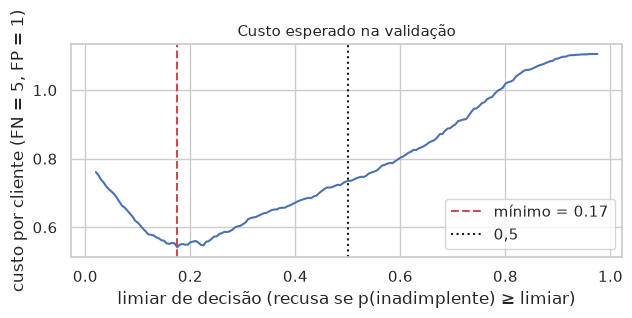

In [13]:
COST_FN, COST_FP = 5.0, 1.0  # premissa ilustrativa: um inadimplente aprovado custa 5x um bom cliente recusado


def expected_cost(y_true, p, threshold) -> float:
    pred = p >= threshold
    fn = int(((~pred) & (y_true == 1)).sum())
    fp = int((pred & (y_true == 0)).sum())
    return (COST_FN * fn + COST_FP * fp) / len(y_true)


p_val = credit_model.predict(X_val, batch_size=4096, verbose=0)[:, 1]
grid = np.round(np.arange(0.02, 0.98, 0.005), 3)
val_costs = np.array([expected_cost(y_val, p_val, t) for t in grid])
credit_threshold = float(np.median(grid[val_costs == val_costs.min()]))
print(f"limiar por custo (validação): {credit_threshold:.3f} | custo/cliente: {expected_cost(y_val, p_val, credit_threshold):.4f}")
print(f"limiar 0,5 (validação):         0.500 | custo/cliente: {expected_cost(y_val, p_val, 0.5):.4f}")
print(f"aprovar todos (validação):             custo/cliente: {COST_FN * y_val.mean():.4f}")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(grid, val_costs, color="C0")
ax.axvline(credit_threshold, color="C3", ls="--", label=f"mínimo = {credit_threshold:.2f}")
ax.axvline(0.5, color="k", ls=":", label="0,5")
ax.set_xlabel("limiar de decisão (recusa se p(inadimplente) ≥ limiar)")
ax.set_ylabel("custo por cliente (FN = 5, FP = 1)")
ax.set_title("Custo esperado na validação")
ax.legend()
plt.show()

## 1.9 Avaliação no teste (tocado uma única vez)

Calculamos tudo de uma vez: **matriz de confusão** (com a diagonal destacada) e **relatório de classificação** nos dois limiares (0,5 e o escolhido por custo),
além de ROC-AUC, PR-AUC, **KS**, Brier e calibração, tudo comparado com os **baselines** (classe majoritária e regressão logística treinada no mesmo treino).

In [14]:
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

TARGET_NAMES = ["adimplente (0)", "inadimplente (1)"]
p_test = credit_model.predict(X_test, batch_size=4096, verbose=0)[:, 1]

# baselines treinados no MESMO treino; limiar do baseline logístico escolhido na validação pela mesma regra de custo
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced" if use_class_weight else None))
lr.fit(X_train, y_train)
p_lr_val, p_lr_test = lr.predict_proba(X_val)[:, 1], lr.predict_proba(X_test)[:, 1]
lr_costs = np.array([expected_cost(y_val, p_lr_val, t) for t in grid])
lr_threshold = float(np.median(grid[lr_costs == lr_costs.min()]))


def ks_statistic(y_true, p) -> float:
    fpr, tpr, _ = roc_curve(y_true, p)
    return float(np.max(tpr - fpr))


def score_row(name, y_true, p, threshold) -> dict:
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "modelo": name, "limiar": threshold, "acurácia": (tp + tn) / len(y_true),
        "precisão (1)": tp / max(tp + fp, 1), "revocação (1)": tp / max(tp + fn, 1), "F1 (1)": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, p) if np.ptp(p) > 0 else 0.5, "PR-AUC": average_precision_score(y_true, p),
        "KS": ks_statistic(y_true, p) if np.ptp(p) > 0 else 0.0, "Brier": brier_score_loss(y_true, p),
        "custo/cliente": expected_cost(y_true, p, threshold),
    }  # fmt: skip


p_major = np.zeros(len(y_test))  # classe majoritária: sempre p(inadimplente) = 0
rows = [
    score_row("maioria (sempre adimplente)", y_test, p_major, 0.5),
    score_row("regressão logística (0,5)", y_test, p_lr_test, 0.5),
    score_row("regressão logística (custo)", y_test, p_lr_test, lr_threshold),
    score_row("MLP (0,5)", y_test, p_test, 0.5),
    score_row("MLP (limiar por custo)", y_test, p_test, credit_threshold),
]
credit_test_table = pd.DataFrame(rows).set_index("modelo")
show(credit_test_table)
print(f"custo/cliente se aprovar todos: {COST_FN * y_test.mean():.4f} (FN = {COST_FN:g} × FP)")

,limiar,acurácia,precisão (1),revocação (1),F1 (1),ROC-AUC,PR-AUC,KS,Brier,custo/cliente
modelo,,,,,,,,,,
maioria (sempre adimplente),0.5000,0.7789,0.0000,0.0000,0.0000,0.5000,0.2211,0.0000,0.2211,1.1053
"regressão logística (0,5)",0.5000,0.8090,0.7003,0.2377,0.3549,0.7186,0.4897,0.3686,0.1463,0.8651
regressão logística (custo),0.2300,0.7171,0.4051,0.5972,0.4827,0.7186,0.4897,0.3686,0.1463,0.6391
"MLP (0,5)",0.5000,0.8201,0.6609,0.3827,0.4847,0.7714,0.5390,0.4151,0.1370,0.7257
MLP (limiar por custo),0.1750,0.6371,0.3521,0.7633,0.4819,0.7714,0.5390,0.4151,0.1370,0.5721


custo/cliente se aprovar todos: 1.1053 (FN = 5 × FP)


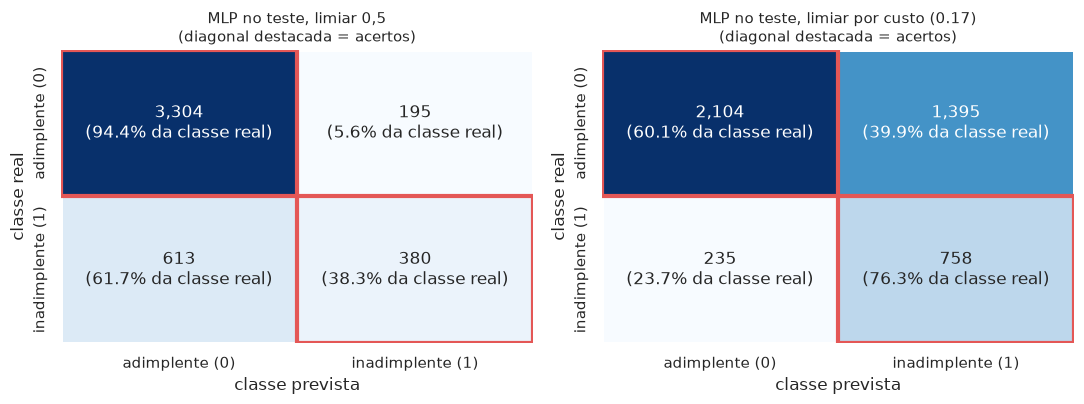

--- Relatório de classificação (teste, limiar 0,5) ---
                  precision    recall  f1-score   support

  adimplente (0)      0.844     0.944     0.891      3499
inadimplente (1)      0.661     0.383     0.485       993

        accuracy                          0.820      4492
       macro avg      0.752     0.663     0.688      4492
    weighted avg      0.803     0.820     0.801      4492

--- Relatório de classificação (teste, limiar por custo (0.17)) ---
                  precision    recall  f1-score   support

  adimplente (0)      0.900     0.601     0.721      3499
inadimplente (1)      0.352     0.763     0.482       993

        accuracy                          0.637      4492
       macro avg      0.626     0.682     0.601      4492
    weighted avg      0.779     0.637     0.668      4492



In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, thr, title in zip(axes, (0.5, credit_threshold), ("limiar 0,5", f"limiar por custo ({credit_threshold:.2f})"), strict=True):
    cm = confusion_matrix(y_test, (p_test >= thr).astype(int), labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cm[i, j]:,}\n({pct[i, j]:.1%} da classe real)" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax, xticklabels=TARGET_NAMES, yticklabels=TARGET_NAMES, linewidths=1, linecolor="white")
    for i in range(2):  # destaca a diagonal (acertos)
        ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor="#e45756", lw=3))
    ax.set_xlabel("classe prevista")
    ax.set_ylabel("classe real")
    ax.set_title(f"MLP no teste, {title}\n(diagonal destacada = acertos)")
plt.show()
for thr, title in ((0.5, "limiar 0,5"), (credit_threshold, f"limiar por custo ({credit_threshold:.2f})")):
    print(f"--- Relatório de classificação (teste, {title}) ---")
    print(classification_report(y_test, (p_test >= thr).astype(int), target_names=TARGET_NAMES, digits=3))

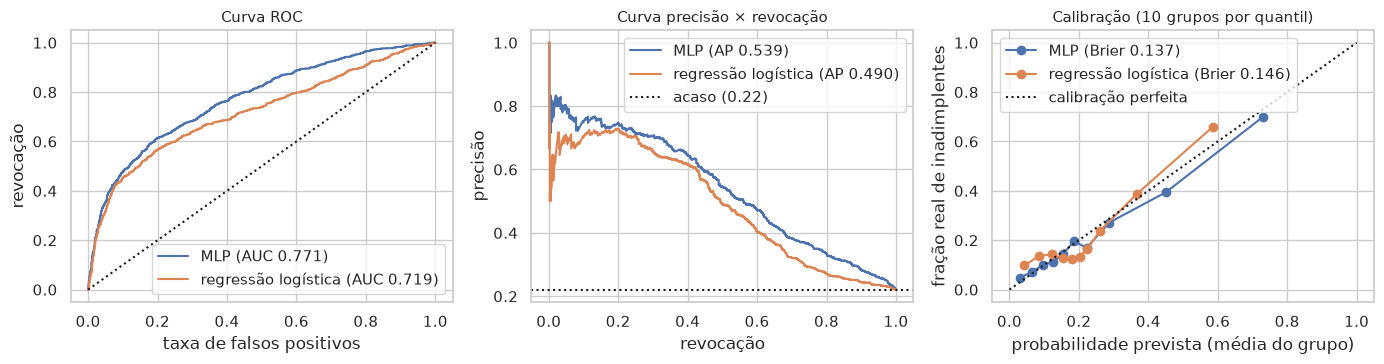

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for name, p, color in (("MLP", p_test, "C0"), ("regressão logística", p_lr_test, "C1")):
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=color, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=color, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    axes[2].plot(mean_pred, frac_pos, "o-", color=color, label=f"{name} (Brier {brier_score_loss(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k:")
axes[0].set(xlabel="taxa de falsos positivos", ylabel="revocação", title="Curva ROC")
axes[1].axhline(y_test.mean(), color="k", ls=":", label=f"acaso ({y_test.mean():.2f})")
axes[1].set(xlabel="revocação", ylabel="precisão", title="Curva precisão × revocação")
axes[2].plot([0, 1], [0, 1], "k:", label="calibração perfeita")
axes[2].set(xlabel="probabilidade prevista (média do grupo)", ylabel="fração real de inadimplentes", title="Calibração (10 grupos por quantil)")
for ax in axes:
    ax.legend()
plt.show()

**Leitura.**
- A **classe majoritária** acerta ~78% e **nunca** detecta um inadimplente (revocação 0): o piso que mostra por que a acurácia engana.
- A **regressão logística** é um baseline forte em dados tabulares de baixa dimensão, e o MLP foi comparado a ela com honestidade: no teste o MLP fica **à frente nas métricas que não dependem do limiar**
  (ROC-AUC ≈ 0,77 × 0,72; PR-AUC ≈ 0,54 × 0,49; KS ≈ 0,42 × 0,37), um ganho **moderado mas consistente**; é um problema em que a rede ajuda, sem milagre (a PR-AUC de 0,54 ainda está longe de 1).
- O **limiar por custo** troca precisão por revocação: com FN custando 5× FP, vale aceitar mais alarmes falsos para deixar escapar menos inadimplentes (revocação ≈ 0,38 → 0,76, às custas da precisão). A coluna `custo/cliente`
  mostra o ganho: o MLP no limiar por custo (≈ 0,57) é melhor que o mesmo MLP em 0,5 (≈ 0,73), que a regressão logística no seu limiar de custo (≈ 0,64) e que **aprovar todos** (≈ 1,11).
- **Calibração:** a curva de calibração (painel da direita) compara a probabilidade prevista com a fração real de inadimplentes em 10 grupos. Sem `class_weight` as probabilidades do MLP ficam próximas da
  diagonal e o **Brier** do MLP (≈ 0,137) é menor que o da regressão logística (≈ 0,146); se `class_weight` tivesse sido usado, elas ficariam **infladas** (o modelo veria a classe rara como mais comum) e não poderiam
  ser lidas como risco absoluto sem recalibrar (Platt/isotônica na validação). Ranquear e decidir por limiar não depende disso, mas **comunicar um risco em %** depende. Nos grupos de maior risco (poucos clientes) a
  curva se afasta um pouco da diagonal: a leitura ali é ruidosa.

### Diagnóstico de equidade por sexo (no teste)

`sex` **não é feature**, mas o modelo pode ser desigual por *proxies*. Comparamos os dois grupos no teste, ao limiar por custo: **taxa de aprovação** (fração com p < limiar), **TPR** (inadimplentes que o modelo
consegue sinalizar) e **FPR** (bons clientes sinalizados por engano). **Ressalva:** são dados de Taiwan, 2005; o diagnóstico mede diferenças de **taxa**, não prova nem descarta discriminação, e não substitui uma análise jurídica.

In [17]:
sex_test = credit_df.loc[idx_test, "sex"].map({1: "masculino", 2: "feminino"}).to_numpy()
pred_cost = (p_test >= credit_threshold).astype(int)
fair_rows = []
for grp in ("masculino", "feminino"):
    m = sex_test == grp
    tn, fp, fn, tp = confusion_matrix(y_test[m], pred_cost[m], labels=[0, 1]).ravel()
    fair_rows.append({"grupo": grp, "clientes": int(m.sum()), "inadimplência real": y_test[m].mean(), "taxa de aprovação": float((pred_cost[m] == 0).mean()),
                      "TPR (revocação)": tp / max(tp + fn, 1), "FPR": fp / max(fp + tn, 1), "PR-AUC": average_precision_score(y_test[m], p_test[m])})  # fmt: skip
fair = pd.DataFrame(fair_rows).set_index("grupo")
show(fair)
di = fair.loc["feminino", "taxa de aprovação"] / fair.loc["masculino", "taxa de aprovação"]
print(f"razão de aprovação (feminino/masculino): {di:.3f} | diferença de TPR: {fair.loc['feminino', 'TPR (revocação)'] - fair.loc['masculino', 'TPR (revocação)']:+.3f} | diferença de FPR: {fair.loc['feminino', 'FPR'] - fair.loc['masculino', 'FPR']:+.3f}")
print("Regra prática dos 4/5 (razão de aprovação >= 0,80):", "atendida" if di >= 0.8 else "NÃO atendida")

,clientes,inadimplência real,taxa de aprovação,TPR (revocação),FPR,PR-AUC
grupo,,,,,,
masculino,1757,0.2362,0.4952,0.7880,0.4173,0.5398
feminino,2735,0.2113,0.5371,0.7457,0.3871,0.5397


razão de aprovação (feminino/masculino): 1.085 | diferença de TPR: -0.042 | diferença de FPR: -0.030
Regra prática dos 4/5 (razão de aprovação >= 0,80): atendida


**Leitura.** No teste, a taxa de aprovação das mulheres é ≈ 8% **maior** que a dos homens (razão ≈ 1,09, acima do piso de 0,80 da regra dos 4/5), e a **TPR** e a **FPR** são ligeiramente **menores** para elas
(diferenças de poucos pontos percentuais): o modelo recusa um pouco **mais** os homens, e isso acompanha a **diferença real de inadimplência** (≈ 23,6% contra 21,1%) que os dados contêm, e não só o modelo. A PR-AUC é igual
nos dois grupos (≈ 0,54), isto é, o modelo ranqueia igualmente bem; já a **FPR** (≈ 0,39 a 0,42) é alta em ambos por causa do limiar baixo escolhido por custo. Mesmo assim, ao usar o modelo em decisão real seria
preciso medir também *calibração por grupo* e testar mitigações. O ponto do notebook é **medir e documentar** em vez de ignorar.

## 1.10 Previsões em novas instâncias (20 clientes reais reservados no início)

Estas 20 linhas **nunca** participaram de EDA, normalização, treino, validação nem teste. Aplicamos o modelo, com o limiar por custo, e comparamos com o desfecho real.

In [18]:
p_new = credit_model.predict(X_new, verbose=0)[:, 1]
new_view = credit_new[["limit_bal", "age", "pay_1", "pay_2", "bill_amt1", "pay_amt1"]].copy()
new_view["p(inadimplente)"] = p_new
new_view["decisão"] = np.where(p_new >= credit_threshold, "recusar/limitar", "aprovar")
new_view["real"] = np.where(y_new == 1, "inadimplente", "adimplente")
new_view["acertou"] = (p_new >= credit_threshold).astype(int) == y_new
show(new_view.reset_index(drop=True))
print(f"acertos nas 20 novas instâncias: {int(new_view['acertou'].sum())}/20 (amostra pequena e balanceada 10/10: serve para ilustrar, não para estimar desempenho)")

,limit_bal,age,pay_1,pay_2,bill_amt1,pay_amt1,p(inadimplente),decisão,real,acertou
0,30000,22,-1,-1,3963,6222,0.2387,recusar/limitar,adimplente,False
1,100000,42,-2,-2,0,0,0.1736,aprovar,adimplente,True
2,50000,47,0,0,22923,1400,0.1704,aprovar,adimplente,True
3,230000,40,0,0,33907,2000,0.0492,aprovar,adimplente,True
4,50000,41,0,0,40709,3000,0.1607,aprovar,adimplente,True
5,80000,35,0,0,76978,0,0.1420,aprovar,adimplente,True
6,170000,31,0,0,8024,1610,0.0976,aprovar,adimplente,True
7,240000,39,0,0,171907,7200,0.0801,aprovar,adimplente,True
8,110000,36,0,0,104498,5000,0.1453,aprovar,adimplente,True
9,150000,37,-1,-1,20224,24840,0.0692,aprovar,adimplente,True


acertos nas 20 novas instâncias: 17/20 (amostra pequena e balanceada 10/10: serve para ilustrar, não para estimar desempenho)


In [19]:
credit_results = {
    "use_class_weight": use_class_weight,
    "width": CREDIT_WIDTH,
    "depth": CREDIT_DEPTH,
    "threshold": credit_threshold,
    "val_pr_auc": float(average_precision_score(y_val, p_val)),
    "val_roc_auc": float(roc_auc_score(y_val, p_val)),
    "val_f1_05": float(f1_score(y_val, p_val >= 0.5)),
    "test": credit_test_table.to_dict(orient="index"),
    "epochs": len(hist),
    "train_seconds": credit_train_seconds,
}
# registros crus (campos da API) para o apendice de exportacao
credit_api_fields = [*CREDIT_NUMERIC, "education"]


def credit_to_api(frame: pd.DataFrame) -> list[dict]:
    out = frame[CREDIT_NUMERIC].astype(float).copy()
    out["education"] = frame["education_code"].map(EDU_MAP)
    return out.to_dict(orient="records")


part_times["10_credit"] = time.time() - _t_part
print(f"Parte 1 concluída em {part_times['10_credit'] / 60:.1f} min.")

Parte 1 concluída em 3.5 min.


# Parte 2A · Dados de mercado: S&P 500 (compartilhados pelas redes 2 e 3)

As redes de **volatilidade (regressão)** e de **gráficos de candlestick (CNN)** modelam a **mesma grandeza**: a volatilidade
realizada dos próximos 5 pregões de ações do S&P 500. Por isso o carregamento, a limpeza, o alvo, a janela válida e a
divisão cronológica ficam **numa única parte**, e as duas redes usam exatamente as mesmas funções (mesmas amostras, mesmo
treino/validação/teste), o que torna a comparação "números × imagem" justa.

> **Aviso:** conteúdo educacional. Nada aqui é recomendação de investimento.

**Fonte:** Kaggle `camnugent/sandp500` (preços diários ajustados a splits, 505 tickers, fev/2013 a fev/2018).
A licença e a origem do arquivo **não foram verificadas**, então o CSV **nunca é versionado** (fica fora do repositório).
O download é anônimo (`kagglehub`), sem credenciais.

In [20]:
import os
import time
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path(os.environ.get("TRINET_DATA_DIR", "data")).expanduser().resolve()
DATA_DIR.mkdir(parents=True, exist_ok=True)
os.environ["KAGGLEHUB_CACHE"] = str(DATA_DIR / "kagglehub")  # cache do kagglehub dentro de DATA_DIR

ANN = 252  # pregões por ano (anualização da volatilidade)
LOOKBACK = 60  # janela de passado das features (rv_60, mom_60, drawdown_60)
HORIZON = 5  # janela de futuro do alvo
MAX_GAP_DAYS = 5  # salto máximo (dias corridos) entre dois pregões consecutivos da janela
MAX_ABS_RET = 0.4  # |log-retorno| acima disso = artefato de ação corporativa (split/spin-off sem ajuste)
VOL_FLOOR = 0.005  # piso do alvo antes do log

sp500_report: dict[str, int] = {}


def load_sp500() -> pd.DataFrame:
    """Baixa (anonimamente) e limpa o S&P 500 conforme a regra V3.1 do plano.

    Remove linhas com NaN em open/high/low/close, volume 0, ``high < low`` ou ``close`` fora de [low, high]
    (contagens independentes por regra no dado bruto; ``linhas_removidas`` e a uniao, pois uma linha pode violar varias).
    Devolve date, ticker, open, high, low, close, volume e ``logret = ln(close_t / close_{t-1})`` dentro do ticker,
    ordenado por (ticker, date). As contagens ficam em ``sp500_report``.
    """
    import kagglehub

    folder = Path(kagglehub.dataset_download("camnugent/sandp500"))
    csv = next(folder.rglob("all_stocks_5yr.csv"))
    raw = pd.read_csv(
        csv,
        dtype={"Name": "string"},
        keep_default_na=False,
        na_values={c: [""] for c in ("open", "high", "low", "close", "volume")},
    )
    raw = raw.rename(columns={"Name": "ticker"})
    raw["date"] = pd.to_datetime(raw["date"])
    sp500_report.clear()
    sp500_report["linhas_brutas"] = len(raw)
    sp500_report["tickers_brutos"] = int(raw["ticker"].nunique())
    raw = raw.sort_values(["ticker", "date"], kind="stable").reset_index(drop=True)

    ohlc = ["open", "high", "low", "close"]
    rules = {
        "nan_ohlc": raw[ohlc].isna().any(axis=1),
        "volume_zero": raw["volume"].fillna(0) <= 0,
        "high_menor_que_low": raw["high"] < raw["low"],
        "close_fora_de_low_high": (raw["close"] > raw["high"]) | (raw["close"] < raw["low"]),
    }
    keep = pd.Series(True, index=raw.index)
    for name, bad in rules.items():  # contagem independente (cada regra olha o dado bruto); linhas podem violar varias
        sp500_report[name] = int(bad.sum())
        keep &= ~bad
    sp500_report["linhas_removidas"] = int((~keep).sum())
    df = raw.loc[keep].reset_index(drop=True)
    df["logret"] = np.log(df["close"]).groupby(df["ticker"]).diff()
    df = df[["date", "ticker", "open", "high", "low", "close", "volume", "logret"]]
    sp500_report["linhas_limpas"] = len(df)
    sp500_report["tickers_limpos"] = int(df["ticker"].nunique())
    sp500_report["pregoes"] = int(df["date"].nunique())
    return df


def add_positions(df: pd.DataFrame) -> pd.DataFrame:
    """Acrescenta ``pos`` (0 = primeira linha do ticker) e ``rem`` (linhas que ainda restam depois desta)."""
    g = df.groupby("ticker", sort=False)
    df["pos"] = g.cumcount().to_numpy()
    df["rem"] = g.cumcount(ascending=False).to_numpy()
    return df


def forward_vol(df: pd.DataFrame) -> pd.Series:
    """Alvo ``y_t = sqrt(252 * mean(r_{t+1..t+5}^2))`` (volatilidade anualizada, fração; 0.20 = 20% a.a.).

    Usa os 5 retornos **futuros** do mesmo ticker; fica NaN nas 5 ultimas linhas de cada ticker.
    Aplica o piso ``VOL_FLOOR`` (0.005), para o log nunca ver zero.
    """
    r2 = df["logret"] ** 2
    fwd = r2.groupby(df["ticker"], sort=False).transform(lambda s: s.rolling(HORIZON).mean().shift(-HORIZON))
    return np.sqrt(ANN * fwd).clip(lower=VOL_FLOOR).rename("y")


def sample_valid_mask(df: pd.DataFrame, need_target: bool = True) -> np.ndarray:
    """Amostra valida em ``t`` (regra V3.4): janela contigua [t-59, t+5] (ou [t-59, t] se ``need_target=False``).

    Invalida se algum pregao da janela tem salto > 5 dias corridos desde o anterior, ``|r| > 0.4`` ou r indefinido
    (primeira linha do ticker), ou se o ticker nao tem linhas suficientes antes (60) e depois (5) de ``t``.
    """
    if "pos" not in df:
        df = add_positions(df.copy())
    gap = df.groupby("ticker", sort=False)["date"].diff().dt.days
    bad = (gap > MAX_GAP_DAYS) | gap.isna() | (df["logret"].abs() > MAX_ABS_RET) | df["logret"].isna()
    n = len(df)
    fwd = HORIZON if need_target else 0
    c = np.concatenate([[0], np.cumsum(bad.to_numpy(dtype=np.int64))])
    i = np.arange(n)
    inside = (df["pos"].to_numpy() >= LOOKBACK - 1) & (df["rem"].to_numpy() >= fwd)
    hi = np.clip(i + fwd, 0, n - 1) + 1
    lo = np.clip(i - (LOOKBACK - 1), 0, n)
    window_bad = np.where(inside, c[hi] - c[lo], 1)
    return inside & (window_bad == 0)


@dataclass
class ChronoSplit:
    """Divisao cronologica por data (todos os tickers juntos), com embargo (purge) de ``purge`` pregoes."""

    days: np.ndarray  # pregões únicos, ordenados
    train: np.ndarray  # máscaras booleanas alinhadas ao vetor de datas recebido
    val: np.ndarray
    test: np.ndarray
    new: np.ndarray  # ultimos pregoes (sem alvo)
    bounds: dict[str, pd.Timestamp] = field(default_factory=dict)
    purge: int = 5

    def summary(self) -> str:
        b = self.bounds
        f = lambda k: b[k].strftime("%Y-%m-%d")  # noqa: E731
        return (
            f"treino    {f('train_start')} -> {f('train_end')}\n"
            f"embargo   {self.purge} pregoes\n"
            f"validacao {f('val_start')} -> {f('val_end')}\n"
            f"embargo   {self.purge} pregoes\n"
            f"teste     {f('test_start')} -> {f('test_end')}\n"
            f"novas instancias (sem alvo): {f('new_start')} -> {f('new_end')}"
        )


def chronological_split(dates, fractions=(0.70, 0.15, 0.15), purge: int = HORIZON, n_new: int = HORIZON) -> ChronoSplit:
    """Regra V3.6: 70/15/15 dos pregões (por indice de dia), embargo de ``purge`` pregoes em cada fronteira.

    Com N pregoes: treino = dias [0, b1), validacao = [b1+purge, b2), teste = [b2+purge, N-n_new), onde
    b1 = round(0.70 N) e b2 = round(0.85 N). Os ``n_new`` ultimos pregoes nao tem alvo e viram as novas instancias.
    O embargo existe porque o alvo olha 5 pregoes a frente: sem ele, o alvo da ultima amostra de treino cobriria dias
    da validacao.
    """
    dates = pd.DatetimeIndex(pd.to_datetime(np.asarray(dates)))
    days = np.sort(dates.unique().to_numpy())
    n = len(days)
    b1 = round(fractions[0] * n)
    b2 = round((fractions[0] + fractions[1]) * n)
    d = pd.Series(np.searchsorted(days, dates.to_numpy()))  # indice do pregao de cada linha
    d = d.to_numpy()
    train = d < b1
    val = (d >= b1 + purge) & (d < b2)
    test = (d >= b2 + purge) & (d < n - n_new)
    new = d >= n - n_new
    ts = lambda k: pd.Timestamp(days[k])  # noqa: E731
    bounds = {
        "train_start": ts(0),
        "train_end": ts(b1 - 1),
        "val_start": ts(b1 + purge),
        "val_end": ts(b2 - 1),
        "test_start": ts(b2 + purge),
        "test_end": ts(n - n_new - 1),
        "new_start": ts(n - n_new),
        "new_end": ts(n - 1),
    }
    return ChronoSplit(days=days, train=train, val=val, test=test, new=new, bounds=bounds, purge=purge)


def new_instance_dates(dates, n: int = HORIZON) -> np.ndarray:
    """Os ``n`` ultimos pregoes do dataset: ainda sem alvo (faltam os 5 dias futuros), logo previsoes de verdade."""
    days = np.sort(pd.DatetimeIndex(pd.to_datetime(np.asarray(dates))).unique().to_numpy())
    return days[-n:]


def pick_new_tickers(candidates, k: int = 12, seed: int = 7) -> list[str]:
    """Sorteio (seed fixa) de ``k`` tickers entre os candidatos, em ordem alfabetica."""
    cand = sorted(set(map(str, candidates)))
    rng = np.random.default_rng(seed)
    return sorted(rng.choice(cand, size=min(k, len(cand)), replace=False).tolist())


def regime_edges(y_train) -> np.ndarray:
    """Tercis de ``y`` calculados SO no treino (cortes 1/3 e 2/3)."""
    return np.quantile(np.asarray(y_train, dtype="float64"), [1 / 3, 2 / 3])


def regime_labels(y, edges) -> np.ndarray:
    """0 = baixa, 1 = media, 2 = alta volatilidade, a partir dos cortes do treino."""
    return np.digitize(np.asarray(y, dtype="float64"), edges).astype("int64")


REGIME_NAMES = ("baixa", "media", "alta")

## Carregamento e limpeza (regra V3.1)

Ordenamos por `(ticker, date)` e removemos linhas com NaN em open/high/low/close, volume 0, `high < low` ou `close` fora de
`[low, high]` (as contagens por regra são independentes: uma linha pode violar várias, por exemplo, as 4 linhas de volume 0 também têm OHLC em NaN). O retorno é `r_t = ln(close_t / close_{t-1})` **dentro do ticker**.

In [21]:
_t0 = time.time()
sp = load_sp500()
sp500_load_seconds = time.time() - _t0
print(f"S&P 500 carregado em {sp500_load_seconds:.1f}s")
for _k, _v in sp500_report.items():
    print(f"  {_k:<24s}{_v:>10,d}")
sp.head()

~/.venvs/trinet-notebook/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


S&P 500 carregado em 1.2s
  linhas_brutas              619,040
  tickers_brutos                 505
  nan_ohlc                        11
  volume_zero                      4
  high_menor_que_low               1
  close_fora_de_low_high           9
  linhas_removidas                20
  linhas_limpas              619,020
  tickers_limpos                 505
  pregoes                      1,259


,date,ticker,open,high,low,close,volume,logret
0,2013-02-08,A,45.0700,45.3500,45.0000,45.0800,1824755,NaN
1,2013-02-11,A,45.1700,45.1800,44.4500,44.6000,2915405,-0.0107
2,2013-02-12,A,44.8100,44.9500,44.5000,44.6200,2373731,0.0004
3,2013-02-13,A,44.8100,45.2400,44.6800,44.7500,2052338,0.0029
4,2013-02-14,A,44.7200,44.7800,44.3600,44.5800,3826245,-0.0038


## Alvo, janela válida e divisão cronológica

- **Alvo:** `y_t = sqrt(252 · média(r²_{t+1..t+5}))`, a volatilidade anualizada dos **próximos** 5 pregões (fração; 0,20 = 20% a.a.).
- **Amostra válida em `t`:** exige a janela `[t-59, t+5]` **contígua** (nenhum salto > 5 dias corridos entre pregões) e **nenhum
  |r| > 0,4** nela. Retornos desse tamanho são, quase sempre, splits/spin-offs sem ajuste na fonte (BAX, DISCA/DISCK, EBAY, LNT, NI);
  a regra descarta também uns poucos eventos reais (AMD, CHK, WMB), o que fica documentado.
- **Divisão cronológica** por data, todos os tickers juntos: 70% / 15% / 15% dos pregões, com **embargo de 5 pregões** em cada
  fronteira (o alvo olha 5 dias à frente). Nenhuma amostra embaralhada entre períodos.
- **Novas instâncias:** os 5 últimos pregões (ainda sem alvo) ficam fora do teste, que termina em T-5.

In [22]:
sp = add_positions(sp)
sp["y"] = forward_vol(sp)
sp["valid"] = sample_valid_mask(sp)  # janela [t-59, t+5]
sp["valid_feat"] = sample_valid_mask(sp, need_target=False)  # janela [t-59, t] (novas instâncias)

_gap = sp.groupby("ticker", sort=False)["date"].diff().dt.days
split = chronological_split(sp["date"])
sp["part"] = np.select([split.train, split.val, split.test, split.new], ["train", "val", "test", "new"], default="purge")

_big = sp["logret"].abs() > MAX_ABS_RET
print(f"retornos |log| > {MAX_ABS_RET}: {int(_big.sum())} | saltos > {MAX_GAP_DAYS} dias corridos: {int((_gap > MAX_GAP_DAYS).sum())}")
print(f"amostras com alvo definido: {int(sp['y'].notna().sum()):,d} | válidas (janela contígua e sem artefato): {int(sp['valid'].sum()):,d}")
print(split.summary())
print(sp[sp["valid"]].groupby("part").size().to_string())

retornos |log| > 0.4: 12 | saltos > 5 dias corridos: 6
amostras com alvo definido: 616,495 | válidas (janela contígua e sem artefato): 585,127
treino    2013-02-08 -> 2016-08-08
embargo   5 pregoes
validacao 2016-08-16 -> 2017-05-09
embargo   5 pregoes
teste     2017-05-17 -> 2018-01-31
novas instancias (sem alvo): 2018-02-01 -> 2018-02-07
part
purge      4985
test      89792
train    398738
val       91612


In [23]:
# ``sp`` (DataFrame), ``split`` (ChronoSplit) e ``sp500_report`` ficam disponíveis para as redes 2 e 3.
assert sp["valid"].sum() > 300_000
assert (sp.loc[sp["valid"], "y"] > 0).all()
print("OK: parte 15 pronta.")

OK: parte 15 pronta.


# Parte 2 · Risco de mercado: quão agitada vai ser a próxima semana? (regressão)

**Problema.** Prever a **volatilidade realizada dos próximos 5 pregões** de uma ação do S&P 500, a partir de informações até o fechamento de hoje.
Volatilidade é a medida de risco de mercado mais básica (dimensiona posições, margens e o preço de opções) e é **previsível** (agrupa em ondas: dias agitados
tendem a ser seguidos por dias agitados), ao contrário da **direção** do preço, que é quase aleatória (célula de sanidade no fim desta parte).

- **Alvo:** `y_t = sqrt(252 · média(r²_{t+1..t+5}))`, volatilidade **anualizada**, em fração (0,20 = 20% ao ano).
- **Por que prever `ln(y)` e não `y`?** A volatilidade é **positiva e assimétrica à direita** (muitos dias calmos, poucos muito agitados). Em log ela fica ≈ simétrica,
  os erros viram **multiplicativos** (errar 0,10 num alvo de 0,10 é grave; num de 0,60, não) e a saída `exp(·)` **garante** previsão positiva.
- **Como o modelo é avaliado:** em **unidades naturais** (RMSE, MAE e suas margens relativas à média do alvo, como pede o enunciado) e também por **QLIKE**, a perda padrão em previsão de volatilidade.

> **Aviso:** conteúdo educacional. Não é recomendação de investimento.

## 2.1 Features (todas calculadas só com dados até o fechamento de `t`)

| Grupo | Features |
|---|---|
| retornos recentes | `ret_1d..ret_5d`: log-retornos defasados (hoje, ontem, …) |
| volatilidade realizada | `rv_5`, `rv_10`, `rv_20`, `rv_60` (anualizada) e a razão `rv_ratio = rv_5 / rv_20` (a vol de curto prazo está acima ou abaixo da de médio prazo?) |
| amplitude intradiária | `pk_5`, `pk_20` (estimador de **Parkinson**, usa máxima e mínima), `range_5` (média de (máx − mín) / fechamento) |
| liquidez | `volume_ratio` (volume ÷ média de 20 dias), `log_dollar_volume` |
| gaps e tendência | `gap` (abertura ÷ fechamento anterior − 1), `mom_20`, `mom_60`, `drawdown_60` |
| mercado | `mkt_rv_20`: volatilidade média do mercado (média de `rv_20` dos 505 tickers no dia, um proxy tipo VIX) |
| calendário | `dow` (dia da semana, *one-hot*) |

**Sem vazamento.** Cada feature em `t` usa só linhas com data ≤ `t` do **mesmo ticker** (e, em `mkt_rv_20`, só dados de **fechamento de `t`** dos demais tickers). A construção é
**vetorizada por ticker** (`groupby`) e a célula seguinte inclui um **teste unitário**: alterar as linhas futuras não pode mudar nenhuma feature do passado.
Amostras sem 60 pregões de histórico (ou com buraco/artefato na janela) **são descartadas**, então **não há valores ausentes e imputação é desnecessária**.

In [24]:
_t_part = time.time()
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import r2_score

layers = keras.layers
RAW_COLS = ["date", "ticker", "open", "high", "low", "close", "volume"]
VOL_NUMERIC = [f"ret_{k}d" for k in range(1, 6)] + ["rv_5", "rv_10", "rv_20", "rv_60", "pk_5", "pk_20", "range_5", "volume_ratio", "log_dollar_volume", "gap", "mom_20", "mom_60", "drawdown_60", "mkt_rv_20"]  # fmt: skip
DOW_VOCAB = ("mon", "tue", "wed", "thu", "fri")
VOL_FEATURES = [*VOL_NUMERIC, *[f"dow={d}" for d in DOW_VOCAB], "rv_ratio"]
N_VOL = len(VOL_FEATURES)
# limites aceitos pela API (validacao de entrada); conferidos abaixo contra todas as amostras de treino/val/teste
VOL_BOUNDS = {**{f"ret_{k}d": (-0.4, 0.4) for k in range(1, 6)}, "rv_5": (0.0, 10.0), "rv_10": (0.0, 10.0), "rv_20": (1e-6, 10.0), "rv_60": (0.0, 10.0),
              "pk_5": (0.0, 10.0), "pk_20": (0.0, 10.0), "range_5": (0.0, 1.0), "volume_ratio": (1e-6, 1000.0), "log_dollar_volume": (0.0, 40.0),
              "gap": (-1.0, 10.0), "mom_20": (-1.0, 10.0), "mom_60": (-1.0, 10.0), "drawdown_60": (-1.0, 0.0), "mkt_rv_20": (0.0, 5.0)}  # fmt: skip


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """Features cruas por linha (ticker, date), vetorizadas por ticker. ``df`` precisa estar ordenado por (ticker, date).

    Calcula o log-retorno a partir do fechamento (sem usar colunas externas). Nenhuma feature usa linhas posteriores a ``t``.
    """
    tick = df["ticker"]
    grp = lambda s: s.groupby(tick, sort=False)  # noqa: E731
    roll_mean = lambda s, k: grp(s).transform(lambda x: x.rolling(k).mean())  # noqa: E731
    lr = np.log(df["close"]).groupby(tick, sort=False).diff()
    out: dict[str, pd.Series] = {}
    for k in range(1, 6):
        out[f"ret_{k}d"] = grp(lr).shift(k - 1)
    r2 = lr**2
    for k in (5, 10, 20, 60):
        out[f"rv_{k}"] = np.sqrt(ANN * roll_mean(r2, k))
    hl2 = np.log(df["high"] / df["low"]) ** 2 / (4 * np.log(2))  # Parkinson (1980)
    for k in (5, 20):
        out[f"pk_{k}"] = np.sqrt(ANN * roll_mean(hl2, k))
    out["range_5"] = roll_mean((df["high"] - df["low"]) / df["close"], 5)
    out["volume_ratio"] = (df["volume"] / roll_mean(df["volume"].astype("float64"), 20)).clip(lower=1e-6)
    out["log_dollar_volume"] = np.log(df["close"] * df["volume"])
    out["gap"] = df["open"] / grp(df["close"]).shift(1) - 1
    out["mom_20"] = df["close"] / grp(df["close"]).shift(20) - 1
    out["mom_60"] = df["close"] / grp(df["close"]).shift(60) - 1
    out["drawdown_60"] = df["close"] / grp(df["close"]).transform(lambda x: x.rolling(60).max()) - 1
    # mercado: media de rv_20 entre os tickers do mesmo dia; ignora tickers com artefato (|r| > 0.4) nos ultimos 20 pregoes
    artefact = grp((lr.abs() > MAX_ABS_RET).astype("float64")).transform(lambda x: x.rolling(20).max()) > 0
    out["mkt_rv_20"] = out["rv_20"].where(~artefact).groupby(df["date"]).transform("mean")
    feat = pd.DataFrame(out, index=df.index)[VOL_NUMERIC]
    feat["dow"] = df["date"].dt.day_of_week.map(dict(enumerate(DOW_VOCAB)))
    return feat


def vol_feature_matrix(feat: pd.DataFrame) -> np.ndarray:
    """Features cruas -> matriz float32 de 25 colunas (ordem do manifesto: numericas, one-hot de dow, razao rv_5/rv_20)."""
    onehot = np.stack([(feat["dow"] == d).to_numpy(dtype="float64") for d in DOW_VOCAB], axis=1)
    ratio = (feat["rv_5"] / feat["rv_20"]).to_numpy(dtype="float64")[:, None]
    return np.concatenate([feat[VOL_NUMERIC].to_numpy(dtype="float64"), onehot, ratio], axis=1).astype("float32")


_t0 = time.time()
feat_all = build_features(sp[RAW_COLS])
print(f"features de {len(feat_all):,} linhas em {time.time() - _t0:.1f}s")

features de 619,020 linhas em 1.3s


### Teste unitário: nenhuma feature em `t` muda se as linhas futuras forem alteradas

Pegamos 40 tickers, escolhemos uma **data de corte** e **embaralhamos os preços e volumes de todas as linhas posteriores** (multiplicando por fatores aleatórios entre 0,5 e 2).
As features das linhas até o corte têm de sair **idênticas** (comparação exata, não aproximada). Como **controle positivo**, o alvo (que olha o futuro de propósito) **deve mudar**.

In [25]:
_tickers = sorted(sp["ticker"].unique())[:: max(1, sp["ticker"].nunique() // 40)][:40]
_sub = sp.loc[sp["ticker"].isin(_tickers), [*RAW_COLS, "logret"]].reset_index(drop=True)
_cut = pd.Timestamp("2016-03-01")
_alt = _sub.copy()
_later = _alt["date"] > _cut
_noise = np.random.default_rng(0)
for _c in ("open", "high", "low", "close", "volume"):
    _alt[_c] = _alt[_c].astype("float64")
    _alt.loc[_later, _c] = _alt.loc[_later, _c] * _noise.uniform(0.5, 2.0, int(_later.sum()))
_f0, _f1 = build_features(_sub[RAW_COLS]), build_features(_alt[RAW_COLS])
_past_same = np.array_equal(_f0.loc[~_later, VOL_NUMERIC].to_numpy(), _f1.loc[~_later, VOL_NUMERIC].to_numpy(), equal_nan=True)
_future_changed = not np.array_equal(_f0.loc[_later, VOL_NUMERIC].to_numpy(), _f1.loc[_later, VOL_NUMERIC].to_numpy(), equal_nan=True)
_alt["logret"] = np.log(_alt["close"]).groupby(_alt["ticker"]).diff()
_y0, _y1 = forward_vol(_sub), forward_vol(_alt)
_target_changed = not np.array_equal(_y0[~_later].to_numpy(), _y1[~_later].to_numpy(), equal_nan=True)
print(f"linhas até o corte ({_cut.date()}): {int((~_later).sum()):,} | linhas futuras alteradas: {int(_later.sum()):,}")
print(f"features do passado idênticas após alterar o futuro: {_past_same}")
print(f"features do futuro mudaram (o teste é sensível): {_future_changed}")
print(f"controle positivo: o ALVO do passado mudou (olha o futuro de propósito): {_target_changed}")
assert _past_same and _future_changed and _target_changed, "VAZAMENTO DE FUTURO nas features!"
del _sub, _alt, _f0, _f1, _y0, _y1

linhas até o corte (2016-03-01): 29,241 | linhas futuras alteradas: 19,114
features do passado idênticas após alterar o futuro: True
features do futuro mudaram (o teste é sensível): True
controle positivo: o ALVO do passado mudou (olha o futuro de propósito): True


## 2.2 Montagem do conjunto, divisão cronológica e EDA

Usamos exatamente as **amostras válidas** e a **divisão cronológica** da parte 15 (70/15/15 dos pregões, embargo de 5 pregões em cada fronteira, teste termina em T−5).
O conjunto é **o mesmo** que a rede 3 (CNN) usará, para a comparação ser justa. Não amostramos linhas de treino: são ≈ 400 mil linhas × 25 colunas (≈ 40 MB) e o MLP treina em
poucos minutos em CPU.

In [26]:
vol_df = pd.concat([sp[["date", "ticker", "y", "part", "valid", "valid_feat"]], feat_all], axis=1)
sel = vol_df[vol_df["valid"]].copy()
assert not sel[VOL_NUMERIC].isna().any().any(), "amostras válidas não podem ter NaN"
viol = {n: int(((sel[n] < lo) | (sel[n] > hi)).sum()) for n, (lo, hi) in VOL_BOUNDS.items()}
print("violações dos limites de entrada da API:", {k: v for k, v in viol.items() if v} or "nenhuma")
assert not any(viol.values())

parts = {p: sel[sel["part"] == p] for p in ("train", "val", "test")}
overview = pd.DataFrame(
    {p: {"linhas": len(d), "pregões": d["date"].nunique(), "início": d["date"].min().date(), "fim": d["date"].max().date(),
         "y médio": d["y"].mean(), "y mediano": d["y"].median(), "desvio de ln y": np.log(d["y"]).std()} for p, d in parts.items()}
).T
show(overview)
print(split.summary())

vX_train, vX_val, vX_test = (vol_feature_matrix(parts[p]) for p in ("train", "val", "test"))
vy_train, vy_val, vy_test = (parts[p]["y"].to_numpy() for p in ("train", "val", "test"))
v_dates_test = parts["test"]["date"].to_numpy()
print(f"vX_train {vX_train.shape} | vX_val {vX_val.shape} | vX_test {vX_test.shape} | memória do treino: {vX_train.nbytes / 1e6:.0f} MB")

violações dos limites de entrada da API: nenhuma


,linhas,pregões,início,fim,y médio,y mediano,desvio de ln y
train,398738,821,2013-05-07,2016-08-08,0.2151,0.1811,0.5632
val,91612,184,2016-08-16,2017-05-09,0.1930,0.1597,0.5914
test,89792,179,2017-05-17,2018-01-31,0.1911,0.1567,0.5862


treino    2013-02-08 -> 2016-08-08
embargo   5 pregoes
validacao 2016-08-16 -> 2017-05-09
embargo   5 pregoes
teste     2017-05-17 -> 2018-01-31
novas instancias (sem alvo): 2018-02-01 -> 2018-02-07


vX_train (398738, 25) | vX_val (91612, 25) | vX_test (89792, 25) | memória do treino: 40 MB


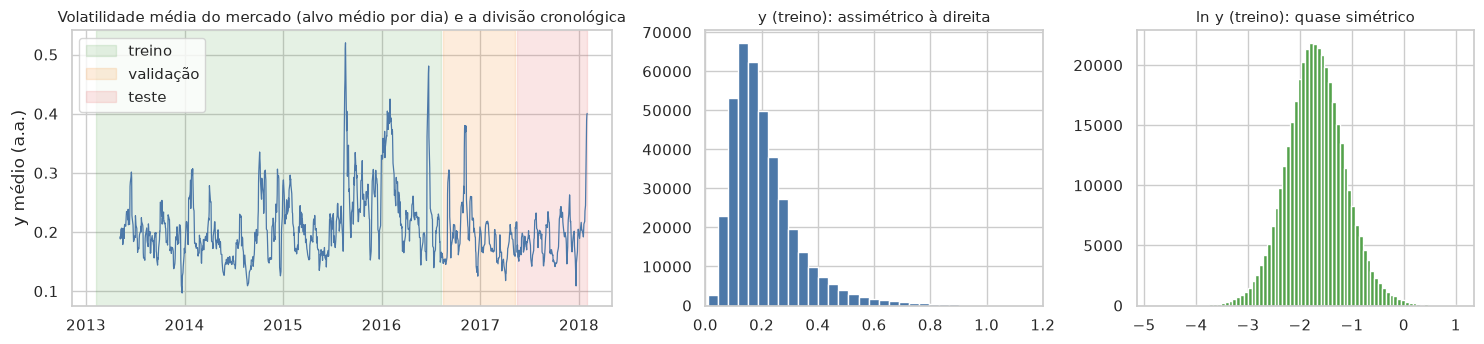

In [27]:
daily = sel.groupby("date")["y"].mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1.6, 1, 1]})
axes[0].plot(daily.index, daily.to_numpy(), lw=0.9, color="#4c78a8")
for a, b, c, lab in (("train_start", "train_end", "#54a24b", "treino"), ("val_start", "val_end", "#f58518", "validação"), ("test_start", "test_end", "#e45756", "teste")):
    axes[0].axvspan(split.bounds[a], split.bounds[b], color=c, alpha=0.15, label=lab)
axes[0].set_title("Volatilidade média do mercado (alvo médio por dia) e a divisão cronológica")
axes[0].set_ylabel("y médio (a.a.)")
axes[0].legend(loc="upper left")
axes[1].hist(parts["train"]["y"], bins=80, color="#4c78a8")
axes[1].set_title("y (treino): assimétrico à direita")
axes[1].set_xlim(0, 1.2)
axes[2].hist(np.log(parts["train"]["y"]), bins=80, color="#54a24b")
axes[2].set_title("ln y (treino): quase simétrico")
plt.show()

**Leitura.** A volatilidade vem em **ondas**: picos em ago/2015, jan–fev/2016 e jun/2016 (treino), um mercado **muito calmo** em 2017 (validação e começo do teste) e o **salto de jan–fev/2018**
no fim do teste (o alvo das últimas amostras do teste já cobre os primeiros pregões de fevereiro). Duas consequências honestas: (1) o treino é **mais agitado** do que a validação e o teste (as médias da tabela
acima mostram isso: 0,215 contra 0,193 e 0,191), então um modelo que "decora a média do treino" erra por viés de nível; (2) o salto de 2018 é um **choque** que nenhuma feature de janeiro conhece, então o erro no fim do teste
deve ser grande para **qualquer** modelo. Dois bons motivos para olhar o erro **por período**. O histograma confirma a assimetria de `y` e a quase-simetria de `ln y`.

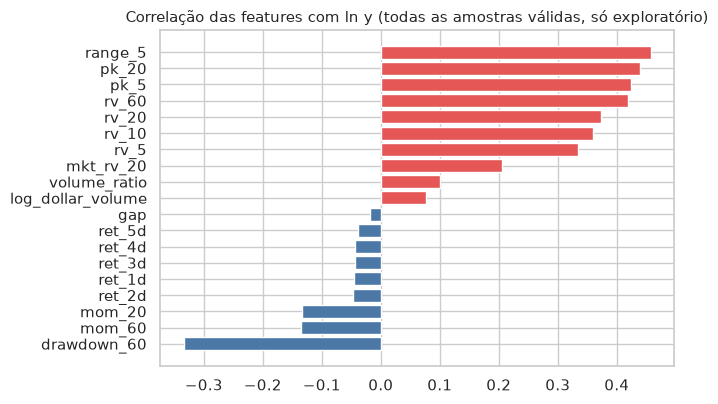

Maiores |correlação| com ln y: range_5 (+0.46), pk_20 (+0.44), pk_5 (+0.42), rv_60 (+0.42), rv_20 (+0.37), rv_10 (+0.36)


In [28]:
corr_ln = sel.assign(ln_y=np.log(sel["y"]))[[*VOL_NUMERIC, "ln_y"]].corr()["ln_y"].drop("ln_y").sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(corr_ln.index, corr_ln.to_numpy(), color=np.where(corr_ln.to_numpy() > 0, "#e45756", "#4c78a8"))
ax.set_title("Correlação das features com ln y (todas as amostras válidas, só exploratório)")
plt.show()
print("Maiores |correlação| com ln y:", ", ".join(f"{k} ({v:+.2f})" for k, v in corr_ln.reindex(corr_ln.abs().sort_values(ascending=False).index).head(6).items()))

**Leitura.** As medidas de volatilidade passada (`rv_*`, `pk_*`, `range_5`) e a do mercado (`mkt_rv_20`) dominam, como esperado do **agrupamento de volatilidade**. Um detalhe útil: as janelas **longas** (`rv_60`, `pk_20`)
e a amplitude `range_5` correlacionam **mais** que a `rv_5`, porque a vol de 5 retornos é uma estimativa barulhenta. `drawdown_60` (≈ −0,33) e `mom_*` (≈ −0,13) têm correlação **negativa**: ações em queda ficam mais voláteis
(efeito alavancagem), um sinal assimétrico que a rede pode explorar. `ret_*d` (com sinal) quase não se correlacionam linearmente com o log da volatilidade (o módulo importa mais que o sinal, e as `rv_*` já o resumem),
mas mantemos os retornos defasados para a rede usá-los de forma não linear. A correlação é só **exploratória** (calculada em todas as amostras válidas, sem papel na seleção).

## 2.3 Preparação: normalização visível das features e padronização do alvo (`ln y`)

- **Features:** `Normalization.adapt()` **só no treino**, embutida no modelo (a API recebe as features brutas). A tabela mostra média e desvio **antes e depois**.
- **Alvo:** `ln y` é padronizado com média e desvio **do treino** (`z = (ln y − μ) / σ`). A rede aprende `z`; a **inversão** (`z·σ + μ`, depois `exp`) é feita por camadas no clone de inferência,
  que então devolve a volatilidade em fração a.a.

In [29]:
v_norm = layers.Normalization(axis=-1, name="norm")
v_norm.adapt(vX_train)
v_mean, v_var = np.asarray(v_norm.mean).reshape(-1), np.asarray(v_norm.variance).reshape(-1)
vZ_train, vZ_val = v_norm(vX_train).numpy(), v_norm(vX_val).numpy()
show(
    pd.DataFrame(
        {"média (antes)": vX_train.mean(axis=0), "desvio (antes)": vX_train.std(axis=0), "máx (antes)": vX_train.max(axis=0),
         "média (depois)": vZ_train.mean(axis=0), "desvio (depois)": vZ_train.std(axis=0), "média val. (depois)": vZ_val.mean(axis=0)},
        index=VOL_FEATURES,
    )
)
ln_train = np.log(vy_train)
v_mu, v_sigma = float(ln_train.mean()), float(ln_train.std())
vz_train, vz_val = (np.log(vy_train) - v_mu) / v_sigma, (np.log(vy_val) - v_mu) / v_sigma
vz_test = (np.log(vy_test) - v_mu) / v_sigma
print(f"alvo: ln y no treino tem média μ = {v_mu:.4f} e desvio σ = {v_sigma:.4f} | z no treino: média {vz_train.mean():+.3f}, desvio {vz_train.std():.3f} | z na validação: média {vz_val.mean():+.3f}")

,média (antes),desvio (antes),máx (antes),média (depois),desvio (depois),média val. (depois)
ret_1d,0.0004,0.0162,0.3394,0.0000,1.0000,-0.0001
ret_2d,0.0004,0.0162,0.3394,0.0000,1.0000,0.0014
ret_3d,0.0004,0.0162,0.3394,0.0000,1.0000,0.0015
ret_4d,0.0004,0.0162,0.3394,0.0000,1.0000,0.0009
ret_5d,0.0004,0.0162,0.3394,0.0000,1.0000,0.0010
rv_5,0.2153,0.1414,2.8704,0.0000,1.0000,-0.1583
rv_10,0.2245,0.1261,2.3501,0.0000,1.0000,-0.1705
rv_20,0.2316,0.1130,1.8227,-0.0000,1.0000,-0.1791
rv_60,0.2380,0.0956,1.5517,0.0000,1.0000,-0.0936
pk_5,0.1987,0.1016,8.2816,0.0000,1.0000,-0.1742


alvo: ln y no treino tem média μ = -1.7000 e desvio σ = 0.5632 | z no treino: média +0.000, desvio 1.000 | z na validação: média -0.226


**Leitura.** As features viram média 0 e desvio 1 no treino. A **média da validação** (última coluna) **não é 0** em várias colunas (`rv_*`, `mkt_rv_20`): é o **deslocamento de regime** (a validação é mais calma que o treino),
exatamente o que a regra "estatística só do treino" preserva. Padronizar o alvo ajuda o otimizador (saída de ordem 1) e dá uma escala natural para a perda Huber.

## 2.4 Baselines e métricas

Um MLP só vale se vencer alternativas **simples**:
- **Média do treino:** prevê sempre a volatilidade média do treino;
- **Persistência:** prevê que a próxima semana terá a volatilidade da última (`rv_5`);
- **HAR linear** (Corsi, 2009): regressão linear de `ln y` em `ln rv_5`, `ln rv_20` e `ln rv_60` (semana, mês e trimestre); é o baseline clássico de previsão de volatilidade, difícil de bater.

**Métricas** (todas em **unidades naturais**, fração a.a., salvo a última): RMSE, MAE, **MAE / média do alvo** e **RMSE / média do alvo** (margem de erro relativa exigida), **QLIKE**
`média(y²/ŷ² − ln(y²/ŷ²) − 1)` (assimétrica: subestimar a volatilidade custa mais que superestimar, o que é desejável em risco) e **R² no log**.

In [30]:
def qlike(y, yhat) -> float:
    ratio = (np.asarray(y, dtype="float64") / np.asarray(yhat, dtype="float64")) ** 2
    return float(np.mean(ratio - np.log(ratio) - 1.0))


def vol_scores(y, yhat) -> dict[str, float]:
    y, yhat = np.asarray(y, dtype="float64"), np.asarray(yhat, dtype="float64")
    err = yhat - y
    rmse, mae = float(np.sqrt(np.mean(err**2))), float(np.mean(np.abs(err)))
    return {"RMSE": rmse, "MAE": mae, "MAE/média": mae / float(y.mean()), "RMSE/média": rmse / float(y.mean()), "QLIKE": qlike(y, yhat),
            "R² (log)": float(r2_score(np.log(y), np.log(yhat))), "viés": float(err.mean())}  # fmt: skip


def har_design(X) -> np.ndarray:
    cols = [VOL_FEATURES.index(c) for c in ("rv_5", "rv_20", "rv_60")]
    return np.column_stack([np.ones(len(X)), np.log(np.clip(X[:, cols], VOL_FLOOR, None))])


har_beta, *_ = np.linalg.lstsq(har_design(vX_train), vz_train, rcond=None)  # em unidades padronizadas de ln y


def har_predict(X) -> np.ndarray:
    return np.exp(v_mu + v_sigma * (har_design(X) @ har_beta))


def persistence_predict(X) -> np.ndarray:
    return np.clip(X[:, VOL_FEATURES.index("rv_5")], VOL_FLOOR, None)


def mean_predict(X) -> np.ndarray:
    return np.full(len(X), vy_train.mean())


baselines = {"média do treino": mean_predict, "persistência (rv_5)": persistence_predict, "HAR linear": har_predict}
val_base = pd.DataFrame({k: vol_scores(vy_val, f(vX_val)) for k, f in baselines.items()}).T
print("Baselines na VALIDAÇÃO (o teste só é usado uma vez, no fim):")
show(val_base)
print(f"HAR: coeficientes (padronizados) = {np.round(har_beta, 3)} (intercepto, ln rv_5, ln rv_20, ln rv_60)")

Baselines na VALIDAÇÃO (o teste só é usado uma vez, no fim):


,RMSE,MAE,MAE/média,RMSE/média,QLIKE,R² (log),viés
média do treino,0.1411,0.0978,0.5070,0.7315,0.8056,-0.2410,0.0221
persistência (rv_5),0.1727,0.1055,0.5468,0.8949,1.8678,-0.3627,-0.0001
HAR linear,0.1315,0.0789,0.4091,0.6814,0.8394,0.1545,-0.0123


HAR: coeficientes (padronizados) = [2.034 0.301 0.103 0.907] (intercepto, ln rv_5, ln rv_20, ln rv_60)


## 2.5 Perda Huber: `delta` calibrado em unidades de `ln y` padronizado

A perda **Huber** é quadrática para erros pequenos e **linear** para os grandes (`|e| > δ`), então **limita a influência de eventos extremos** (o erro de uma ação em dia de balanço pesa menos que o do MSE).
O `δ` precisa estar na **escala do ruído**. Calibramos assim: pegamos os **resíduos do HAR no treino** (em unidades de `z`), estimamos o desvio **robusto** `σ_res = 1,4826 · MAD` (insensível a caudas) e usamos
**`δ = 1,345 · σ_res`**, a constante clássica de Huber que mantém ≈ 95% da eficiência do MSE quando o ruído é normal e protege contra outliers.

In [31]:
_res = vz_train - har_design(vX_train) @ har_beta
sigma_res = 1.4826 * float(np.median(np.abs(_res - np.median(_res))))
HUBER_DELTA = round(1.345 * sigma_res, 3)
print(f"resíduo do HAR no treino (em z): desvio = {_res.std():.3f}, desvio robusto (MAD) = {sigma_res:.3f} | fração de resíduos com |e| > δ: {(np.abs(_res) > HUBER_DELTA).mean():.1%}")
print(f"δ de Huber = 1,345 × {sigma_res:.3f} = {HUBER_DELTA}  (em unidades de ln y padronizado; em ln y cru: {HUBER_DELTA * v_sigma:.3f}, ou seja, ~{(np.exp(HUBER_DELTA * v_sigma) - 1):.0%} de erro multiplicativo)")

resíduo do HAR no treino (em z): desvio = 0.881, desvio robusto (MAD) = 0.816 | fração de resíduos com |e| > δ: 19.2%
δ de Huber = 1,345 × 0.816 = 1.098  (em unidades de ln y padronizado; em ln y cru: 0.618, ou seja, ~86% de erro multiplicativo)


## 2.6 Ablação manual: largura × profundidade × perda (3 seeds cada)

Grade: largura da 1ª camada oculta ∈ {32, 64, 128} × profundidade ∈ {1, 2, 3} (cada camada tem a **metade** da anterior), **Huber** em todas, 3 seeds. Depois, na configuração escolhida,
**Huber × MSE** (3 seeds). Treino: Adam 1e-3 + `ReduceLROnPlateau` + `EarlyStopping` na loss de validação. A decisão usa a **validação completa**: **QLIKE** como critério principal
(padrão em previsão de volatilidade), com a regra do **1 erro-padrão** (a configuração mais simples dentro do ruído da melhor).

**Regra de amostragem (só na ablação, para caber na CPU):** cada treino da grade usa **1 a cada 3 pregões do treino** (≈ 133 mil linhas). Dias consecutivos são quase redundantes (alvos de 5 dias se sobrepõem
e as features mudam pouco de um dia para o outro), então a subamostra por **data** perde pouca informação. O **modelo final** treina com **todas** as linhas de treino.

In [32]:
def build_vol_mlp(width: int, depth: int, name: str = "volatility_mlp") -> keras.Model:
    """Camada a camada: Input -> Normalization (treino) -> [Dense(relu)] x depth -> Dense(1) (ln y padronizado, saida linear)."""
    inputs = keras.Input(shape=(N_VOL,), name="features")
    x = layers.Normalization(axis=-1, mean=v_mean, variance=v_var, name="norm")(inputs)
    for i in range(depth):
        x = layers.Dense(max(8, width // 2**i), activation="relu", name=f"dense_{i}")(x)
    outputs = layers.Dense(1, name="out")(x)
    return keras.Model(inputs, outputs, name=name)


def to_natural(z) -> np.ndarray:
    return np.exp(v_mu + v_sigma * np.asarray(z, dtype="float64").reshape(-1))


_train_day = np.searchsorted(split.days, parts["train"]["date"].to_numpy())
abl_mask = _train_day % 3 == 0  # regra de amostragem da ablação: 1 a cada 3 pregoes do treino
vX_abl, vz_abl = vX_train[abl_mask], vz_train[abl_mask]
print(f"ablação: {abl_mask.sum():,} de {len(abl_mask):,} linhas de treino ({abl_mask.mean():.0%}); validação completa ({len(vX_val):,})")


def fit_vol(width: int, depth: int, seed: int, loss: str, max_epochs: int = 30, verbose: int = 0, full: bool = False):
    set_seed(seed)
    model = build_vol_mlp(width, depth)
    loss_obj = keras.losses.Huber(delta=HUBER_DELTA) if loss == "huber" else "mse"
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss_obj, metrics=["mae"], jit_compile=False)
    callbacks = [
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ]
    x, z = (vX_train, vz_train) if full else (vX_abl, vz_abl)
    history = model.fit(x, z, validation_data=(vX_val, vz_val), epochs=max_epochs, batch_size=1024, callbacks=callbacks, verbose=verbose)
    return model, history


_rows = []
_t0 = time.time()
_runs = [(w, d, "huber") for d in (1, 2, 3) for w in (32, 64, 128)]
for width, depth, loss in _runs:
    for seed in (1, 2, 3):
        t1 = time.time()
        m, h = fit_vol(width, depth, seed, loss)
        sc = vol_scores(vy_val, to_natural(m.predict(vX_val, batch_size=8192, verbose=0)))
        _rows.append({"loss": loss, "depth": depth, "width": width, "seed": seed, "params": m.count_params(), "val_QLIKE": sc["QLIKE"], "val_RMSE": sc["RMSE"],
                      "val_MAE": sc["MAE"], "val_R2log": sc["R² (log)"], "epochs": len(h.history["loss"]), "seconds": time.time() - t1})  # fmt: skip
    print(f"  {loss} depth={depth} width={width} pronto ({time.time() - _t0:.0f}s)", flush=True)
vol_abl = pd.DataFrame(_rows)
keras.backend.clear_session()

ablação: 133,068 de 398,738 linhas de treino (33%); validação completa (91,612)


  huber depth=1 width=32 pronto (18s)


  huber depth=1 width=64 pronto (34s)


  huber depth=1 width=128 pronto (50s)


  huber depth=2 width=32 pronto (69s)


  huber depth=2 width=64 pronto (79s)


  huber depth=2 width=128 pronto (89s)


  huber depth=3 width=32 pronto (102s)


  huber depth=3 width=64 pronto (113s)


  huber depth=3 width=128 pronto (124s)


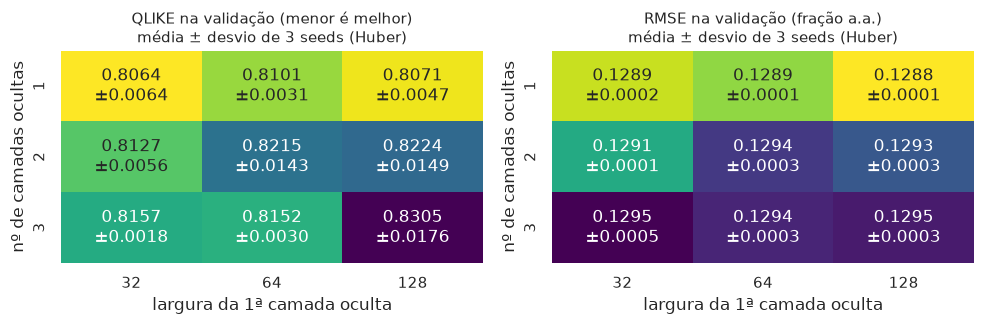

,loss,depth,width,params,qlike,qlike_std,rmse,mae,r2log,epochs,se
0,huber,1,32,865,0.8064,0.0064,0.1289,0.0770,0.1979,25.3333,0.0037
2,huber,1,128,3457,0.8071,0.0047,0.1288,0.0768,0.2018,19.0000,0.0027
1,huber,1,64,1729,0.8101,0.0031,0.1289,0.0769,0.1990,21.0000,0.0018
3,huber,2,32,1377,0.8127,0.0056,0.1291,0.0771,0.1970,24.3333,0.0032
7,huber,3,64,4289,0.8152,0.0030,0.1294,0.0771,0.1945,9.0000,0.0017
6,huber,3,32,1505,0.8157,0.0018,0.1295,0.0773,0.1926,16.0000,0.0011


melhor QLIKE: 0.8064 (largura 32, profundidade 1, EP 0.0037) -> pela regra do 1 EP: largura 32, profundidade 1 (865 parâmetros)


In [33]:
agg_v = (
    vol_abl.groupby(["loss", "depth", "width"])
    .agg(params=("params", "first"), qlike=("val_QLIKE", "mean"), qlike_std=("val_QLIKE", "std"), rmse=("val_RMSE", "mean"), mae=("val_MAE", "mean"), r2log=("val_R2log", "mean"), epochs=("epochs", "mean"))
    .reset_index()
)  # fmt: skip
agg_h = agg_v[agg_v["loss"] == "huber"].copy()
agg_h["se"] = agg_h["qlike_std"] / np.sqrt(3)
top = agg_h.loc[agg_h["qlike"].idxmin()]
near = agg_h[agg_h["qlike"] <= top["qlike"] + top["se"]]
pick = near.sort_values(["params", "qlike"]).iloc[0]
VOL_WIDTH, VOL_DEPTH = int(pick["width"]), int(pick["depth"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, col, ttl in zip(axes, ("qlike", "rmse"), ("QLIKE na validação (menor é melhor)", "RMSE na validação (fração a.a.)"), strict=True):
    mean = agg_h.pivot(index="depth", columns="width", values=col)
    std = vol_abl[vol_abl["loss"] == "huber"].groupby(["depth", "width"])["val_QLIKE" if col == "qlike" else "val_RMSE"].std().unstack()
    labels = mean.map("{:.4f}".format) + "\n±" + std.map("{:.4f}".format)
    sns.heatmap(mean, annot=labels, fmt="", cmap="viridis_r", ax=ax, cbar=False)
    ax.set_title(f"{ttl}\nmédia ± desvio de 3 seeds (Huber)")
    ax.set_xlabel("largura da 1ª camada oculta")
    ax.set_ylabel("nº de camadas ocultas")
plt.show()
show(agg_h.sort_values("qlike").head(6))
print(f"melhor QLIKE: {top['qlike']:.4f} (largura {int(top['width'])}, profundidade {int(top['depth'])}, EP {top['se']:.4f}) -> pela regra do 1 EP: largura {VOL_WIDTH}, profundidade {VOL_DEPTH} ({int(pick['params']):,} parâmetros)")

In [34]:
_rows = []
for loss in ("mse", "huber"):
    for seed in (1, 2, 3):
        m, h = fit_vol(VOL_WIDTH, VOL_DEPTH, seed, loss)
        sc = vol_scores(vy_val, to_natural(m.predict(vX_val, batch_size=8192, verbose=0)))
        _rows.append({"loss": loss, "seed": seed, "val_QLIKE": sc["QLIKE"], "val_RMSE": sc["RMSE"], "val_MAE": sc["MAE"], "val_R2log": sc["R² (log)"], "epochs": len(h.history["loss"])})
keras.backend.clear_session()
loss_cmp = pd.DataFrame(_rows)
loss_tab = loss_cmp.groupby("loss")[["val_QLIKE", "val_RMSE", "val_MAE", "val_R2log"]].agg(["mean", "std"])
show(loss_tab)
_q = loss_cmp.groupby("loss")["val_QLIKE"].agg(["mean", "std"])
VOL_LOSS = "huber" if _q.loc["huber", "mean"] <= _q.loc["mse", "mean"] + _q.loc["mse", "std"] / np.sqrt(3) else "mse"  # empate (1 EP) -> Huber, mais robusta
print(f"DECISÃO: perda = {VOL_LOSS} (QLIKE de validação: Huber {_q.loc['huber', 'mean']:.4f} × MSE {_q.loc['mse', 'mean']:.4f}) | largura {VOL_WIDTH}, profundidade {VOL_DEPTH}")

val_QLIKE        val_RMSE        val_MAE        val_R2log       
           mean    std     mean    std    mean    std      mean    std
loss                                                                  
huber    0.8064 0.0064   0.1289 0.0002  0.0770 0.0000    0.1979 0.0009
mse      0.8036 0.0043   0.1288 0.0002  0.0769 0.0000    0.1997 0.0017

DECISÃO: perda = mse (QLIKE de validação: Huber 0.8064 × MSE 0.8036) | largura 32, profundidade 1


**Leitura da ablação.** Em **RMSE** a grade inteira é praticamente idêntica (≈ 0,129 em todas as células). Em **QLIKE** as redes de **1 camada** são as melhores e mais estáveis entre seeds, e as de 2 e 3 camadas ficam um pouco
**piores** (e mais instáveis, sobretudo com 64 e 128 neurônios): mais capacidade não ajuda, e sim aumenta a variância. Isso é coerente com a literatura: a previsão de volatilidade é dominada por **poucas features
lineares em log** (as `rv_*`) e o HAR linear é um baseline notoriamente forte; além disso há pouco dado **independente** (≈ 820 pregões de treino). A regra do **1 erro-padrão** escolhe a rede mais simples dentro
do ruído da melhor, que aqui é também a de menor QLIKE. Na comparação **Huber × MSE** (3 seeds) o resultado é um **empate técnico** (QLIKE de validação diferindo na 3ª casa, RMSE e MAE iguais até a 4ª): a regra
adotada (ficar com a Huber, mais robusta, **a menos que seja pior que a MSE por mais de 1 erro-padrão**) decide pela linha `DECISÃO` impressa acima, e vale registrar que a robustez da Huber **não** se traduziu em ganho
mensurável nesta amostra (o alvo já está em log, o que por si só suaviza os extremos).

## 2.7 Modelo final, camada a camada, e justificativas

```
Input(25) → Normalization → Dense(w, relu) → … → Dense(1)        [treino: ln y padronizado]
clone de inferência: … → Normalization(invert=True) → Activation("exponential")   [saída: volatilidade, fração a.a.]
```

### Justificativa: Arquitetura (Rede 2)
- **Ativação das ocultas: ReLU.** Entrada padronizada, camadas rasas e relações aproximadamente "lineares por partes" no log (a volatilidade futura cresce com a passada, com quebras em regimes extremos):
  a ReLU aprende isso sem saturar, é barata e converge rápido. `tanh`/`sigmoid` saturariam em caudas (dias de pânico) e atrasariam o treino.
- **Profundidade × largura:** a grade (heatmaps de QLIKE e RMSE, 3 seeds) mostrou que **mais capacidade não ajuda** (as redes de 1 camada foram as melhores em QLIKE); ficamos com a **menor rede dentro do erro-padrão da melhor** (impressa acima). Poucas camadas bastam porque
  o sinal é dominado por poucas features e há pouco dado **independente** (≈ 820 pregões de treino; as linhas de ações diferentes no mesmo dia são fortemente correlacionadas pelo mercado).
- **Saída: `Dense(1)` linear** (sem ativação) em cima do **alvo padronizado em log**: é uma regressão sem limite natural. A positividade vem de `exp(·)` no clone de inferência
  (`Normalization(invert=True)` desfaz a padronização e `Activation("exponential")` devolve a volatilidade em fração a.a.). Uma ReLU ou softplus na saída "cortaria" previsões e estragaria o gradiente.

### Justificativa: Compilação (Rede 2)
- **Loss: Huber ou MSE, conforme a linha `DECISÃO` da ablação** (os dois empataram na validação), sobre `ln y` padronizado. O log torna o erro **multiplicativo**; a Huber com `δ = 1,345·σ_res` (σ_res = desvio robusto dos resíduos do HAR, ver seção 2.5) é quadrática no miolo
  (eficiente) e linear nas caudas (robusta a eventos).
- **Taxa de aprendizado: Adam 1e-3 com `ReduceLROnPlateau` (fator 0,5, paciência 2).** 1e-3 é estável para MLPs com entrada padronizada; reduzir quando a validação estagna refina o mínimo sem escolher o ponto de parada à mão;
  o `EarlyStopping` (paciência 5, `restore_best_weights`) evita *overfitting*.
- **Métricas:** **RMSE e MAE em unidades naturais** (exigidos) e suas razões com a média do alvo (margem de erro relativa); **QLIKE** (padrão da área, penaliza mais subestimar risco) e **R² no log** como complementos.
  Durante o treino monitoramos a `mae` em unidades de `z` e a loss.

In [35]:
set_seed(SEED)
vol_model = build_vol_mlp(VOL_WIDTH, VOL_DEPTH)
loss_obj = keras.losses.Huber(delta=HUBER_DELTA) if VOL_LOSS == "huber" else "mse"
vol_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss_obj, metrics=["mae"], jit_compile=False)
vol_model.summary()

Model: "volatility_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm (Normalization)            │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_0 (Dense)                 │ (None, 32)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ out (Dense)                     │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 865 (3.38 KB)

 Trainable params: 865 (3.38 KB)

 Non-trainable params: 0 (0.00 B)

21 épocas em 10s | melhor época: 15 | val_loss = 0.8719


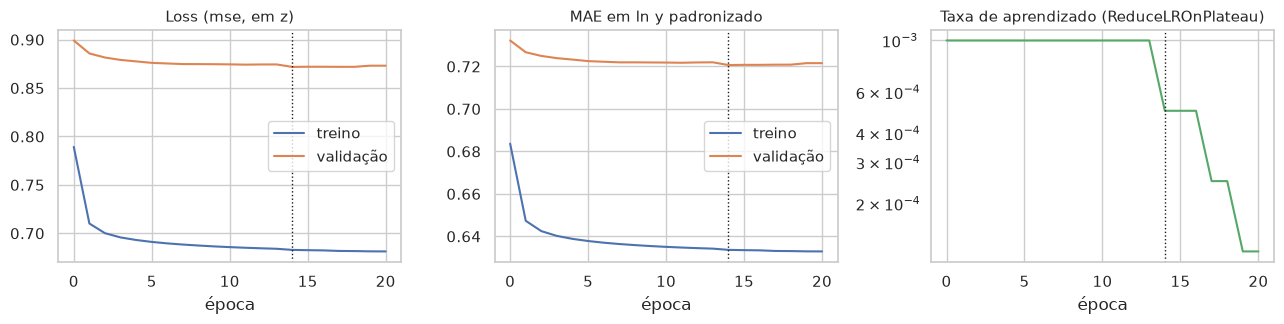

In [36]:
_t1 = time.time()
vol_hist = vol_model.fit(
    vX_train, vz_train, validation_data=(vX_val, vz_val), epochs=60, batch_size=1024,
    callbacks=[keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
               keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)],
    verbose=0,
)  # fmt: skip
vol_train_seconds = time.time() - _t1
vh = pd.DataFrame(vol_hist.history)
best_ep = int(vh["val_loss"].idxmin()) + 1
print(f"{len(vh)} épocas em {vol_train_seconds:.0f}s | melhor época: {best_ep} | val_loss = {vh['val_loss'].min():.4f}")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(vh["loss"], label="treino")
axes[0].plot(vh["val_loss"], label="validação")
axes[0].set_title(f"Loss ({VOL_LOSS}, em z)")
axes[1].plot(vh["mae"], label="treino")
axes[1].plot(vh["val_mae"], label="validação")
axes[1].set_title("MAE em ln y padronizado")
axes[2].plot(vh["learning_rate"], color="C2")
axes[2].set_yscale("log")
axes[2].set_title("Taxa de aprendizado (ReduceLROnPlateau)")
for ax in axes:
    ax.axvline(best_ep - 1, color="k", ls=":", lw=1)
    ax.set_xlabel("época")
axes[0].legend()
axes[1].legend()
plt.show()

**Leitura.** A loss de validação é **maior** que a de treino (≈ 0,87 contra ≈ 0,68, em unidades de `z`), mas **não sobe** ao longo das épocas: a distância é grande e **constante**. Isso **não** é *overfitting* clássico
(que mostraria a validação piorando enquanto o treino melhora); é o **deslocamento de regime**: a validação (2016–2017) é mais calma e tem outro nível de volatilidade que o treino (a média de `z` na validação é
negativa, seção 2.3), e a rede, de 865 parâmetros, mal tem como decorar 400 mil linhas. A curva de validação para de melhorar em poucas épocas; o `EarlyStopping` restaura os melhores pesos (linha pontilhada)
e `ReduceLROnPlateau` corta a taxa quando estagna (painel da direita).

## 2.8 Clone de inferência: de volta às unidades naturais

O clone de inferência **compartilha os pesos** do modelo treinado e acrescenta `Normalization(invert=True)` (desfaz a padronização do alvo) e `Activation("exponential")`. A saída é a **volatilidade anualizada, em fração**.
É exatamente este caminho que a API serve.

In [37]:
v_denorm = layers.Normalization(axis=-1, mean=np.array([v_mu], dtype="float32"), variance=np.array([v_sigma**2], dtype="float32"), invert=True, name="target")
vol_infer = keras.Model(vol_model.input, layers.Activation("exponential", name="exp")(v_denorm(vol_model.output)), name="volatility_inference")
_chk = vol_infer.predict(vX_val[:1000], verbose=0).reshape(-1)
assert np.allclose(_chk, to_natural(vol_model.predict(vX_val[:1000], verbose=0)), rtol=1e-4)
print("clone de inferência == exp(z·σ + μ):", "OK")

clone de inferência == exp(z·σ + μ): OK


## 2.9 Avaliação no teste (tocado uma única vez)

O modelo e os baselines são avaliados **uma vez** no teste (2017-05 → 2018-01, com o alvo das últimas amostras já olhando para o salto de fevereiro/2018). Reportamos as métricas exigidas (RMSE, MAE, MAE/média e RMSE/média,
**em unidades naturais**) e os extras (QLIKE, R² no log, viés).

In [38]:
yhat_mlp = vol_infer.predict(vX_test, batch_size=8192, verbose=0).reshape(-1).astype("float64")
yhat = {"MLP": yhat_mlp, **{k: f(vX_test) for k, f in baselines.items()}}
vol_test_table = pd.DataFrame({k: vol_scores(vy_test, v) for k, v in yhat.items()}).T.loc[["MLP", "HAR linear", "persistência (rv_5)", "média do treino"]]
show(vol_test_table)
print(f"média do alvo no teste: {vy_test.mean():.4f} | amostras: {len(vy_test):,}")
mlp = vol_test_table.loc["MLP"]
print(f"MLP: RMSE = {mlp['RMSE']:.4f} ({mlp['RMSE/média']:.1%} da média), MAE = {mlp['MAE']:.4f} ({mlp['MAE/média']:.1%} da média), QLIKE = {mlp['QLIKE']:.4f}, R² (log) = {mlp['R² (log)']:.3f}")

,RMSE,MAE,MAE/média,RMSE/média,QLIKE,R² (log),viés
MLP,0.1332,0.0741,0.3876,0.6971,0.8707,0.2331,-0.0231
HAR linear,0.1354,0.0766,0.4009,0.7088,0.8836,0.1857,-0.0201
persistência (rv_5),0.1748,0.1022,0.5347,0.9149,1.9230,-0.3420,-0.0037
média do treino,0.1459,0.0985,0.5156,0.7633,0.8378,-0.2627,0.0240


média do alvo no teste: 0.1911 | amostras: 89,792
MLP: RMSE = 0.1332 (69.7% da média), MAE = 0.0741 (38.8% da média), QLIKE = 0.8707, R² (log) = 0.233


**Leitura.** `MAE/média` e `RMSE/média` dão a **margem de erro relativa** pedida: quanto o erro típico (MAE) e o erro "quadrático" (RMSE) pesam em relação à volatilidade média do teste (o erro típico é
da ordem de **40% da média**: prever a vol de 5 pregões de **uma** ação é difícil, o alvo é barulhento). A **persistência** (`rv_5`) é a pior em RMSE/MAE/QLIKE: a vol de 5 dias é uma estimativa barulhenta. O **HAR** é o rival
sério, e o MLP o supera por **margem pequena** (da ordem de 2% no RMSE e 3% no MAE, e R² no log maior); um teste de Diebold-Mariano por pregão, mais adiante, verifica se isso é distinguível do ruído. Há uma sutileza no **QLIKE**: a **média do treino** fica com o
menor QLIKE do teste, apesar de ter R² no log **negativo** (nenhum poder de ordenação). É um artefato do deslocamento de regime: o treino foi mais agitado, então a média do treino **superestima** o teste, e o QLIKE
**perdoa superestimar e pune subestimar**, ao passo que MLP e HAR **subestimam** (viés negativo, em parte por prever a **mediana** `exp(E[ln y])`, abaixo da média por desigualdade de Jensen, e em parte por não conhecer o choque
de 2018). Portanto o QLIKE do teste favorece aqui um modelo enviesado para cima; **não** o tomamos como prova de que a média "é melhor", e por isso lemos QLIKE, RMSE, MAE e R² no log em conjunto.

,amostras,y médio,RMSE MLP,RMSE HAR linear,RMSE persistência (rv_5),RMSE média do treino,MAE MLP,viés MLP
mês,,,,,,,,
2017-05,5000,0.1638,0.0991,0.1031,0.1533,0.1223,0.0584,-0.0015
2017-06,11003,0.1852,0.0985,0.1022,0.1297,0.1188,0.0602,-0.0189
2017-07,10020,0.1863,0.1433,0.1453,0.1855,0.1550,0.0787,-0.0228
2017-08,11523,0.1805,0.1214,0.1236,0.1734,0.1370,0.0668,-0.0138
2017-09,10022,0.1858,0.1685,0.1693,0.2203,0.1789,0.0733,-0.0220
2017-10,11054,0.1858,0.1460,0.1495,0.1784,0.1585,0.0792,-0.0248
2017-11,10545,0.2044,0.1424,0.1458,0.1994,0.1548,0.0821,-0.0283
2017-12,10060,0.1741,0.0940,0.0958,0.1332,0.1166,0.0652,0.0012
2018-01,10565,0.2397,0.1504,0.1509,0.1728,0.1492,0.0953,-0.0651


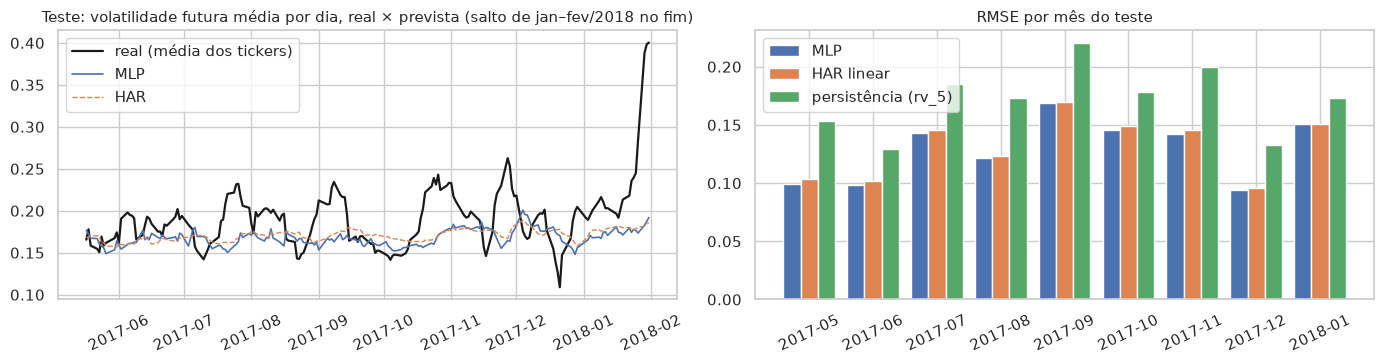

In [39]:
test_df = parts["test"][["date", "ticker", "y"]].copy()
for k, v in yhat.items():
    test_df[k] = v
test_df["mês"] = test_df["date"].dt.to_period("M").astype(str)
months = []
for mth, d in test_df.groupby("mês"):
    row = {"mês": mth, "amostras": len(d), "y médio": d["y"].mean()}
    for k in ("MLP", "HAR linear", "persistência (rv_5)", "média do treino"):
        row[f"RMSE {k}"] = float(np.sqrt(np.mean((d[k] - d["y"]) ** 2)))
    row["MAE MLP"] = float(np.mean(np.abs(d["MLP"] - d["y"])))
    row["viés MLP"] = float(np.mean(d["MLP"] - d["y"]))
    months.append(row)
by_month = pd.DataFrame(months).set_index("mês")
show(by_month)
daily_t = test_df.groupby("date")[["y", "MLP", "HAR linear", "persistência (rv_5)"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(daily_t.index, daily_t["y"], color="k", lw=1.6, label="real (média dos tickers)")
axes[0].plot(daily_t.index, daily_t["MLP"], color="C0", lw=1.2, label="MLP")
axes[0].plot(daily_t.index, daily_t["HAR linear"], color="C1", lw=1.0, ls="--", label="HAR")
axes[0].set_title("Teste: volatilidade futura média por dia, real × prevista (salto de jan–fev/2018 no fim)")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=25)
width_m = 0.27
xs = np.arange(len(by_month))
for i, (k, c) in enumerate((("MLP", "C0"), ("HAR linear", "C1"), ("persistência (rv_5)", "C2"))):
    axes[1].bar(xs + (i - 1) * width_m, by_month[f"RMSE {k}"], width_m, label=k, color=c)
axes[1].set_xticks(xs, by_month.index, rotation=25)
axes[1].set_title("RMSE por mês do teste")
axes[1].legend()
plt.show()

**Leitura.** O RMSE **não piora de forma clara** em jan/2018 (varia de ≈ 0,09 a ≈ 0,17 entre os meses, com o pior em set/2017), mas o **viés** do MLP em jan/2018 é cerca de **3 vezes maior** que nos outros meses: o alvo das últimas
amostras de janeiro já olha para os pregões do salto de fevereiro, enquanto as features ainda mostram um mercado calmo. É um limite **estrutural** de qualquer previsor baseado no passado (e justifica o aviso do plano:
período curto, um único regime e um choque no teste). A curva real × prevista mostra que **MLP e HAR ficam quase planos** (≈ 0,16–0,19): acompanham o **nível** do mercado em 2017, mas **não** as ondas de curto prazo
(as altas de jul, set e nov) e só reagem ao choque de fevereiro nos últimos dias, e muito menos que o real. A diferença entre os dois modelos é pequena em todos os meses.

In [40]:
# A vantagem do MLP sobre o HAR é distinguível do ruído? Teste de Diebold-Mariano com a perda agregada por PREGÃO (ações no mesmo dia são fortemente
# correlacionadas pelo mercado: a unidade quase independente é o dia, não a linha) e variância de longo prazo de Newey-West (defasagem 5).
from scipy.stats import norm


def diebold_mariano(df: pd.DataFrame, a: str, b: str, loss, lag: int = 5) -> tuple[float, float, float]:
    """Média de loss(b) - loss(a) por dia (> 0: `a` é melhor), estatística t e p-valor bilateral (normal)."""
    d = (loss(df[b] - df["y"]) - loss(df[a] - df["y"])).groupby(df["date"]).mean().to_numpy()
    n = len(d)
    c = d - d.mean()
    lrv = c @ c / n + 2 * sum((1 - k / (lag + 1)) * (c[k:] @ c[:-k]) / n for k in range(1, lag + 1))
    t = d.mean() / np.sqrt(lrv / n)
    return float(d.mean()), float(t), float(2 * (1 - norm.cdf(abs(t))))


vol_dm = {}
for _name, _loss in (("erro quadrático", np.square), ("erro absoluto", np.abs)):
    for _rival in ("HAR linear", "persistência (rv_5)", "média do treino"):
        vol_dm[(_name, _rival)] = diebold_mariano(test_df, "MLP", _rival, _loss)
vol_dm_table = pd.DataFrame(vol_dm, index=["ganho médio do MLP por dia", "t (Newey-West)", "p-valor"]).T
vol_dm_table.index.names = ["perda", "rival"]
show(vol_dm_table)
_har_sq, _har_abs = vol_dm[("erro quadrático", "HAR linear")], vol_dm[("erro absoluto", "HAR linear")]
print(f"MLP × HAR: erro quadrático p = {_har_sq[2]:.3g} | erro absoluto p = {_har_abs[2]:.3g} ({len(test_df['date'].unique())} pregões de teste)")
print("Leitura: " + ("a vantagem do MLP sobre o HAR é estatisticamente distinguível do ruído (p < 0,05) em ambas as perdas, embora pequena em tamanho." if max(_har_sq[2], _har_abs[2]) < 0.05
      else "a vantagem do MLP sobre o HAR é pequena e NÃO é distinguível do ruído em pelo menos uma das perdas: tratamos os dois como equivalentes em poder preditivo."))

ganho médio do MLP por dia  t (Newey-West)  p-valor
perda           rival                                                                   
erro quadrático HAR linear                               0.0006          4.9490   0.0000
                persistência (rv_5)                      0.0128          7.3476   0.0000
                média do treino                          0.0035          7.8459   0.0000
erro absoluto   HAR linear                               0.0025          6.0878   0.0000
                persistência (rv_5)                      0.0281         15.3491   0.0000
                média do treino                          0.0245         11.7301   0.0000

MLP × HAR: erro quadrático p = 7.46e-07 | erro absoluto p = 1.14e-09 (179 pregões de teste)
Leitura: a vantagem do MLP sobre o HAR é estatisticamente distinguível do ruído (p < 0,05) em ambas as perdas, embora pequena em tamanho.


In [41]:
edges = regime_edges(vy_train)  # tercis do alvo calculados SO no treino (V3.8)
vol_tercile_edges = edges
true_cls = regime_labels(vy_test, edges)
reg_rows = []
for cls, name in enumerate(REGIME_NAMES):
    m = true_cls == cls
    row = {"regime real": name, "amostras": int(m.sum()), "y médio": vy_test[m].mean()}
    for k in ("MLP", "HAR linear"):
        row[f"RMSE {k}"] = float(np.sqrt(np.mean((yhat[k][m] - vy_test[m]) ** 2)))
        row[f"MAE {k}"] = float(np.mean(np.abs(yhat[k][m] - vy_test[m])))
        row[f"viés {k}"] = float(np.mean(yhat[k][m] - vy_test[m]))
    reg_rows.append(row)
by_regime = pd.DataFrame(reg_rows).set_index("regime real")
print(f"cortes dos tercis (treino): baixa < {edges[0]:.4f} <= média < {edges[1]:.4f} <= alta")
show(by_regime)
print("(Nota: agrupar pelo regime REAL mistura um efeito de regressão à média: nos regimes extremos o erro é assimétrico mesmo para um modelo sem viés condicional.)")

vol_baseline_acc_mlp = float((regime_labels(yhat["MLP"], edges) == true_cls).mean())
vol_baseline_acc_har = float((regime_labels(yhat["HAR linear"], edges) == true_cls).mean())
vol_baseline_acc_persist = float((regime_labels(yhat["persistência (rv_5)"], edges) == true_cls).mean())
vol_majority_acc = float(np.bincount(true_cls, minlength=3).max() / len(true_cls))
print(f"Acurácia em 3 classes de regime (tercis do treino), teste: MLP = {vol_baseline_acc_mlp:.3%} | HAR = {vol_baseline_acc_har:.3%} | persistência = {vol_baseline_acc_persist:.3%} | classe majoritária = {vol_majority_acc:.3%} | acaso = 33,3%")

cortes dos tercis (treino): baixa < 0.1441 <= média < 0.2288 <= alta


,amostras,y médio,RMSE MLP,MAE MLP,viés MLP,RMSE HAR linear,MAE HAR linear,viés HAR linear
regime real,,,,,,,,
baixa,39456,0.1002,0.0605,0.0480,0.0444,0.0671,0.0529,0.0500
media,27802,0.1810,0.0504,0.0398,-0.0117,0.0512,0.0392,-0.0084
alta,22534,0.3627,0.2473,0.1621,-0.1552,0.2490,0.1643,-0.1571


(Nota: agrupar pelo regime REAL mistura um efeito de regressão à média: nos regimes extremos o erro é assimétrico mesmo para um modelo sem viés condicional.)
Acurácia em 3 classes de regime (tercis do treino), teste: MLP = 50.527% | HAR = 48.040% | persistência = 46.020% | classe majoritária = 43.942% | acaso = 33,3%


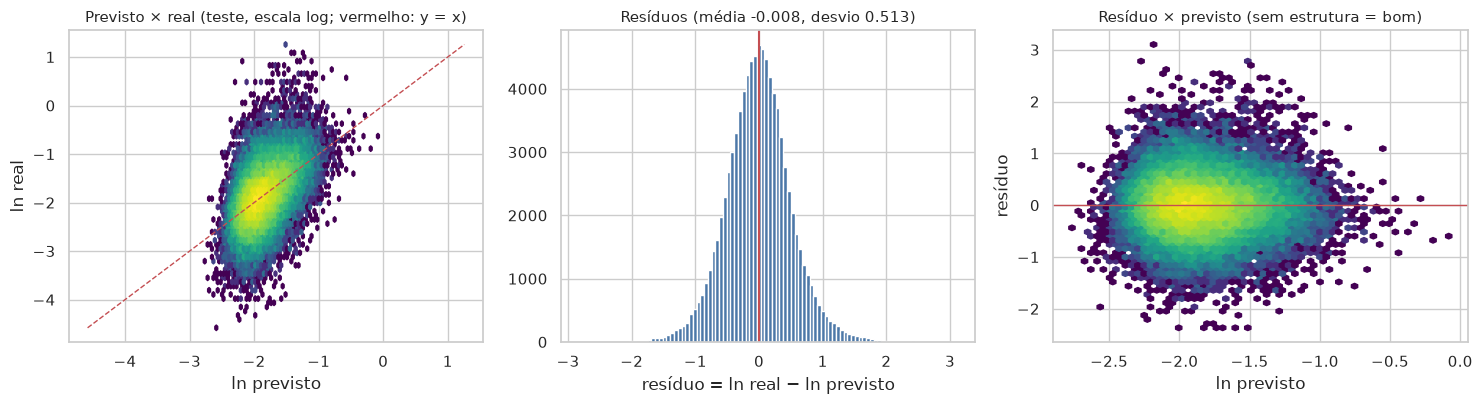

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sub = np.random.default_rng(SEED).choice(len(vy_test), size=min(40000, len(vy_test)), replace=False)
hb = axes[0].hexbin(np.log(yhat_mlp[sub]), np.log(vy_test[sub]), gridsize=60, bins="log", cmap="viridis", mincnt=1)
lims = [min(np.log(yhat_mlp[sub]).min(), np.log(vy_test[sub]).min()), max(np.log(yhat_mlp[sub]).max(), np.log(vy_test[sub]).max())]
axes[0].plot(lims, lims, "r--", lw=1)
axes[0].set(xlabel="ln previsto", ylabel="ln real", title="Previsto × real (teste, escala log; vermelho: y = x)")
resid = np.log(vy_test) - np.log(yhat_mlp)
axes[1].hist(resid, bins=100, color="#4c78a8")
axes[1].axvline(0, color="r")
axes[1].set(xlabel="resíduo = ln real − ln previsto", title=f"Resíduos (média {resid.mean():+.3f}, desvio {resid.std():.3f})")
axes[2].hexbin(np.log(yhat_mlp[sub]), resid[sub], gridsize=60, bins="log", cmap="viridis", mincnt=1)
axes[2].axhline(0, color="r", lw=1)
axes[2].set(xlabel="ln previsto", ylabel="resíduo", title="Resíduo × previsto (sem estrutura = bom)")
plt.show()

**Leitura.** A nuvem previsto × real em log tem inclinação **menor** que a diagonal: as previsões ficam concentradas num intervalo estreito (ln previsto entre ≈ −2,6 e −1) enquanto o real vai de ≈ −4 a 1. É a assinatura de
um R² baixo (≈ 0,23): o modelo acerta o **nível esperado**, não os extremos, e por isso a dispersão vertical (o **ruído irredutível**: o alvo é a vol *realizada* de só 5 retornos, uma medida barulhenta da vol "verdadeira") domina.
Os resíduos em log são centrados perto de zero, com leve **cauda direita** (dias em que a volatilidade real foi muito maior que a prevista: eventos). O gráfico resíduo × previsto não mostra estrutura forte, então o modelo não está
sistematicamente errado em algum nível de volatilidade. O viés **negativo** em unidades naturais (≈ −0,02) vem da cauda direita, de prever a mediana e do choque de 2018.

## 2.10 Sanidade: e a **direção** (sobe/desce)? Quase aleatória

Para justificar o alvo, uma checagem curta: com as **mesmas 25 features**, uma regressão logística tenta prever se o retorno dos próximos 5 pregões é positivo.

In [43]:
_fwd = np.log(sp["close"]).groupby(sp["ticker"], sort=False).shift(-HORIZON) - np.log(sp["close"])
dir_df = pd.DataFrame({"up": (_fwd > 0).astype(int)}, index=sp.index).loc[sel.index]
d_tr, d_te = dir_df.loc[parts["train"].index, "up"].to_numpy(), dir_df.loc[parts["test"].index, "up"].to_numpy()
lr_dir = LogisticRegression(max_iter=300).fit(vZ_train, d_tr)
acc_dir = float((lr_dir.predict(v_norm(vX_test).numpy()) == d_te).mean())
print(f"direção em 5 pregões, teste: regressão logística = {acc_dir:.3%} | sempre 'sobe' = {d_te.mean():.3%} | acaso = 50%")
print("-> a direção não é prevista de forma útil com essas features (o ganho é nulo ou ínfimo); a volatilidade, sim, é previsível.")

direção em 5 pregões, teste: regressão logística = 52.908% | sempre 'sobe' = 57.308% | acaso = 50%
-> a direção não é prevista de forma útil com essas features (o ganho é nulo ou ínfimo); a volatilidade, sim, é previsível.


## 2.11 Previsões em novas instâncias: os 5 últimos pregões (sem alvo ainda)

Os **5 últimos pregões** do dataset (2018-02-01 a 2018-02-07) **ainda não têm alvo** (faltam os 5 dias futuros), então não pertencem ao teste (que termina em T−5): são previsões de verdade "fora da amostra".
Sorteamos **12 tickers** com seed fixa entre os que têm janela válida nos 5 dias.

In [44]:
new_dates = new_instance_dates(sp["date"])
new_rows = vol_df[vol_df["date"].isin(new_dates) & vol_df["valid_feat"]]
_complete = new_rows.groupby("ticker").size()
candidates = _complete[_complete == len(new_dates)].index
vol_new_tickers = pick_new_tickers(candidates, k=12, seed=7)
vol_new = new_rows[new_rows["ticker"].isin(vol_new_tickers)].sort_values(["ticker", "date"]).copy()
vX_new = vol_feature_matrix(vol_new)
vol_new["previsão (vol a.a.)"] = vol_infer.predict(vX_new, verbose=0).reshape(-1)
vol_new["rv_5 (últimos 5 dias)"] = vol_new["rv_5"]
print(f"{len(candidates)} tickers com janela válida nos 5 últimos pregões | sorteados (seed 7): {vol_new_tickers}")
vol_new["dia"] = vol_new["date"].dt.strftime("%m-%d")
pivot = vol_new.pivot(index="ticker", columns="dia", values="previsão (vol a.a.)")
pivot["rv_5 em 02-07"] = vol_new[vol_new["date"] == new_dates[-1]].set_index("ticker")["rv_5"]
show(pivot)
print("Previsão = volatilidade anualizada esperada para os 5 pregões SEGUINTES a cada data (ex.: 0,25 = 25% a.a.). Sem rótulo: o futuro ainda não aconteceu.")

504 tickers com janela válida nos 5 últimos pregões | sorteados (seed 7): ['ALK', 'COO', 'DPS', 'DWDP', 'LNT', 'MHK', 'NOC', 'PYPL', 'SNA', 'TMK', 'TRV', 'V']


dia,02-01,02-02,02-05,02-06,02-07,rv_5 em 02-07
ticker,,,,,,
ALK,0.2879,0.2966,0.3374,0.3063,0.2465,0.3043
COO,0.1743,0.1891,0.2312,0.2309,0.2216,0.3256
DPS,0.1472,0.1249,0.1251,0.1178,0.1165,0.0988
DWDP,0.1954,0.2359,0.2672,0.2921,0.2974,0.6234
LNT,0.1833,0.1728,0.2169,0.2448,0.2308,0.2222
MHK,0.1568,0.1788,0.2185,0.2315,0.2301,0.2989
NOC,0.1537,0.1759,0.2266,0.2346,0.2509,0.4178
PYPL,0.2596,0.2783,0.2803,0.2884,0.2630,0.6541
SNA,0.1865,0.2026,0.2410,0.2709,0.2612,0.2208


Previsão = volatilidade anualizada esperada para os 5 pregões SEGUINTES a cada data (ex.: 0,25 = 25% a.a.). Sem rótulo: o futuro ainda não aconteceu.


In [45]:
vol_results = {
    "width": VOL_WIDTH, "depth": VOL_DEPTH, "loss": VOL_LOSS, "huber_delta": HUBER_DELTA, "mu": v_mu, "sigma": v_sigma,
    "val_baselines": val_base.to_dict(orient="index"),
    "test": vol_test_table.to_dict(orient="index"),
    "by_month": by_month.to_dict(orient="index"),
    "by_regime": by_regime.to_dict(orient="index"),
    "tercile_edges": [float(e) for e in vol_tercile_edges],
    "tercile_acc": {"mlp": vol_baseline_acc_mlp, "har": vol_baseline_acc_har, "persistence": vol_baseline_acc_persist, "majority": vol_majority_acc},
    "epochs": len(vh), "train_seconds": vol_train_seconds, "direction_acc": acc_dir,
    "split": {k: str(v.date()) for k, v in split.bounds.items()},
    "sizes": {p: len(d) for p, d in parts.items()},
}
vol_val_scores = vol_scores(vy_val, vol_infer.predict(vX_val, batch_size=8192, verbose=0).reshape(-1))
vol_results["val"] = vol_val_scores
part_times["20_volatility"] = time.time() - _t_part
print(f"Parte 2 concluída em {part_times['20_volatility'] / 60:.1f} min.")

Parte 2 concluída em 3.0 min.


# Parte 3 · Rede 3: CNN em gráficos de preço (regime de volatilidade)

> **Aviso:** conteúdo educacional (trabalho de curso). Nada aqui é recomendação de investimento.

## Motivação

Jiang, Kelly e Xiu (*(Re-)Imag(in)ing Price Trends*, **Journal of Finance**, 2023) mostram que uma rede convolucional
consegue extrair padrões de **imagens de preço**: barras OHLC, média móvel e volume desenhados como pixels, sem nenhuma
feature calculada à mão. Aqui seguimos a ideia, com uma diferença importante de **alvo**.

- **Direção (sobe/desce) é quase imprevisível** em horizonte curto: o ganho reportado no artigo aparece em carteiras
  (muitas ações, custos, rebalanceamento), e réplicas menores concluem que a CNN não passa de "chute" em acerto direcional.
  Mostramos isso numa célula de sanidade ao final da seção.
- **Volatilidade é persistente** (agrupamentos de volatilidade: dias agitados seguem dias agitados) e, por isso, **previsível**.
  O alvo é o **regime de volatilidade dos próximos 5 pregões**: `baixa`, `media` ou `alta`, definidos pelos **tercis** de
  `y = sqrt(252 · média(r²_{t+1..t+5}))` calculados **só no treino**.

Esta é a **mesma grandeza** da Rede 2 (volatilidade, regressão), agora lida **a partir da imagem**. A pergunta da conclusão é:
*o gráfico acrescenta algo além das features numéricas?*

**Tarefa:** imagem 64×64×3 (20 pregões) → 3 classes. **Métrica exigida:** acurácia (acaso = 1/3 ≈ 33,3%).
**Restrições do enunciado:** a rede é montada **do zero**, camada a camada, com `tf.keras.layers` (nada de `keras.applications`
nem transfer learning).

In [46]:
import gc
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

keras = tf.keras
layers = tf.keras.layers

_t_part = time.time()
# TRINET_TF_THREADS limita as threads do TensorFlow (a parte 0 ja faz isso; aqui so vale na execucao isolada desta parte).
_threads = 0 if "THREADS" in globals() else int(os.environ.get("TRINET_TF_THREADS", "0"))
if _threads:
    try:
        tf.config.threading.set_intra_op_parallelism_threads(_threads)
        tf.config.threading.set_inter_op_parallelism_threads(2)
    except RuntimeError:
        print("TensorFlow ja inicializado: TRINET_TF_THREADS ignorado.")

CNN_SEED = 42
keras.utils.set_random_seed(CNN_SEED)
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | threads intra-op: {tf.config.threading.get_intra_op_parallelism_threads() or 'auto'}")

TensorFlow 2.21.0 | Keras 3.15.1 | threads intra-op: auto


## 3.1 Do preço à imagem: rasterização determinística em NumPy

Cada amostra é uma **janela de 20 pregões** desenhada em **64×64×3 pixels** (`uint8`, valores 0 ou 255, **sem antialiasing**
e sem matplotlib, para que o mesmo gráfico dê exatamente os mesmos pixels no treino e na API):

| canal | conteúdo | desenho |
|---|---|---|
| 0 (R) | **barras OHLC** | traço vertical *high-low* no pixel central do dia; *tick* de abertura à esquerda, de fechamento à direita; 3 px por dia |
| 1 (G) | **média móvel** de 20 pregões do fechamento | linha contínua (as 19 linhas anteriores à janela só "aquecem" a média) |
| 2 (B) | **volume** | barras de 1 px nas 16 linhas de baixo, normalizadas pelo maior volume da janela |

Os três canais são independentes (R, G e B de uma imagem PNG); assim o preço usa a altura toda e o volume não "cobre" as
barras. Os preços entram em **log-preço** (retornos iguais viram deslocamentos iguais). O que resta decidir é a **escala
vertical**: (a) **por janela**, mínimo e máximo de cada janela viram o topo e a base (como em Jiang-Kelly-Xiu), ou (b) **fixa**,
com um intervalo constante de log-preço para as 64 linhas, centrado no ponto médio da janela. A escolha afeta justamente o
que a rede consegue ver da **volatilidade**, então ela sai de um **piloto curto** (mais abaixo), não de opinião.

O código abaixo é a cópia inline de `tools/render_chart.py` (o apêndice do notebook testa que as duas cópias dão arrays idênticos).

In [47]:
import struct
import zlib
from collections.abc import Sequence
from typing import Literal

from numpy.typing import NDArray

CHART_WINDOW = 20  # pregoes desenhados
# linhas usadas no maximo (as 19 anteriores aquecem a media movel)
CHART_CONTEXT = 2 * CHART_WINDOW - 1
CHART_SIZE = 64  # altura = largura em pixels
CHART_DAY_PX = 3  # pixels por pregao (tick de abertura, traco central, tick de fechamento)
CHART_LEFT = 2  # margem esquerda em pixels (60 px de dados + 2 + 2 = 64)
CHART_VOL_ROWS = 16  # altura maxima das barras de volume
CHART_SPAN = 0.30  # log-preco que cabe nas 64 linhas quando scale="fixed"
CHART_SCALE: Literal["fixed", "window"] = "fixed"
_EPS_SPAN = 1e-9

_F64 = NDArray[np.float64]
_U8 = NDArray[np.uint8]
_I64 = NDArray[np.int64]

_X_OPEN: _I64 = CHART_LEFT + CHART_DAY_PX * np.arange(CHART_WINDOW, dtype=np.int64)
_X_MID: _I64 = _X_OPEN + 1
_X_CLOSE: _I64 = _X_OPEN + 2
_ROWS: _I64 = np.arange(CHART_SIZE, dtype=np.int64)
# colunas da media movel: de x_mid[0] ate x_mid[-1], com interpolacao linear entre pregoes
_MA_COLS: _I64 = np.arange(_X_MID[0], _X_MID[-1] + 1, dtype=np.int64)
_MA_DAY: _I64 = (_MA_COLS - _X_MID[0]) // CHART_DAY_PX
_MA_NEXT: _I64 = np.minimum(_MA_DAY + 1, CHART_WINDOW - 1)
_MA_FRAC: _F64 = ((_MA_COLS - _X_MID[0]) % CHART_DAY_PX) / CHART_DAY_PX


def _validate(arr: _F64) -> None:
    if arr.ndim != 3 or arr.shape[2] != 5 or arr.shape[1] < CHART_WINDOW:
        raise ValueError(
            f"esperava (N, T>={CHART_WINDOW}, 5) = open, high, low, close, volume; "
            f"obtive {arr.shape}"
        )
    if not np.isfinite(arr).all():
        raise ValueError("a janela tem valores NaN ou infinitos")
    if (arr[:, :, :4] <= 0).any():
        raise ValueError("precos precisam ser positivos")
    if (arr[:, :, 4] < 0).any():
        raise ValueError("volume nao pode ser negativo")


def _moving_average(close: _F64) -> _F64:
    """Media movel de 20 pregoes do fechamento nos ultimos 20 dias (expansiva sem contexto)."""
    n, t = close.shape
    csum = np.concatenate([np.zeros((n, 1)), np.cumsum(close, axis=1)], axis=1)
    idx = np.arange(t - CHART_WINDOW, t)
    start = np.maximum(idx - (CHART_WINDOW - 1), 0)
    return np.asarray((csum[:, idx + 1] - csum[:, start]) / (idx + 1 - start), dtype=np.float64)


def _frame(lo: _F64, hi: _F64, scale: Literal["fixed", "window"], span: float) -> tuple[_F64, _F64]:
    """Topo do eixo vertical e extensao (em log-preco) para cada janela, shape (N,)."""
    if scale == "window":
        return hi, np.maximum(hi - lo, _EPS_SPAN)
    return (lo + hi) / 2 + span / 2, np.full_like(lo, span)


def _or_columns(channel: _U8, columns: _I64, mask: NDArray[np.bool_]) -> None:
    """``channel[:, :, columns] |= 255`` onde ``mask`` (N, len(columns), altura) e verdadeiro."""
    channel[:, :, columns] |= np.where(mask.transpose(0, 2, 1), np.uint8(255), np.uint8(0))


def _draw_ohlc(channel: _U8, rows_o: _I64, rows_h: _I64, rows_l: _I64, rows_c: _I64) -> None:
    grid = _ROWS[None, None, :]
    stem = (grid >= rows_h[:, :, None]) & (grid <= rows_l[:, :, None])  # high-low (linha 0 = topo)
    _or_columns(channel, _X_MID, stem)
    n_idx = np.arange(channel.shape[0])[:, None]
    channel[n_idx, rows_o, _X_OPEN[None, :]] = 255
    channel[n_idx, rows_c, _X_CLOSE[None, :]] = 255


def _draw_ma(channel: _U8, rowf_ma: _F64) -> None:
    per_col = rowf_ma[:, _MA_DAY] * (1 - _MA_FRAC) + rowf_ma[:, _MA_NEXT] * _MA_FRAC
    rows = np.rint(per_col).astype(np.int64)
    prev = np.concatenate([rows[:, :1], rows[:, :-1]], axis=1)
    grid = _ROWS[None, None, :]
    line = (grid >= np.minimum(prev, rows)[:, :, None]) & (
        grid <= np.maximum(prev, rows)[:, :, None]
    )
    _or_columns(channel, _MA_COLS, line)


def _draw_volume(channel: _U8, volume: _F64) -> None:
    vmax = volume.max(axis=1, keepdims=True)
    ratio = np.divide(volume, vmax, out=np.zeros_like(volume), where=vmax > 0)
    heights = np.maximum(np.rint(ratio * CHART_VOL_ROWS), (volume > 0)).astype(np.int64)
    bars = _ROWS[None, None, :] >= (CHART_SIZE - heights)[:, :, None]
    _or_columns(channel, _X_MID, bars)


def render_windows(
    ohlcv: _F64 | Sequence[Sequence[Sequence[float]]],
    *,
    scale: Literal["fixed", "window"] = CHART_SCALE,
    span: float = CHART_SPAN,
) -> _U8:
    """Rasteriza janelas OHLCV em lote: ``(N, T, 5)`` -> ``(N, 64, 64, 3)`` uint8.

    Colunas: open, high, low, close, volume. Desenha os ultimos ``CHART_WINDOW`` (20) pregoes; as
    linhas anteriores (ate 19) so aquecem a media movel. Aceita tambem uma janela ``(T, 5)``.
    """
    arr = np.asarray(ohlcv, dtype=np.float64)
    if arr.ndim == 2:
        arr = arr[None]
    _validate(arr)
    n, t, _ = arr.shape
    shown = arr[:, t - CHART_WINDOW :, :]
    ma = _moving_average(arr[:, :, 3])
    log_ohlc = np.log(shown[:, :, :4])
    log_ma = np.log(ma)
    lows = np.minimum(log_ohlc[:, :, 2].min(axis=1), log_ma.min(axis=1))
    highs = np.maximum(log_ohlc[:, :, 1].max(axis=1), log_ma.max(axis=1))
    top, extent = _frame(lows, highs, scale, span)
    factor = ((CHART_SIZE - 1) / extent)[:, None]

    def to_rows(log_price: _F64) -> _F64:
        return np.clip((top[:, None] - log_price) * factor, 0, CHART_SIZE - 1)

    rows = [np.rint(to_rows(log_ohlc[:, :, k])).astype(np.int64) for k in range(4)]
    img = np.zeros((n, CHART_SIZE, CHART_SIZE, 3), dtype=np.uint8)
    _draw_ohlc(img[..., 0], *rows)
    _draw_ma(img[..., 1], to_rows(log_ma))
    _draw_volume(img[..., 2], shown[:, :, 4])
    return img


def render_chart(
    window: _F64 | Sequence[Sequence[float]],
    *,
    scale: Literal["fixed", "window"] = CHART_SCALE,
    span: float = CHART_SPAN,
) -> _U8:
    """Uma janela ``(T, 5)`` -> imagem ``(64, 64, 3)``; mesmo codigo do lote."""
    batch = render_windows(np.asarray(window, dtype=np.float64)[None], scale=scale, span=span)
    image: _U8 = batch[0]
    return image


# --------------------------------------------------------------------------- PNG (sem Pillow)


def _chunk(tag: bytes, payload: bytes) -> bytes:
    body = tag + payload
    return struct.pack(">I", len(payload)) + body + struct.pack(">I", zlib.crc32(body) & 0xFFFFFFFF)


def png_bytes(image: _U8) -> bytes:
    """Codifica ``(H, W, 3)`` uint8 em PNG RGB de 8 bits, sem filtro (bytes deterministicos)."""
    if image.ndim != 3 or image.shape[2] != 3 or image.dtype != np.uint8:
        raise ValueError("esperava um array uint8 (H, W, 3)")
    height, width, _ = image.shape
    raw = b"".join(b"\x00" + image[row].tobytes() for row in range(height))
    header = struct.pack(">IIBBBBB", width, height, 8, 2, 0, 0, 0)
    return (
        b"\x89PNG\r\n\x1a\n"
        + _chunk(b"IHDR", header)
        + _chunk(b"IDAT", zlib.compress(raw, 9))
        + _chunk(b"IEND", b"")
    )

### Como é uma janela

Um exemplo real (ação do treino) decomposto nos três canais, e o composto RGB que a rede recebe.

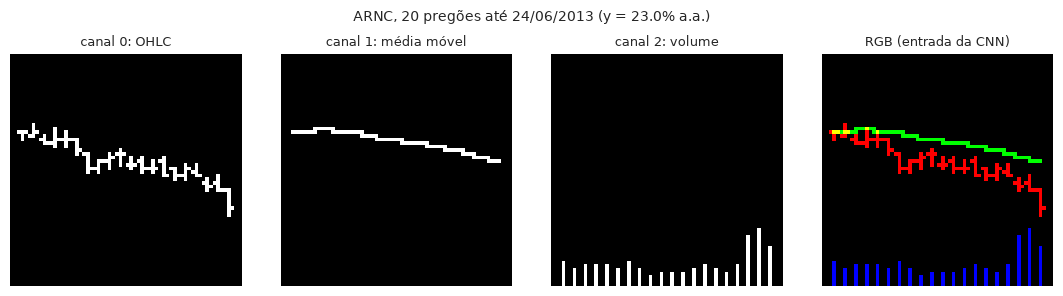

In [48]:
CNN_OHLCV_COLS = ["open", "high", "low", "close", "volume"]
cnn_ohlcv = sp[CNN_OHLCV_COLS].to_numpy(dtype=np.float64)  # (linhas, 5), na ordem de ``sp`` (ticker, data)


def cnn_gather_windows(rows: np.ndarray) -> np.ndarray:
    """Janelas (N, 39, 5) terminando nas linhas ``rows`` de ``sp`` (a regra V3 garante >= 60 linhas antes)."""
    rows = np.asarray(rows, dtype=np.int64)
    return cnn_ohlcv[rows[:, None] + np.arange(-(CHART_CONTEXT - 1), 1)[None, :]]


_valid = sp["valid"].to_numpy()
_part = sp["part"].to_numpy()
_demo_row = int(np.flatnonzero(_valid & (_part == "train"))[40_000])
_demo = render_windows(cnn_gather_windows(np.array([_demo_row])))[0]
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, (title, img) in zip(
    axes,
    [("canal 0: OHLC", _demo[..., [0, 0, 0]]), ("canal 1: média móvel", _demo[..., [1, 1, 1]]), ("canal 2: volume", _demo[..., [2, 2, 2]]), ("RGB (entrada da CNN)", _demo)],
    strict=True,
):
    ax.imshow(img, interpolation="nearest")
    ax.set_title(title, fontsize=9)
    ax.axis("off")
fig.suptitle(f"{sp.at[_demo_row, 'ticker']}, 20 pregões até {sp.at[_demo_row, 'date']:%d/%m/%Y} (y = {sp.at[_demo_row, 'y']:.1%} a.a.)", fontsize=10)
plt.tight_layout()
plt.show()

## 3.2 Piloto: qual escala vertical preserva a informação de volatilidade?

Com a escala **por janela**, uma janela calma e uma agitada com a mesma forma viram a mesma imagem (o zoom é automático) e a
amplitude absoluta, que é justamente a volatilidade, se perde. Com a escala **fixa**, barras longas = ação agitada, mas
uma janela muito calma ocupa poucas linhas (resolução) e uma muito agitada pode sair da tela (recorte). O intervalo fixo
também precisa ser escolhido. O piloto abaixo treina uma CNN **pequena** (8/16/32 filtros) por poucas épocas em
**6 mil imagens de treino** e mede a acurácia em **3 mil imagens de validação** (o teste não é tocado), para
`scale="window"` e quatro intervalos fixos. Roda em poucos minutos; `CNN_RUN_PILOT = False` pula a execução.

In [49]:
CNN_RUN_PILOT = True
CNN_PILOT_TRAIN, CNN_PILOT_VAL, CNN_PILOT_EPOCHS, CNN_PILOT_SEEDS = 6_000, 3_000, 8, (0, 1)


def cnn_pilot_model() -> keras.Model:
    """CNN do piloto: mesma família da rede final (3 blocos conv-pool com 8/16/32 filtros)."""
    return keras.Sequential(
        [
            layers.Input((CHART_SIZE, CHART_SIZE, 3)),
            layers.Rescaling(1 / 255),
            layers.Conv2D(8, 3, padding="same"),
            layers.BatchNormalization(),
            layers.ReLU(),
            layers.MaxPooling2D(),
            layers.Conv2D(16, 3, padding="same"),
            layers.BatchNormalization(),
            layers.ReLU(),
            layers.MaxPooling2D(),
            layers.Conv2D(32, 3, padding="same"),
            layers.BatchNormalization(),
            layers.ReLU(),
            layers.MaxPooling2D(),
            layers.Flatten(),
            layers.Dense(64, activation="relu"),
            layers.Dropout(0.5),
            layers.Dense(3, activation="softmax"),
        ]
    )


_y_all = sp["y"].to_numpy()
cnn_edges = regime_edges(_y_all[_valid & (_part == "train")])  # tercis de y calculados SO no treino (todas as amostras validas)
_labels_all = regime_labels(np.nan_to_num(_y_all), cnn_edges)

cnn_pilot_table = pd.DataFrame()
if CNN_RUN_PILOT:
    _rng = np.random.default_rng(0)
    _tr = _rng.choice(np.flatnonzero(_valid & (_part == "train")), CNN_PILOT_TRAIN, replace=False)
    _va = _rng.choice(np.flatnonzero(_valid & (_part == "val")), CNN_PILOT_VAL, replace=False)
    _w_tr, _w_va = cnn_gather_windows(_tr), cnn_gather_windows(_va)
    _log_range = np.log(_w_tr[:, -CHART_WINDOW:, 1].max(axis=1)) - np.log(_w_tr[:, -CHART_WINDOW:, 2].min(axis=1))  # amplitude (log) de cada janela
    _rows = []
    for _name, _kw in {
        "por janela (min/max)": {"scale": "window"},
        "fixa, 0,15": {"scale": "fixed", "span": 0.15},
        "fixa, 0,20": {"scale": "fixed", "span": 0.20},
        "fixa, 0,30": {"scale": "fixed", "span": 0.30},
        "fixa, 0,45": {"scale": "fixed", "span": 0.45},
    }.items():
        _xtr, _xva = render_windows(_w_tr, **_kw), render_windows(_w_va, **_kw)
        _accs = []
        for _seed in CNN_PILOT_SEEDS:
            keras.utils.set_random_seed(_seed)
            _m = cnn_pilot_model()
            _m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
            _h = _m.fit(_xtr, _labels_all[_tr], validation_data=(_xva, _labels_all[_va]), epochs=CNN_PILOT_EPOCHS, batch_size=128, verbose=0)
            _accs.append(max(_h.history["val_accuracy"]))
        _span = _kw.get("span")
        _rows.append(
            {
                "escala vertical": _name,
                "val acc (melhor época)": np.mean(_accs),
                "desvio": np.std(_accs),
                "janelas recortadas": float((_log_range > _span).mean()) if _span else 0.0,  # amplitude maior que o intervalo fixo
                "px por 1% de preço": (CHART_SIZE - 1) / (100 * _span) if _span else float("nan"),
            }
        )
    cnn_pilot_table = pd.DataFrame(_rows).set_index("escala vertical")
    keras.utils.set_random_seed(CNN_SEED)
    del _xtr, _xva, _w_tr, _w_va
cnn_pilot_table.style.format({"val acc (melhor época)": "{:.3f}", "desvio": "{:.3f}", "janelas recortadas": "{:.1%}", "px por 1% de preço": "{:.1f}"}, na_rep="-") if len(cnn_pilot_table) else print("piloto não executado")

,val acc (melhor época),desvio,janelas recortadas,px por 1% de preço
escala vertical,,,,
por janela (min/max),0.415,0.015,0.0%,-
"fixa, 0,15",0.477,0.034,15.2%,4.2
"fixa, 0,20",0.454,0.018,6.1%,3.1
"fixa, 0,30",0.436,0.004,1.5%,2.1
"fixa, 0,45",0.434,0.003,0.1%,1.4


### Decisão do piloto

**Como ler a tabela.** Com 6 mil imagens, 8 épocas e 2 seeds, o desvio entre seeds (coluna `desvio`) é da mesma ordem que as diferenças entre
os intervalos fixos: **não dá para eleger um vencedor entre 0,15 e 0,45 só pela acurácia**. O que se repete, nesta tabela e em execuções
exploratórias anteriores com outros tamanhos de amostra, é que **a escala por janela fica abaixo das escalas fixas**, que é o que a
teoria prevê (ela apaga a amplitude, que é o próprio sinal de volatilidade). Por isso a decisão entre os intervalos fixos usa também as
duas colunas determinísticas: a fração de janelas **recortadas** (saem da tela) e a **resolução** (px por 1% de preço).

- `0,15` recorta cerca de **15% das janelas** (e quase 3 em cada 10 das janelas de volatilidade `alta`), justamente a classe que queremos
  reconhecer: o gráfico "satura" e uma janela agitada vira outra igualmente cortada. Descartado.
- `0,45` quase nunca recorta (≈ 0,1–0,2%), mas gasta só ≈ 1,4 px por 1% de preço: um dia calmo (±0,5%) fica quase invisível. Descartado.
- `0,20` recorta ≈ 6% e `0,30` pouco mais de 1%. **Escolha: `0,30`** (ln da razão máx/mín da janela, ≈ 35% de amplitude): o recorte é raro (≈ 1–1,5% das janelas), a resolução
  (≈ 2,1 px por 1%) ainda separa os regimes e a janela típica (mediana ≈ 9% de amplitude) ocupa umas 19 linhas de 64.

`CHART_SPAN = 0.30` e `CHART_SCALE = "fixed"` ficam como padrão do renderizador (`tools/render_chart.py`), o mesmo código que a API de
serving e o gerador dos *golden samples* usam. O piloto usa 6 mil imagens, então a escolha é uma **decisão de projeto fundamentada em
propriedades da imagem**, não um *grid search* de acurácia.

## 3.3 Construção do conjunto de dados

Regras (as mesmas da Rede 2: V3.1 a V3.8, aplicadas pelas funções da parte 15):

1. **Amostra válida em `t`:** janela `[t-59, t+5]` contígua e sem `|r| > 0,4` (`sp["valid"]`); assim cada imagem tem o alvo
   definido e as mesmas amostras podem ser comparadas com a Rede 2.
2. **Divisão cronológica** com embargo de 5 pregões (`split`): treino até ago/2016, validação até mai/2017, teste de
   mai/2017 a jan/2018; os 5 últimos pregões ficam para as previsões "fora da amostra" no fim da seção.
3. **Classes:** tercis de `y` calculados **só nas amostras válidas de treino** (`cnn_edges`): `baixa` (< 14,4% a.a.),
   `media` (14,4% a 22,9%) e `alta` (> 22,9%). O treino fica ~balanceado por construção; a validação e o teste **não** (o
   mercado mudou de regime), e isso aparece na tabela de balanceamento.
4. **Amostragem com passo:** janelas de pregões vizinhos quase não diferem (19 de 20 dias em comum), e ~585 mil imagens não
   cabem na CPU em minutos. Mantemos 1 de cada `CNN_STRIDE` pregões de cada ticker (com deslocamento por ticker), o mesmo passo em
   treino, validação e teste, para chegar a **~60 mil imagens de treino**. Cada imagem é guardada em `uint8` (12 KB): ~1 GB no total.

In [50]:
CNN_TRAIN_TARGET = 60_000
_n_train_valid = int((_valid & (_part == "train")).sum())
CNN_STRIDE = max(1, round(_n_train_valid / CNN_TRAIN_TARGET))
_day_idx = np.searchsorted(split.days, sp["date"].to_numpy())
_ticker_code = sp["ticker"].astype("category").cat.codes.to_numpy()
_keep = ((_day_idx + _ticker_code) % CNN_STRIDE) == 0

cnn_idx_train, cnn_idx_val, cnn_idx_test = (np.flatnonzero(_valid & _keep & (_part == p)) for p in ("train", "val", "test"))
print(f"passo = {CNN_STRIDE} | amostras válidas por partição: treino {_n_train_valid:,d} | usadas: treino {len(cnn_idx_train):,d}, validação {len(cnn_idx_val):,d}, teste {len(cnn_idx_test):,d}")


def cnn_render_rows(rows: np.ndarray, chunk: int = 4_000) -> np.ndarray:
    """Renderiza as linhas de ``sp`` em lotes e devolve um array ``uint8`` (N, 64, 64, 3)."""
    out = np.empty((len(rows), CHART_SIZE, CHART_SIZE, 3), dtype=np.uint8)
    for start in range(0, len(rows), chunk):
        out[start : start + chunk] = render_windows(cnn_gather_windows(rows[start : start + chunk]))
    return out


_t0 = time.time()
img_x_train, img_x_val, img_x_test = (cnn_render_rows(r) for r in (cnn_idx_train, cnn_idx_val, cnn_idx_test))
img_y_train, img_y_val, img_y_test = (_labels_all[r] for r in (cnn_idx_train, cnn_idx_val, cnn_idx_test))
cnn_render_seconds = time.time() - _t0
print(f"{len(img_x_train) + len(img_x_val) + len(img_x_test):,d} imagens renderizadas em {cnn_render_seconds:.0f}s | memória: {(img_x_train.nbytes + img_x_val.nbytes + img_x_test.nbytes) / 1e9:.2f} GB (uint8)")

# Conferencia com a Rede 2: os cortes dos tercis devem ser os mesmos (mesma funcao, mesmas amostras de treino).
if "vol_tercile_edges" in globals():
    assert np.allclose(np.asarray(vol_tercile_edges, dtype="float64"), cnn_edges), (vol_tercile_edges, cnn_edges)
    print("cortes dos tercis idênticos aos da Rede 2:", np.round(cnn_edges, 4))

passo = 7 | amostras válidas por partição: treino 398,738 | usadas: treino 56,956, validação 13,088, teste 12,830


82,874 imagens renderizadas em 12s | memória: 1.02 GB (uint8)
cortes dos tercis idênticos aos da Rede 2: [0.1441 0.2288]


### Balanceamento das classes e exemplos por classe

imagens                     %                
            baixa  media   alta   baixa   media    alta
treino      18994  18974  18988 33.3000 33.3000 33.3000
validação    5608   4012   3468 42.8000 30.7000 26.5000
teste        5625   4011   3194 43.8000 31.3000 24.9000

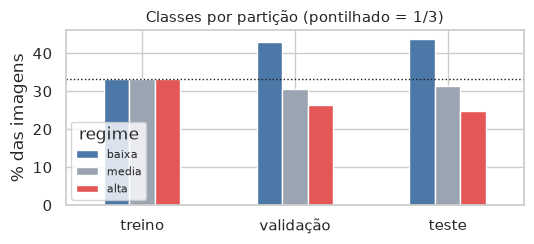

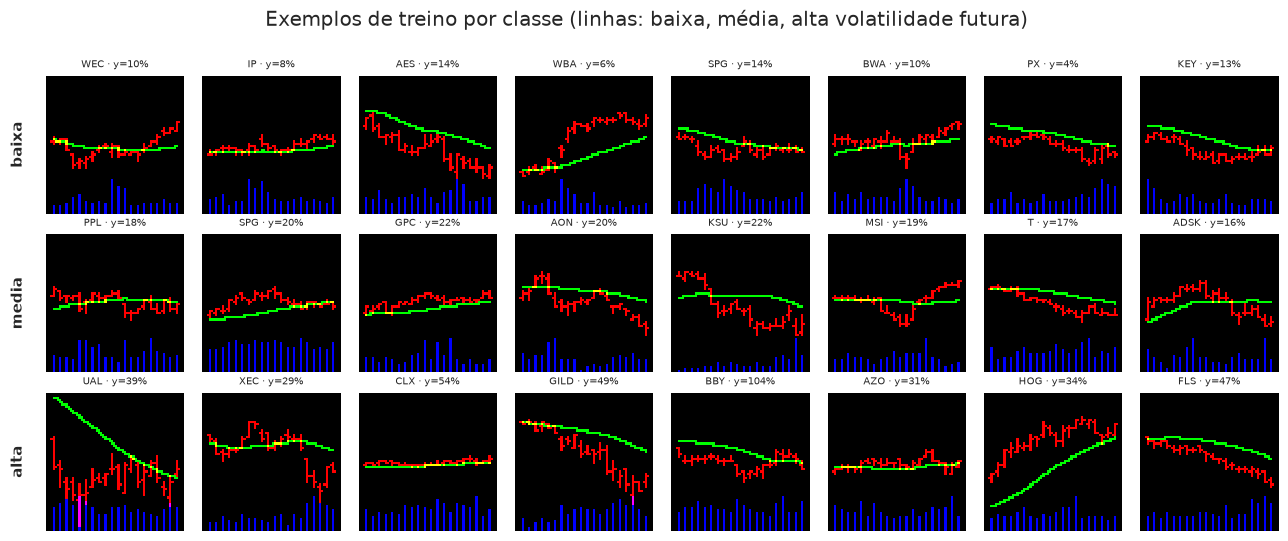

In [51]:
cnn_balance = pd.DataFrame(
    {name: np.bincount(y, minlength=3) for name, y in (("treino", img_y_train), ("validação", img_y_val), ("teste", img_y_test))},
    index=list(REGIME_NAMES),
).T
cnn_balance_pct = cnn_balance.div(cnn_balance.sum(axis=1), axis=0) * 100
display(pd.concat({"imagens": cnn_balance, "%": cnn_balance_pct.round(1)}, axis=1))

fig, ax = plt.subplots(figsize=(5.5, 2.6))
cnn_balance_pct.plot.bar(ax=ax, color=["#4C78A8", "#9AA5B1", "#E45756"], rot=0)
ax.axhline(100 / 3, color="k", ls=":", lw=1)
ax.set_ylabel("% das imagens")
ax.set_title("Classes por partição (pontilhado = 1/3)")
ax.legend(title="regime", fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 8, figsize=(13, 5.4))
_rng = np.random.default_rng(1)
for c, name in enumerate(REGIME_NAMES):
    picks = _rng.choice(np.flatnonzero(img_y_train == c), 8, replace=False)
    for ax, k in zip(axes[c], picks, strict=True):
        ax.imshow(img_x_train[k], interpolation="nearest")
        ax.set_title(f"{sp.at[cnn_idx_train[k], 'ticker']} · y={sp.at[cnn_idx_train[k], 'y']:.0%}", fontsize=7)
        ax.axis("off")
    axes[c, 0].text(-0.15, 0.5, name, transform=axes[c, 0].transAxes, rotation=90, ha="right", va="center", fontsize=11, fontweight="bold")
fig.suptitle("Exemplos de treino por classe (linhas: baixa, média, alta volatilidade futura)", y=1.0)
plt.tight_layout()
plt.show()

## 3.4 A CNN, camada a camada

**Reescala visível.** A API entrega os pixels como `float32` em 0–255 e a **primeira camada do modelo é `Rescaling(1/255)`**:
a normalização (exigida pelo enunciado, item 3.1.1) fica *dentro* do grafo e, portanto, vai junto na exportação.

**Ponto de partida** (blocos conv → pool, depois uma cabeça densa):

`Input(64,64,3)` → `Rescaling(1/255)` → 3 × [`Conv2D(3×3, same)` → `BatchNormalization` → `ReLU` → `MaxPooling2D(2)`] →
`Flatten` → `Dense(64, relu)` → `Dropout(0,5)` → `Dense(3, softmax)`

Tamanho dos mapas: 64×64 → 32×32 → 16×16 → 8×8; o `Flatten` vê 8·8·32 = 2.048 valores. A largura (8/16/32 filtros) sai
da medição do tempo de época na CPU (célula abaixo): o objetivo é ≲ 60 s por época com ~60 mil imagens.

A **única camada própria** é `VerticalJitter`, usada só na ablação de *augmentation*: desloca verticalmente, de até ±3 linhas,
os canais de preço (OHLC e média móvel) **sem tocar no volume**. Somar uma constante ao log-preço **não altera a volatilidade**,
então o rótulo continua válido. Já espelhar horizontalmente (`RandomFlip`) inverteria o eixo do tempo e trocaria a abertura
pelo fechamento, o que **quebra a semântica do gráfico**; por isso não é usado.

In [52]:
class VerticalJitter(layers.Layer):
    """Desloca os canais de preco (0 e 1) por ``s`` linhas, ``s`` inteiro uniforme em [-max_shift, max_shift], so no treino."""

    trinet_augmentation = True  # o export remove a camada do clone de inferencia

    def __init__(self, max_shift: int = 3, **kwargs):
        super().__init__(**kwargs)
        self.max_shift = int(max_shift)

    def call(self, x, training=None):
        if not training or self.max_shift == 0:
            return x
        shift = tf.random.uniform([tf.shape(x)[0]], -self.max_shift, self.max_shift + 1, dtype=tf.int32)
        src = tf.range(CHART_SIZE)[None, :] + shift[:, None]  # (N, 64): linha de origem de cada linha
        inside = tf.cast((src >= 0) & (src < CHART_SIZE), x.dtype)[:, :, None, None]
        moved = tf.gather(x, tf.clip_by_value(src, 0, CHART_SIZE - 1), axis=1, batch_dims=1) * inside
        return tf.concat([moved[..., :2], x[..., 2:]], axis=-1)  # volume (canal 2) fica no lugar

    def get_config(self):
        return {**super().get_config(), "max_shift": self.max_shift}


def build_cnn(filters=(8, 16, 32), dense=64, dropout=0.5, jitter=0, n_classes=3, name="candlestick_cnn"):
    """Monta a CNN camada a camada. ``filters`` = um bloco conv por entrada; ``jitter`` > 0 liga a augmentation."""
    stack = [layers.Input((CHART_SIZE, CHART_SIZE, 3), name="chart"), layers.Rescaling(1 / 255, name="rescaling")]
    if jitter:
        stack.append(VerticalJitter(jitter, name="vertical_jitter"))
    for i, f in enumerate(filters, start=1):
        stack += [
            layers.Conv2D(f, 3, padding="same", name=f"conv{i}"),
            layers.BatchNormalization(name=f"bn{i}"),
            layers.ReLU(name=f"relu{i}"),
            layers.MaxPooling2D(2, name=f"pool{i}"),
        ]
    stack += [layers.Flatten(name="flatten"), layers.Dense(dense, activation="relu", name="dense")]
    if dropout:
        stack.append(layers.Dropout(dropout, name="dropout"))
    stack.append(layers.Dense(n_classes, activation="softmax", name="output"))
    return keras.Sequential(stack, name=name)


class EpochTimer(keras.callbacks.Callback):
    """Segundos de cada época."""

    def on_train_begin(self, logs=None):
        self.seconds = []

    def on_epoch_begin(self, epoch, logs=None):
        self._t = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.seconds.append(time.time() - self._t)


class ImageBatches(keras.utils.PyDataset):
    """Lotes fatiados direto do array ``uint8`` (embaralha a cada época se ``shuffle``), opcionalmente só nas linhas ``rows``.

    Passar o array inteiro ao ``fit`` faz o Keras copiá-lo para um tensor (dobra a memória de ~1 GB de imagens), e ``x[rows]`` copiaria
    o subconjunto a cada treino; fatiar por lote evita as duas cópias.
    """

    def __init__(self, x, y, *, batch_size, rows=None, shuffle=False, seed=0):
        super().__init__()
        self.x, self.y, self.batch_size, self.shuffle = x, y, batch_size, shuffle
        self.rows = np.arange(len(x)) if rows is None else np.asarray(rows)
        self._rng = np.random.default_rng(seed)
        self._order = self._rng.permutation(len(self.rows)) if shuffle else np.arange(len(self.rows))

    def __len__(self):
        return int(np.ceil(len(self.rows) / self.batch_size))

    def __getitem__(self, i):
        idx = self.rows[np.sort(self._order[i * self.batch_size : (i + 1) * self.batch_size])]
        return self.x[idx], self.y[idx]

    def on_epoch_end(self):
        if self.shuffle:
            self._order = self._rng.permutation(len(self.rows))


def fit_cnn(cfg, x_tr, y_tr, x_va, y_va, *, epochs, seed, lr=1e-3, patience=None, plateau=False, batch_size=128, rows=None, verbose=0):
    """Treina uma CNN do zero (loss e metrica do enunciado); com ``patience``, EarlyStopping(restore_best_weights).

    ``rows`` restringe o treino a essas linhas de ``x_tr``/``y_tr`` (sem copiar as imagens).
    """
    gc.collect()  # libera o modelo e os grafos do treino anterior (ciclos Keras/TF) antes de criar outro
    keras.utils.set_random_seed(seed)
    model = build_cnn(**cfg)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    timer = EpochTimer()
    callbacks = [timer]
    if patience:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True))
    if plateau:
        callbacks.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5))
    train = ImageBatches(x_tr, y_tr, batch_size=batch_size, rows=rows, shuffle=True, seed=seed)
    valid = ImageBatches(x_va, y_va, batch_size=512)
    hist = model.fit(train, validation_data=valid, epochs=epochs, callbacks=callbacks, verbose=verbose)
    return model, hist.history, timer.seconds


CNN_BASE_CFG = {"filters": (8, 16, 32), "dense": 64, "dropout": 0.5, "jitter": 0}
build_cnn(**CNN_BASE_CFG).summary()

Model: "candlestick_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 64, 64, 8)      │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 64, 64, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 32, 32, 16)     │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 16, 16, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 137,587 (537.45 KB)

 Trainable params: 137,475 (537.01 KB)

 Non-trainable params: 112 (448.00 B)

### Dimensionando para a CPU: tempo da primeira época

O orçamento é **≲ 60 s por época** com ~60 mil imagens. Para escolher a largura, cronometramos uma época de 6 mil imagens
(depois de uma época de aquecimento) para 4 larguras do mesmo desenho e extrapolamos para o treino inteiro. Depois, a 1ª época
**real** da configuração base no treino completo.

In [53]:
_probe = slice(0, 6_000)
_rows = []
for _filters in [(8, 16, 32), (12, 24, 48), (16, 32, 64), (32, 64, 128)]:
    _cfg = {**CNN_BASE_CFG, "filters": _filters}
    _m, _h, _sec = fit_cnn(_cfg, img_x_train[_probe], img_y_train[_probe], img_x_val[:512], img_y_val[:512], epochs=2, seed=0)
    _rows.append({"filtros": "/".join(map(str, _filters)), "parâmetros": _m.count_params(), "s por época (extrapolado p/ o treino todo)": _sec[1] / 6_000 * len(img_x_train)})
cnn_sizing = pd.DataFrame(_rows).set_index("filtros")
display(cnn_sizing.style.format({"parâmetros": "{:,d}", "s por época (extrapolado p/ o treino todo)": "{:.0f}"}))

_m, _h, _sec = fit_cnn(CNN_BASE_CFG, img_x_train, img_y_train, img_x_val, img_y_val, epochs=1, seed=CNN_SEED)
cnn_first_epoch_seconds = _sec[0]
print(f"1ª época da base (8/16/32), treino completo ({len(img_x_train):,d} imagens): {cnn_first_epoch_seconds:.1f}s | parâmetros: {_m.count_params():,d} | val acc {_h['val_accuracy'][0]:.3f}")
del _m

,parâmetros,s por época (extrapolado p/ o treino todo)
filtros,,
8/16/32,"137,587",35
12/24/48,"210,571",61
16/32/64,"286,435",73
32/64/128,"618,691",164


1ª época da base (8/16/32), treino completo (56,956 imagens): 35.5s | parâmetros: 137,587 | val acc 0.460


## 3.5 Justificativas das escolhas

### Justificativa: Arquitetura (Rede 3)

- **Ativação das ocultas: ReLU** (nas convoluções e na densa). Não satura para entradas positivas (gradiente 1), é barata na CPU e produz
  mapas **esparsos**, o que combina com imagens de pixels 0/255. `sigmoid` e `tanh` saturam e atrasam o treino de redes mais fundas; `softmax`
  só faz sentido na saída. A `BatchNormalization` antes de cada ReLU estabiliza a escala dos mapas (o gráfico tem muitos pixels apagados e
  poucos acesos, então a distribuição das ativações é bem assimétrica).
- **Profundidade × largura das convoluções:** 3 blocos `Conv2D(3×3)` com **8, 16 e 32 filtros** (a largura dobra a cada `MaxPooling2D`, que divide
  a área por 4, então o custo por camada fica parecido). Cada bloco aumenta o **campo receptivo**: ao fim do terceiro, um neurônio vê
  ~22 px (≈ 7 pregões de 3 px); o `Flatten` + `Dense(64)` integram a janela inteira de 20 pregões. A largura foi limitada pelo **orçamento de
  CPU** (≲ 60 s por época): a tabela de dimensionamento acima mostra o tempo por época subindo de ≈ 30–40 s (8/16/32) para ≈ 70 s (16/32/64) e
  ≈ 160–180 s (32/64/128) no treino todo (os segundos variam com a carga da máquina). A **ablação** (próxima seção) compara a base com uma versão
  **mais rasa** (2 blocos) e uma **mais larga** (16/32/64).
- **Cabeça densa:** `Flatten` (8·8·32 = 2.048 valores) → `Dense(64, relu)` → `Dropout`. Essa camada concentra ~95% dos parâmetros da base e é o
  principal vetor de *overfitting*, por isso o `Dropout(0,5)` (e a variação 0,25 na ablação).
- **Saída: `Dense(3, softmax)`.** As três classes (`baixa`, `media`, `alta`) são **mutuamente exclusivas**; o `softmax` devolve uma distribuição de
  probabilidade que soma 1, e é essa distribuição que a API devolve.

### Justificativa: Compilação (Rede 3)

- **Loss: `sparse_categorical_crossentropy`.** É a entropia cruzada (log-verossimilhança) para o `softmax`; "sparse" porque os rótulos são os inteiros
  0/1/2, sem precisar de one-hot. Penaliza com força apostas confiantes e erradas, e dá probabilidades utilizáveis.
- **Otimizador: Adam** (taxa 1e-3), com `ReduceLROnPlateau` (×0,5 após 2 épocas sem melhora da loss de validação) e `EarlyStopping`
  (paciência 4, `restore_best_weights`). O Adam adapta o passo por parâmetro, o que ajuda com a escala irregular dos mapas de uma CNN do zero;
  a redução por platô troca "quantas épocas treinar" por um critério medido na validação. A varredura curta da seção seguinte compara 3e-4, 1e-3 e
  3e-3 (3 seeds cada) e é lida com cuidado: o desvio entre seeds é grande nesse tamanho de amostra.
- **Métrica: acurácia** (exigida pelo enunciado). O treino tem as 3 classes quase balanceadas (por construção dos tercis), então a acurácia é
  informativa e o piso é 1/3. Como a validação e o teste **não** são balanceados (o mercado mudou de regime), a avaliação final também mostra a
  **matriz de confusão** e o relatório por classe (precisão, revocação e F1), além da comparação com baselines.

## 3.6 Ablação de configurações

Em vez de um *tuner*, uma **ablação manual** com 5 configurações, avaliadas por **acurácia de validação** (média ± desvio de **3 seeds**), em
**12 mil imagens de treino** e até 8 épocas (`EarlyStopping` com paciência 3 e `restore_best_weights`), para caber no orçamento de CPU. O
resultado é um **ranking de configurações**, não a acurácia final (a escolhida é re-treinada no treino inteiro). A regra de escolha é fixada
antes de olhar o teste: entre as configurações que **cabem no orçamento de CPU** (≲ 60 s por época no treino todo, pela tabela da seção 3.4), a de maior
acurácia média de validação; se houver empate dentro de 0,5 pp, a de menos parâmetros.

| config | o que muda em relação à base (`8/16/32`, `Dropout(0,5)`) |
|---|---|
| **base** | ponto de partida |
| **dropout 0,25** | menos regularização na cabeça densa |
| **augmentation (jitter ±3 linhas)** | `VerticalJitter` só no treino: desloca o preço verticalmente (preserva a volatilidade) |
| **mais rasa (2 blocos)** | `8/16` filtros; o `Flatten` passa a ver 16·16·16 = 4.096 valores (mais parâmetros na cabeça densa, menos convoluções) |
| **mais larga (16/32/64)** | dobra os filtros; **referência** para ver se mais capacidade ajuda. Custa ≈ 2× o tempo por época e estoura o orçamento, então **não concorre** à escolha |

In [54]:
CNN_ABL_TRAIN, CNN_ABL_EPOCHS, CNN_ABL_SEEDS = 12_000, 8, (0, 1, 2)
CNN_ABLATION = {
    "base": CNN_BASE_CFG,
    "dropout 0,25": {**CNN_BASE_CFG, "dropout": 0.25},
    "augmentation (jitter ±3 linhas)": {**CNN_BASE_CFG, "jitter": 3},
    "mais rasa (2 blocos)": {**CNN_BASE_CFG, "filters": (8, 16)},
    "mais larga (16/32/64, extra)": {**CNN_BASE_CFG, "filters": (16, 32, 64)},
}
_sub = np.random.default_rng(CNN_SEED).permutation(len(img_x_train))[:CNN_ABL_TRAIN]
_rows, ablation_runs, ablation_scores = [], {}, {}
_t0 = time.time()
for _name, _cfg in CNN_ABLATION.items():
    _accs, _losses, _secs = [], [], []
    for _seed in CNN_ABL_SEEDS:
        _m, _h, _sec = fit_cnn(_cfg, img_x_train, img_y_train, img_x_val, img_y_val, epochs=CNN_ABL_EPOCHS, seed=_seed, patience=3, rows=_sub)
        _loss, _acc = _m.evaluate(img_x_val, img_y_val, batch_size=512, verbose=0)  # pesos restaurados (melhor val_loss)
        _accs.append(_acc)
        _losses.append(_loss)
        _secs.append(np.mean(_sec))
        ablation_runs[(_name, _seed)] = _h
        ablation_scores[(_name, _seed)] = (_loss, _acc)
    _rows.append(
        {
            "configuração": _name,
            "parâmetros": _m.count_params(),
            "val acc (média)": np.mean(_accs),
            "val acc (desvio)": np.std(_accs),
            "val loss (média)": np.mean(_losses),
            "s/época": np.mean(_secs),
        }
    )
cnn_ablation = pd.DataFrame(_rows).set_index("configuração")
print(f"ablação concluída em {(time.time() - _t0) / 60:.1f} min ({len(CNN_ABLATION)} configurações × {len(CNN_ABL_SEEDS)} seeds, {CNN_ABL_TRAIN:,d} imagens, até {CNN_ABL_EPOCHS} épocas)")
cnn_ablation.style.format({"parâmetros": "{:,d}", "val acc (média)": "{:.3f}", "val acc (desvio)": "{:.3f}", "val loss (média)": "{:.3f}", "s/época": "{:.1f}"})

ablação concluída em 21.4 min (5 configurações × 3 seeds, 12,000 imagens, até 8 épocas)


,parâmetros,val acc (média),val acc (desvio),val loss (média),s/época
configuração,,,,,
base,"137,587",0.509,0.004,1.002,8.8
"dropout 0,25","137,587",0.485,0.040,1.027,9.0
augmentation (jitter ±3 linhas),"137,587",0.512,0.004,1.005,9.1
mais rasa (2 blocos),"263,891",0.507,0.005,1.015,8.1
"mais larga (16/32/64, extra)","286,435",0.516,0.004,1.027,18.2


### Taxa de aprendizado (varredura curta na configuração base)

Mesmo subconjunto, mesmas épocas e **as mesmas 3 seeds** da ablação, para dar **evidência** (e não só convenção) à escolha da taxa do
Adam. A linha de `1e-3` reaproveita as execuções da configuração `base` da ablação (idênticas em tudo), então só 2 taxas são treinadas.

In [55]:
CNN_LR_VALUES = (3e-4, 1e-3, 3e-3)
_rows = []
for _lr in CNN_LR_VALUES:
    _res = []
    for _seed in CNN_ABL_SEEDS:
        if _lr == 1e-3:  # = configuracao "base" da ablacao (mesmos dados, seed e callbacks)
            _loss, _acc = ablation_scores[("base", _seed)]
            _best = int(np.argmin(ablation_runs[("base", _seed)]["val_loss"])) + 1
        else:
            _m, _h, _sec = fit_cnn(CNN_BASE_CFG, img_x_train, img_y_train, img_x_val, img_y_val, epochs=CNN_ABL_EPOCHS, seed=_seed, lr=_lr, patience=3, rows=_sub)
            _loss, _acc = _m.evaluate(img_x_val, img_y_val, batch_size=512, verbose=0)
            _best = int(np.argmin(_h["val_loss"])) + 1
        _res.append((_acc, _loss, _best))
    _a, _l, _b = np.array(_res).T
    _rows.append({"taxa de aprendizado": _lr, "val acc (média)": _a.mean(), "val acc (desvio)": _a.std(), "val loss (média)": _l.mean(), "melhor época (média)": _b.mean()})
cnn_lr_table = pd.DataFrame(_rows).set_index("taxa de aprendizado")
cnn_lr_table.style.format({"val acc (média)": "{:.3f}", "val acc (desvio)": "{:.3f}", "val loss (média)": "{:.3f}", "melhor época (média)": "{:.1f}"})

,val acc (média),val acc (desvio),val loss (média),melhor época (média)
taxa de aprendizado,,,,
0.000300,0.508,0.003,0.994,7.3
0.001000,0.509,0.004,1.002,8.0
0.003000,0.478,0.035,1.040,5.7


### Leitura da ablação e da taxa de aprendizado

*(Números da execução de referência; ao reexecutar, mudam na segunda casa decimal. Seeds e ordem dos lotes mexem alguns pontos percentuais com 12 mil imagens.)*

- **Quase tudo empata.** `base`, `augmentation` e `mais rasa` ficam em ≈ 0,507–0,512 de acurácia de validação (desvios de até ≈ 0,7 pp entre seeds) e a `mais larga`
  em ≈ 0,516: diferenças menores que o ruído que a própria ablação mede. A única diferença que parece sinal é a de `dropout 0,25`
  (≈ 2,5 pp abaixo, com um desvio de ≈ 4 pp: alguma seed oscilou muito), compatível com "menos regularização desestabiliza uma cabeça densa com
  131 mil pesos", mas não conclusiva com 3 seeds.
- **Capacidade não é o gargalo.** Dobrar os filtros não ajuda de forma relevante e custa ≈ 2× o tempo por época (por isso está fora da escolha). O sinal
  de volatilidade no gráfico é grosseiro (amplitude das barras, tamanho do volume) e já cabe em ~140 mil parâmetros.
- **Escolha.** Pela regra (dentro do orçamento de tempo, empate de 0,5 pp resolvido por menos parâmetros), fica a `base` (8/16/32, `Dropout(0,5)`).
  Em execuções anteriores, com outra ordem de embaralhamento, a média da `base` chegou a cair para ≈ 0,48 (desvio ≈ 4 pp) e a `mais rasa` ficou
  na frente; por isso o notebook usa 3 seeds e uma regra de desempate explícita, em vez de apostar numa única corrida.
- **Taxa de aprendizado.** `3e-4` e `1e-3` empatam (≈ 0,508 e 0,509). `3e-3` tem média menor e um desvio ≈ 10× maior (instável, a loss de
  validação oscila de época a época). `3e-4` só chegaria ao mínimo perto da 8ª época (a "melhor época" média fica em ≈ 7–8 de 8), então custaria mais
  épocas para o mesmo resultado. Mantemos **`1e-3` com `ReduceLROnPlateau`**: é o ponto estável e mais rápido da varredura.

## 3.7 Treino final e curvas

A configuração escolhida é re-treinada **do zero no treino inteiro** (~60 mil imagens), com `EarlyStopping(monitor="val_loss", patience=4,
restore_best_weights=True)` e `ReduceLROnPlateau`, até 20 épocas. As curvas mostram treino × validação; a linha pontilhada marca a melhor
época (os pesos dessa época são os que seguem para o teste).

**Configuração escolhida pela ablação:** `base` → `{'filters': (8, 16, 32), 'dense': 64, 'dropout': 0.5, 'jitter': 0}`  
Fora do orçamento de 60 s/época (não concorre): `mais larga (16/32/64, extra)` (73 s/época)

Epoch 1/20


445/445 - 36s - 81ms/step - accuracy: 0.4425 - loss: 1.0644 - val_accuracy: 0.4602 - val_loss: 1.0620 - learning_rate: 0.0010


Epoch 2/20


445/445 - 34s - 77ms/step - accuracy: 0.4816 - loss: 1.0122 - val_accuracy: 0.5169 - val_loss: 1.0143 - learning_rate: 0.0010


Epoch 3/20


... (8 outputs left out)

445/445 - 37s - 82ms/step - accuracy: 0.4944 - loss: 0.9954 - val_accuracy: 0.5208 - val_loss: 1.0045 - learning_rate: 5.0000e-04


Epoch 8/20


445/445 - 35s - 78ms/step - accuracy: 0.4952 - loss: 0.9946 - val_accuracy: 0.5144 - val_loss: 1.0059 - learning_rate: 5.0000e-04



parâmetros 137,587 | 8 épocas, 34.9s/época (4.7 min no total) | melhor época 4 | val acc 0.520, val loss 1.003


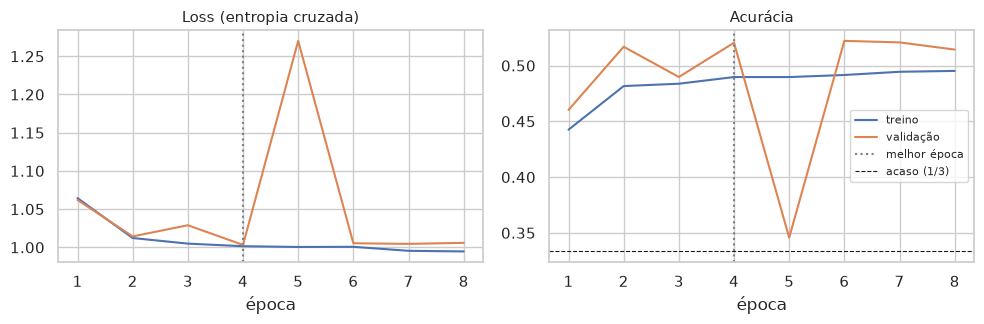

In [56]:
# Regra de escolha (fixada antes de olhar o teste): entre as configurações que cabem no orçamento de CPU (tempo por época no treino todo,
# tabela de dimensionamento da seção 3.4), a de maior acurácia média de validação; empate dentro de 0,5 pp -> menos parâmetros.
CNN_EPOCH_BUDGET_S = 60
_cost_col = "s por época (extrapolado p/ o treino todo)"


def cnn_epoch_cost(cfg: dict) -> float:
    """Segundos por época (treino todo) da largura ``cfg['filters']``; sem linha na tabela de dimensionamento, o custo da base (limite superior)."""
    return float(cnn_sizing[_cost_col].get("/".join(map(str, cfg["filters"])), cnn_sizing[_cost_col].iloc[0]))


cnn_ablation["cabe no orçamento"] = [cnn_epoch_cost(CNN_ABLATION[n]) <= CNN_EPOCH_BUDGET_S for n in cnn_ablation.index]
_pool = cnn_ablation[cnn_ablation["cabe no orçamento"]]
_near = _pool[_pool["val acc (média)"] >= _pool["val acc (média)"].max() - 0.005]
cnn_choice = str(_near["parâmetros"].idxmin())
cnn_cfg = CNN_ABLATION[cnn_choice]
_out = ", ".join(f"`{n}` ({cnn_epoch_cost(CNN_ABLATION[n]):.0f} s/época)" for n in cnn_ablation.index[~cnn_ablation["cabe no orçamento"]])
display(Markdown(f"**Configuração escolhida pela ablação:** `{cnn_choice}` → `{cnn_cfg}`" + (f"  \nFora do orçamento de {CNN_EPOCH_BUDGET_S} s/época (não concorre): {_out}" if _out else "")))

CNN_FINAL_EPOCHS = 20
cnn_model, cnn_history, _secs = fit_cnn(
    cnn_cfg, img_x_train, img_y_train, img_x_val, img_y_val, epochs=CNN_FINAL_EPOCHS, seed=CNN_SEED, patience=4, plateau=True, verbose=2
)
cnn_epoch_seconds = float(np.mean(_secs))
cnn_best_epoch = int(np.argmin(cnn_history["val_loss"])) + 1
cnn_val_loss, cnn_val_acc = cnn_model.evaluate(img_x_val, img_y_val, batch_size=512, verbose=0)  # pesos restaurados (melhor val_loss)
print(
    f"\nparâmetros {cnn_model.count_params():,d} | {len(_secs)} épocas, {cnn_epoch_seconds:.1f}s/época "
    f"({sum(_secs) / 60:.1f} min no total) | melhor época {cnn_best_epoch} | val acc {cnn_val_acc:.3f}, val loss {cnn_val_loss:.3f}"
)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
_epochs = np.arange(1, len(cnn_history["loss"]) + 1)
for ax, key, title in zip(axes, ("loss", "accuracy"), ("Loss (entropia cruzada)", "Acurácia"), strict=True):
    ax.plot(_epochs, cnn_history[key], label="treino")
    ax.plot(_epochs, cnn_history[f"val_{key}"], label="validação")
    ax.axvline(cnn_best_epoch, color="gray", ls=":", label="melhor época")
    ax.set_xlabel("época")
    ax.set_title(title)
axes[1].axhline(1 / 3, color="k", ls="--", lw=0.8, label="acaso (1/3)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3.8 Avaliação no teste (tocado uma única vez)

ACURÁCIA NO TESTE: 52.494%  (IC 95% ≈ ±0.9%; 12,830 imagens)
acaso (1/3): 33,3% | classe do treino mais frequente ('baixa') no teste: 43.8% | validação: 52.0%


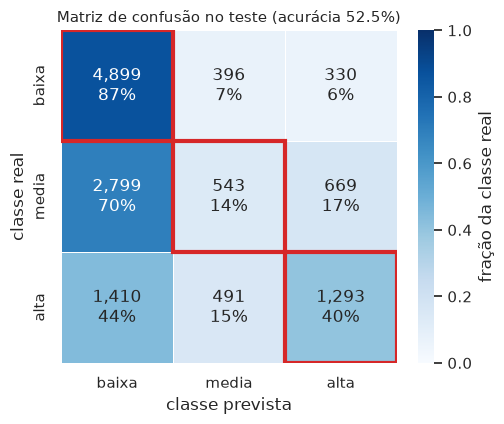

              precision    recall  f1-score   support

       baixa      0.538     0.871     0.665      5625
       media      0.380     0.135     0.200      4011
        alta      0.564     0.405     0.471      3194

    accuracy                          0.525     12830
   macro avg      0.494     0.470     0.445     12830
weighted avg      0.495     0.525     0.471     12830



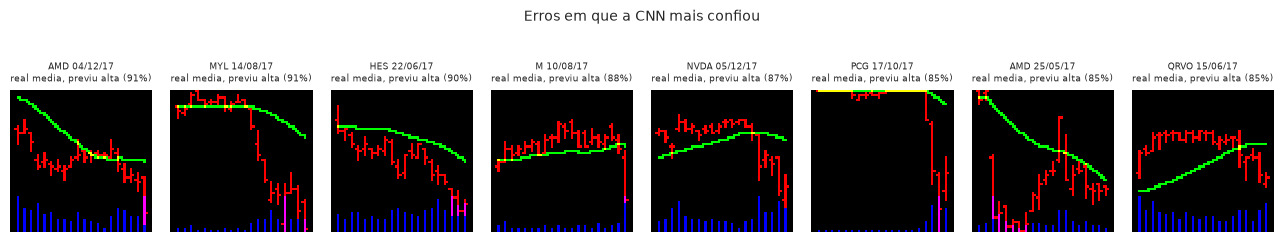

In [57]:
cnn_probs_test = cnn_model.predict(img_x_test, batch_size=512, verbose=0)
cnn_pred_test = cnn_probs_test.argmax(axis=1)
cnn_test_acc = float((cnn_pred_test == img_y_test).mean())
cnn_confusion = confusion_matrix(img_y_test, cnn_pred_test, labels=[0, 1, 2])
_half = 1.96 * np.sqrt(cnn_test_acc * (1 - cnn_test_acc) / len(img_y_test))
_major = int(np.bincount(img_y_train).argmax())
print(f"ACURÁCIA NO TESTE: {cnn_test_acc:.3%}  (IC 95% ≈ ±{_half:.1%}; {len(img_y_test):,d} imagens)")
print(f"acaso (1/3): 33,3% | classe do treino mais frequente ('{REGIME_NAMES[_major]}') no teste: {(img_y_test == _major).mean():.1%} | validação: {cnn_val_acc:.1%}")

fig, ax = plt.subplots(figsize=(5.2, 4.4))
_pct = cnn_confusion / cnn_confusion.sum(axis=1, keepdims=True)
sns.heatmap(
    _pct,
    annot=np.array([[f"{n:,d}\n{p:.0%}" for n, p in zip(rn, rp, strict=True)] for rn, rp in zip(cnn_confusion, _pct, strict=True)]),
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "fração da classe real"},
    xticklabels=REGIME_NAMES,
    yticklabels=REGIME_NAMES,
    linewidths=0.5,
    ax=ax,
)
for i in range(3):  # destaca os acertos (diagonal)
    ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor="#D62728", lw=3))
ax.set_xlabel("classe prevista")
ax.set_ylabel("classe real")
ax.set_title(f"Matriz de confusão no teste (acurácia {cnn_test_acc:.1%})")
plt.tight_layout()
plt.show()

print(classification_report(img_y_test, cnn_pred_test, target_names=REGIME_NAMES, digits=3))

# Erros mais "confiantes": imagens em que a CNN apostou alto na classe errada.
_wrong = np.flatnonzero(cnn_pred_test != img_y_test)
_worst = _wrong[np.argsort(-cnn_probs_test[_wrong, cnn_pred_test[_wrong]])[:8]]
fig, axes = plt.subplots(1, 8, figsize=(13, 2.5))
for ax, k in zip(axes, _worst, strict=True):
    ax.imshow(img_x_test[k], interpolation="nearest")
    ax.set_title(
        f"{sp.at[cnn_idx_test[k], 'ticker']} {sp.at[cnn_idx_test[k], 'date']:%d/%m/%y}\nreal {REGIME_NAMES[img_y_test[k]]}, previu {REGIME_NAMES[cnn_pred_test[k]]} ({cnn_probs_test[k].max():.0%})",
        fontsize=6.5,
    )
    ax.axis("off")
fig.suptitle("Erros em que a CNN mais confiou", y=1.04, fontsize=10)
plt.tight_layout()
plt.show()

## 3.9 Comparação com a Rede 2 (números × imagem) para o mesmo alvo de 3 classes

,acurácia no teste,base
acaso (1/3),0.333,-
classe majoritária do treino,0.438,teste da CNN
HAR logístico (3 features de vol.),0.514,teste da CNN (mesmas imagens)
Rede 2: HAR (variável vol_baseline_acc_har),0.480,"Rede 2, teste completo"
Rede 2: MLP (variável vol_baseline_acc_mlp),0.505,"Rede 2, teste completo"
CNN em gráficos,0.525,teste da CNN


CNN × HAR nas mesmas imagens: CNN acerta e HAR erra 1334; HAR acerta e CNN erra 1194 (McNemar exato, p = 0.00569)


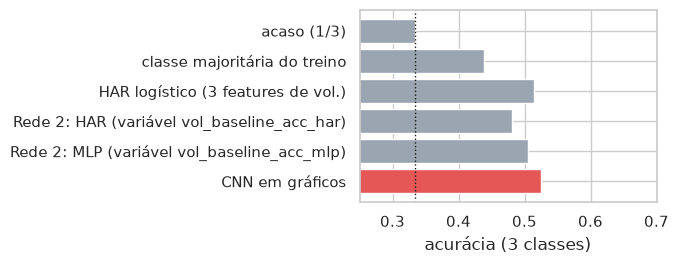

In [58]:
from scipy.stats import binomtest

# Baseline HAR (regressão logística em ln rv_5, ln rv_20, ln rv_60) para o MESMO alvo de 3 classes e as MESMAS imagens
# (mesmo subconjunto com passo). As variaveis ``vol_baseline_acc_*`` vem da Rede 2 (teste completo, sem passo).
_r2 = sp["logret"] ** 2
_rv = {k: np.sqrt(ANN * _r2.groupby(sp["ticker"], sort=False).transform(lambda s, k=k: s.rolling(k).mean())).to_numpy() for k in (5, 20, 60)}
_x_har = np.log(np.maximum(np.column_stack([_rv[k] for k in (5, 20, 60)]), VOL_FLOOR))
_har = LogisticRegression(max_iter=1000).fit(_x_har[cnn_idx_train], img_y_train)
cnn_har_acc_val = float(_har.score(_x_har[cnn_idx_val], img_y_val))
cnn_har_acc_test = float(_har.score(_x_har[cnn_idx_test], img_y_test))
_har_pred = _har.predict(_x_har[cnn_idx_test])
cnn_rede2_available = "vol_baseline_acc_har" in globals()  # False = execucao isolada desta parte (sem a parte 2)
if "vol_baseline_acc_har" not in globals():  # execucao isolada da parte 3: usa o calculo local (a Rede 2 sobrescreve quando existe)
    vol_baseline_acc_har = cnn_har_acc_test
if "vol_baseline_acc_mlp" not in globals():
    vol_baseline_acc_mlp = float("nan")

_cnn_ok, _har_ok = cnn_pred_test == img_y_test, _har_pred == img_y_test
_b, _c = int((_cnn_ok & ~_har_ok).sum()), int((~_cnn_ok & _har_ok).sum())  # discordâncias (McNemar exato)
cnn_vs_har_pvalue = float(binomtest(_b, _b + _c, 0.5).pvalue) if _b + _c else 1.0

cnn_comparison = pd.DataFrame(
    {
        "acurácia no teste": [1 / 3, float((img_y_test == _major).mean()), cnn_har_acc_test, float(vol_baseline_acc_har), float(vol_baseline_acc_mlp), cnn_test_acc],
        "base": ["-", "teste da CNN", "teste da CNN (mesmas imagens)", "Rede 2, teste completo", "Rede 2, teste completo", "teste da CNN"],
    },
    index=["acaso (1/3)", "classe majoritária do treino", "HAR logístico (3 features de vol.)", "Rede 2: HAR (variável vol_baseline_acc_har)", "Rede 2: MLP (variável vol_baseline_acc_mlp)", "CNN em gráficos"],
)
display(cnn_comparison.style.format({"acurácia no teste": "{:.3f}"}, na_rep="n/d"))
print(f"CNN × HAR nas mesmas imagens: CNN acerta e HAR erra {_b}; HAR acerta e CNN erra {_c} (McNemar exato, p = {cnn_vs_har_pvalue:.3g})")

fig, ax = plt.subplots(figsize=(7, 2.8))
_plot = cnn_comparison["acurácia no teste"].dropna()
ax.barh(_plot.index[::-1], _plot.to_numpy()[::-1], color=["#E45756" if n.startswith("CNN") else "#9AA5B1" for n in _plot.index[::-1]])
ax.axvline(1 / 3, color="k", ls=":", lw=1)
ax.set_xlim(0.25, max(0.7, float(_plot.max()) + 0.05))
ax.set_xlabel("acurácia (3 classes)")
plt.tight_layout()
plt.show()

## 3.10 Sanidade: e a direção (sobe/desce)?

O mesmo desenho de CNN (e as mesmas imagens), agora com o alvo **direção**: `1` se `ln(close_{t+5} / close_t) > 0`, `0` caso
contrário (2 classes, `Dense(2, softmax)`). Treino curto em 12 mil imagens, com os mesmos passos de validação. Se a direção
fosse previsível pelo gráfico, a acurácia ficaria bem acima da classe majoritária. O esperado é "perto do acaso".

In [59]:
_ret5 = np.log(sp.groupby("ticker", sort=False)["close"].shift(-HORIZON) / sp["close"]).to_numpy()
_dir = (_ret5 > 0).astype("int64")
cnn_dir_train, cnn_dir_val, cnn_dir_test = _dir[cnn_idx_train], _dir[cnn_idx_val], _dir[cnn_idx_test]
CNN_DIR_TRAIN, CNN_DIR_EPOCHS = 12_000, 6
_sub = np.random.default_rng(CNN_SEED).permutation(len(img_x_train))[:CNN_DIR_TRAIN]
_m, _h, _ = fit_cnn({**cnn_cfg, "n_classes": 2}, img_x_train, cnn_dir_train, img_x_val, cnn_dir_val, epochs=CNN_DIR_EPOCHS, seed=CNN_SEED, patience=3, rows=_sub)
_prior = int(np.bincount(cnn_dir_train).argmax())  # classe mais frequente no treino
cnn_direction_acc = {
    "val": float(_m.evaluate(img_x_val, cnn_dir_val, batch_size=512, verbose=0)[1]),
    "test": float(_m.evaluate(img_x_test, cnn_dir_test, batch_size=512, verbose=0)[1]),
    "test_always_prior_class": float((cnn_dir_test == _prior).mean()),
    "test_share_up": float(cnn_dir_test.mean()),
}
_half = 1.96 * np.sqrt(0.25 / len(cnn_dir_test))
display(
    pd.DataFrame(
        {
            "validação": [cnn_direction_acc["val"], float((cnn_dir_val == _prior).mean())],
            "teste": [cnn_direction_acc["test"], cnn_direction_acc["test_always_prior_class"]],
        },
        index=["CNN (direção)", f"sempre '{'sobe' if _prior else 'desce'}' (classe majoritária do treino)"],
    ).style.format("{:.3f}")
)
print(f"Direção no teste: CNN {cnn_direction_acc['test']:.1%} | acaso 50% (IC 95% ≈ ±{_half:.1%}) | fração de dias de alta no teste: {cnn_direction_acc['test_share_up']:.1%}")
del _m

,validação,teste
CNN (direção),0.527,0.576
sempre 'sobe' (classe majoritária do treino),0.527,0.576


Direção no teste: CNN 57.6% | acaso 50% (IC 95% ≈ ±0.9%) | fração de dias de alta no teste: 57.6%


## 3.11 Previsões em novas instâncias (os 5 últimos pregões)

Os 5 últimos pregões do dataset (`split.new`) ainda **não têm alvo** (faltam os 5 dias futuros) e não pertencem ao teste:
são previsões de verdade "fora da amostra". Sorteamos 12 tickers (seed fixa, `pick_new_tickers`) entre os que têm a janela
completa nos 5 dias, e mostramos o gráfico, o regime previsto e as probabilidades.

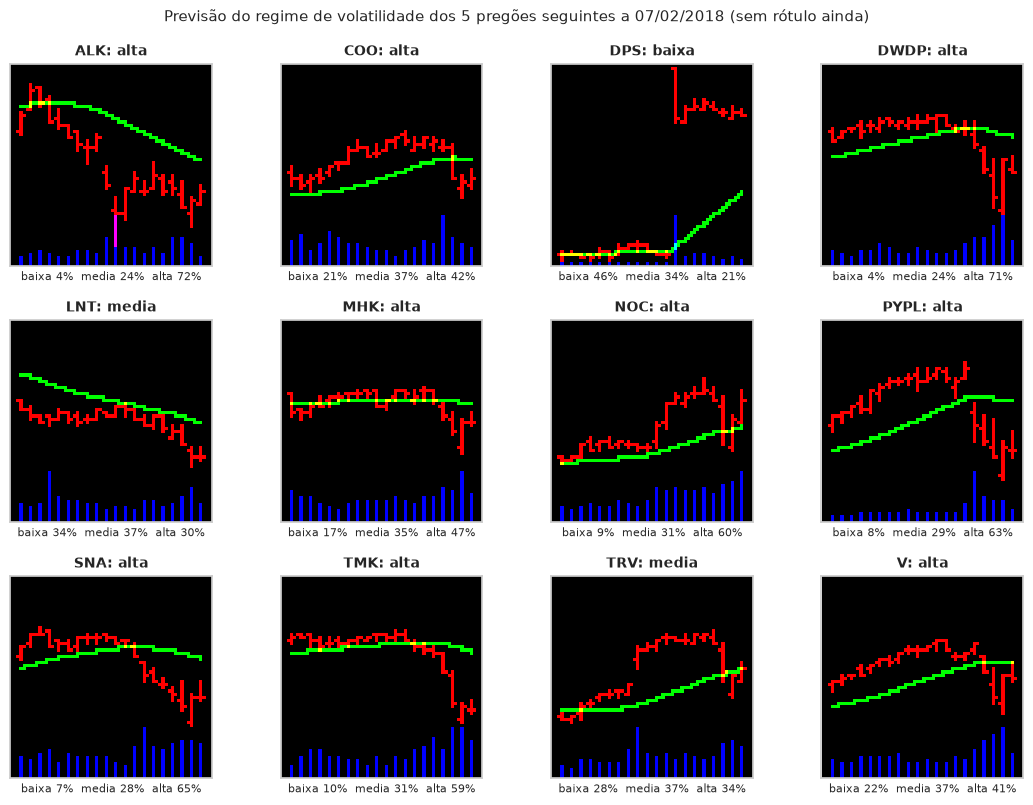

date,01/02,02/02,05/02,06/02,07/02
ticker,,,,,
ALK,alta,alta,alta,alta,alta
COO,baixa,media,media,alta,alta
DPS,baixa,baixa,baixa,baixa,baixa
DWDP,alta,alta,alta,alta,alta
LNT,baixa,baixa,media,alta,media
MHK,baixa,alta,alta,alta,alta
NOC,baixa,baixa,alta,alta,alta
PYPL,alta,alta,alta,alta,alta
SNA,media,alta,alta,alta,alta


In [60]:
_new_mask = (sp["part"].eq("new") & sp["valid_feat"]).to_numpy()
_cand = sp.loc[_new_mask].groupby("ticker").size()
cnn_new_tickers = pick_new_tickers(_cand[_cand == HORIZON].index, k=12, seed=7)
cnn_new_rows = np.flatnonzero(_new_mask & sp["ticker"].isin(cnn_new_tickers).to_numpy())
img_x_new = cnn_render_rows(cnn_new_rows)
cnn_p_new = cnn_model.predict(img_x_new, verbose=0)
cnn_new_predictions = pd.DataFrame(
    {
        "ticker": sp.loc[cnn_new_rows, "ticker"].to_numpy(),
        "date": sp.loc[cnn_new_rows, "date"].to_numpy(),
        "regime previsto": [REGIME_NAMES[k] for k in cnn_p_new.argmax(axis=1)],
        **{f"p({name})": cnn_p_new[:, i] for i, name in enumerate(REGIME_NAMES)},
    }
)
_last = cnn_new_predictions["date"] == cnn_new_predictions["date"].max()
fig, axes = plt.subplots(3, 4, figsize=(11, 8.2))
for ax, k in zip(axes.ravel(), np.flatnonzero(_last.to_numpy()), strict=True):
    row = cnn_new_predictions.iloc[k]
    ax.imshow(img_x_new[k], interpolation="nearest")
    ax.set_title(f"{row['ticker']}: {row['regime previsto']}", fontsize=10, fontweight="bold")
    ax.set_xlabel("  ".join(f"{n} {cnn_p_new[k, i]:.0%}" for i, n in enumerate(REGIME_NAMES)), fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"Previsão do regime de volatilidade dos 5 pregões seguintes a {cnn_new_predictions['date'].max():%d/%m/%Y} (sem rótulo ainda)", fontsize=11)
plt.tight_layout()
plt.show()
display(cnn_new_predictions.pivot(index="ticker", columns="date", values="regime previsto").rename(columns=lambda d: f"{d:%d/%m}"))

## 3.12 Conclusões da Rede 3

- **Resultado.** A CNN que lê só o gráfico (20 pregões, 64×64×3) acerta o regime de volatilidade dos 5 pregões seguintes em ≈ 52% das imagens de teste
  (acaso = 33,3%; sempre prever `baixa` = 43,8%). A acurácia de teste acompanha a de validação, sem sinal de excesso de ajuste ao conjunto de validação.
  O intervalo de 95% (≈ ± 0,9 pp) é **otimista**: as janelas se sobrepõem (passo de 7 pregões, janelas de 20) e as ações do mesmo dia são correlacionadas.
- **O gráfico acrescenta pouco além dos números.** Contra a regressão logística com as 3 features de volatilidade (HAR) nas **mesmas imagens**, a CNN fica
  ≈ 1 pp acima, com McNemar exato p < 0,01. É uma diferença real nesta amostra, mas pequena: boa parte do que a rede "vê" é a amplitude recente das barras,
  que o `ln rv_5`, `ln rv_20` e `ln rv_60` já resumem. Não é um argumento para trocar o modelo tabular pela imagem.
- **Onde erra.** A matriz de confusão mostra um classificador quase **binário**: `baixa` é recuperada em ≈ 87% dos casos, `alta` em ≈ 40% e a classe `media`,
  que fica entre as duas, em apenas ≈ 14% (a rede a empurra para `baixa`). Parte do erro vem do deslocamento de regime: o treino é balanceado por construção
  (tercis), mas validação e teste têm mais dias calmos (≈ 43–44% `baixa`), e o modelo herda um viés para a classe mais calma.
- **Direção continua imprevisível.** Com o mesmo desenho e o alvo sobe/desce, a acurácia de teste coincide com a fração de dias de alta (≈ 57,6%): a rede aprende a
  responder "sobe" sempre. O ganho existe para a **volatilidade**, não para a direção, como na literatura.
- **Limitações.** Um único corte temporal (2013-2018, mercado em geral calmo); uma imagem em baixa resolução, sem antialiasing e com escala vertical fixa; ≈ 57 mil
  imagens de treino por limite de CPU (os trabalhos de referência usam milhões); sem custos de transação ou qualquer estratégia de negociação. Nada disto é recomendação
  de investimento.
- **Para a API.** O modelo exportado (`candlestick-cnn`, ONNX) recebe o **PNG** do gráfico renderizado por `tools/render_chart.py` e devolve as 3 probabilidades.
  O apêndice de exportação confere que o caminho de serving (PNG → Pillow → ONNX Runtime) reproduz as previsões do Keras em todo o teste.

In [61]:
try:
    import resource

    cnn_peak_rss_gb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6  # KB no Linux
except (ImportError, OSError):
    cnn_peak_rss_gb = float("nan")
if "part_times" in globals():
    part_times["30_cnn"] = time.time() - _t_part
print(f"Parte 3 concluída em {(time.time() - _t_part) / 60:.1f} min | pico de memória do processo: {cnn_peak_rss_gb:.1f} GB")

Parte 3 concluída em 42.2 min | pico de memória do processo: 4.8 GB


# 4 · Conclusões

Três redes, construídas camada a camada em `tf.keras.layers`, para três riscos financeiros. As tabelas abaixo resumem o desempenho **no teste** (tocado uma única vez em cada rede) **contra os baselines**,
que são o que dá sentido às métricas: um número isolado não diz se o modelo vale a pena.

## 4.1 Rede 1 · Risco de crédito (classificação)

In [62]:
credit_cols = ["acurácia", "precisão (1)", "revocação (1)", "F1 (1)", "ROC-AUC", "PR-AUC", "KS", "Brier", "custo/cliente"]
show(credit_test_table[credit_cols])
_mlp, _lr, _maj = credit_test_table.loc["MLP (0,5)"], credit_test_table.loc["regressão logística (0,5)"], credit_test_table.loc["maioria (sempre adimplente)"]
_mlp_c, _lr_c = credit_test_table.loc["MLP (limiar por custo)"], credit_test_table.loc["regressão logística (custo)"]
print(f"MLP × regressão logística (teste): ROC-AUC {_mlp['ROC-AUC']:.3f} × {_lr['ROC-AUC']:.3f} | PR-AUC {_mlp['PR-AUC']:.3f} × {_lr['PR-AUC']:.3f} | KS {_mlp['KS']:.3f} × {_lr['KS']:.3f} | Brier {_mlp['Brier']:.3f} × {_lr['Brier']:.3f}")
print(f"Custo por cliente (FN = {COST_FN:g} × FP, premissa ilustrativa): aprovar todos {COST_FN * float(y_test.mean()):.3f} | regressão logística {_lr_c['custo/cliente']:.3f} | MLP {_mlp_c['custo/cliente']:.3f} (limiar {credit_threshold:.2f}, escolhido na validação)")
print(f"Acurácia da classe majoritária: {_maj['acurácia']:.3f} (piso enganoso: revocação 0) | MLP: {_mlp['acurácia']:.3f}")

,acurácia,precisão (1),revocação (1),F1 (1),ROC-AUC,PR-AUC,KS,Brier,custo/cliente
modelo,,,,,,,,,
maioria (sempre adimplente),0.7789,0.0000,0.0000,0.0000,0.5000,0.2211,0.0000,0.2211,1.1053
"regressão logística (0,5)",0.8090,0.7003,0.2377,0.3549,0.7186,0.4897,0.3686,0.1463,0.8651
regressão logística (custo),0.7171,0.4051,0.5972,0.4827,0.7186,0.4897,0.3686,0.1463,0.6391
"MLP (0,5)",0.8201,0.6609,0.3827,0.4847,0.7714,0.5390,0.4151,0.1370,0.7257
MLP (limiar por custo),0.6371,0.3521,0.7633,0.4819,0.7714,0.5390,0.4151,0.1370,0.5721


MLP × regressão logística (teste): ROC-AUC 0.771 × 0.719 | PR-AUC 0.539 × 0.490 | KS 0.415 × 0.369 | Brier 0.137 × 0.146
Custo por cliente (FN = 5 × FP, premissa ilustrativa): aprovar todos 1.105 | regressão logística 0.639 | MLP 0.572 (limiar 0.17, escolhido na validação)
Acurácia da classe majoritária: 0.779 (piso enganoso: revocação 0) | MLP: 0.820


## 4.2 Rede 2 · Risco de mercado, via números (regressão da volatilidade)

In [63]:
vol_cols = ["RMSE", "MAE", "MAE/média", "RMSE/média", "QLIKE", "R² (log)", "viés"]
show(vol_test_table[vol_cols])
_v, _h, _p, _m0 = (vol_test_table.loc[k] for k in ("MLP", "HAR linear", "persistência (rv_5)", "média do treino"))
print(f"MLP × HAR (teste, unidades naturais): RMSE {_v['RMSE']:.4f} × {_h['RMSE']:.4f} ({_v['RMSE'] / _h['RMSE'] - 1:+.1%}) | MAE {_v['MAE']:.4f} × {_h['MAE']:.4f} ({_v['MAE'] / _h['MAE'] - 1:+.1%}) | QLIKE {_v['QLIKE']:.3f} × {_h['QLIKE']:.3f}")
print(f"MLP × persistência: RMSE {_v['RMSE'] / _p['RMSE'] - 1:+.1%}, MAE {_v['MAE'] / _p['MAE'] - 1:+.1%} | MLP × média do treino: RMSE {_v['RMSE'] / _m0['RMSE'] - 1:+.1%}, MAE {_v['MAE'] / _m0['MAE'] - 1:+.1%}")
print(f"Margem de erro relativa do MLP: MAE/média = {_v['MAE/média']:.1%}, RMSE/média = {_v['RMSE/média']:.1%}")

,RMSE,MAE,MAE/média,RMSE/média,QLIKE,R² (log),viés
MLP,0.1332,0.0741,0.3876,0.6971,0.8707,0.2331,-0.0231
HAR linear,0.1354,0.0766,0.4009,0.7088,0.8836,0.1857,-0.0201
persistência (rv_5),0.1748,0.1022,0.5347,0.9149,1.9230,-0.3420,-0.0037
média do treino,0.1459,0.0985,0.5156,0.7633,0.8378,-0.2627,0.0240


MLP × HAR (teste, unidades naturais): RMSE 0.1332 × 0.1354 (-1.6%) | MAE 0.0741 × 0.0766 (-3.3%) | QLIKE 0.871 × 0.884
MLP × persistência: RMSE -23.8%, MAE -27.5% | MLP × média do treino: RMSE -8.7%, MAE -24.8%
Margem de erro relativa do MLP: MAE/média = 38.8%, RMSE/média = 69.7%


## 4.3 Rede 3 · Risco de mercado, via imagem (CNN) e a pergunta "números × imagem"

Mesmo alvo (regime de volatilidade dos próximos 5 pregões: `baixa`, `media`, `alta`, tercis do treino), mesmo período de teste. A CNN vê **só o desenho** do gráfico;
a Rede 2 vê as **25 features numéricas**. A comparação justa usa **as mesmas linhas** de teste (a CNN treina e testa numa subamostra com passo, ver parte 3).
A célula só roda se a parte 3 tiver sido executada nesta sessão (variáveis `cnn_*`); caso contrário, apenas avisa.

In [64]:
if "cnn_test_acc" in globals():
    from scipy.stats import binomtest

    _tidx = parts["test"].index.to_numpy()
    _same = np.isin(_tidx, cnn_idx_test)  # linhas de teste que a CNN também avaliou (ordem de `sp` preservada nas duas listas)
    _true = regime_labels(vy_test[_same], vol_tercile_edges)
    assert _same.sum() == len(img_y_test) and np.array_equal(_true, img_y_test), "rótulos da Rede 2 e da CNN divergem nas mesmas linhas"
    _preds = {
        "CNN (gráficos)": cnn_pred_test,
        "Rede 2: MLP (números)": regime_labels(yhat["MLP"][_same], vol_tercile_edges),
        "HAR linear (números)": regime_labels(yhat["HAR linear"][_same], vol_tercile_edges),
        "persistência rv_5": regime_labels(yhat["persistência (rv_5)"][_same], vol_tercile_edges),
    }

    def _rec(pred, k):
        return float(((pred == k) & (_true == k)).sum() / max(1, (_true == k).sum()))

    vol_vs_cnn = pd.DataFrame(
        {
            n: {
                "acurácia": float((pr == _true).mean()),
                "acurácia balanceada": float(np.mean([_rec(pr, k) for k in range(3)])),
                **{f"revocação {REGIME_NAMES[k]}": _rec(pr, k) for k in range(3)},
            }
            for n, pr in _preds.items()
        }
    ).T
    vol_vs_cnn.loc["classe majoritária"] = [
        float(np.bincount(_true).max() / len(_true)),
        1 / 3,
        *[float(np.bincount(_true).argmax() == k) for k in range(3)],
    ]
    show(vol_vs_cnn)
    print(f"{len(_true):,} linhas de teste em comum | acaso = 33,3% | CNN: validação {cnn_val_acc:.1%}, teste {cnn_test_acc:.1%} | {cnn_epoch_seconds:.0f} s/época")
    print(f"Custo de treino: CNN {cnn_epoch_seconds * len(cnn_history['loss']) / 60:.1f} min ({len(cnn_history['loss'])} épocas) × MLP da Rede 2 {vol_train_seconds / 60:.1f} min" if "vol_train_seconds" in globals() else "")
    _b = int(((_preds["CNN (gráficos)"] == _true) & (_preds["Rede 2: MLP (números)"] != _true)).sum())
    _c = int(((_preds["CNN (gráficos)"] != _true) & (_preds["Rede 2: MLP (números)"] == _true)).sum())
    cnn_vs_mlp_pvalue = float(binomtest(_b, _b + _c, 0.5).pvalue) if _b + _c else 1.0
    print(f"CNN × MLP nas mesmas linhas: só a CNN acerta {_b}, só o MLP acerta {_c} (McNemar exato, p = {cnn_vs_mlp_pvalue:.3g})")
    if "cnn_vs_har_pvalue" in globals():
        print(f"CNN × HAR nas mesmas imagens: p = {cnn_vs_har_pvalue:.3g} (célula 3.9)")
    if "cnn_direction_acc" in globals():
        print(f"Sanidade, direção (sobe/desce) pela CNN: {cnn_direction_acc.get('test', float('nan')):.1%} no teste | sempre a classe majoritária: {cnn_direction_acc.get('test_always_prior_class', float('nan')):.1%} | acaso 50%")
    _acc = {n: float((pr == _true).mean()) for n, pr in _preds.items()}
    _bal = {n: float(vol_vs_cnn.loc[n, "acurácia balanceada"]) for n in _preds}
    _best_num = max(_acc["Rede 2: MLP (números)"], _acc["HAR linear (números)"])
    _gap = _acc["CNN (gráficos)"] - _best_num
    _bal_gap = _bal["CNN (gráficos)"] - max(_bal["Rede 2: MLP (números)"], _bal["HAR linear (números)"])
    if _gap > 0.01 and cnn_vs_mlp_pvalue < 0.05 and _bal_gap > 0.01:
        print("Leitura: o gráfico supera as features numéricas neste teste, em acurácia e em acurácia balanceada (diferença distinguível do ruído).")
    elif _gap > 0.01 and cnn_vs_mlp_pvalue < 0.05:
        print(
            f"Leitura: a CNN ganha em acurácia bruta ({_gap:+.1%}), mas não em acurácia balanceada ({_bal_gap:+.1%}): a vantagem vem de favorecer `baixa`, "
            "a classe mais frequente no teste (revocação alta nela, baixa em `media`), e não de separar melhor os três regimes. Sem vantagem clara do gráfico, a um custo de treino maior."
        )
    elif _gap < -0.01 and cnn_vs_mlp_pvalue < 0.05:
        print("Leitura: as features numéricas superam o gráfico neste teste: a imagem NÃO acrescenta nada mensurável e custa mais caro de treinar (a CNN fica abaixo do MLP/HAR).")
    else:
        print("Leitura: empate técnico entre o gráfico e as features numéricas neste teste: a imagem não acrescenta nada mensurável e custa mais caro de treinar.")
else:
    print("Parte 3 (CNN) não executada nesta sessão: sem comparação números × imagem.")

,acurácia,acurácia balanceada,revocação baixa,revocação media,revocação alta
CNN (gráficos),0.5249,0.4704,0.8709,0.1354,0.4048
Rede 2: MLP (números),0.5096,0.4864,0.5820,0.5662,0.3109
HAR linear (números),0.4775,0.4601,0.5093,0.5866,0.2843
persistência rv_5,0.4565,0.4388,0.5650,0.3418,0.4095
classe majoritária,0.4384,0.3333,1.0000,0.0000,0.0000


12,830 linhas de teste em comum | acaso = 33,3% | CNN: validação 52.0%, teste 52.5% | 35 s/época
Custo de treino: CNN 4.7 min (8 épocas) × MLP da Rede 2 0.2 min
CNN × MLP nas mesmas linhas: só a CNN acerta 2064, só o MLP acerta 1867 (McNemar exato, p = 0.00177)
CNN × HAR nas mesmas imagens: p = 0.00569 (célula 3.9)
Sanidade, direção (sobe/desce) pela CNN: 57.6% no teste | sempre a classe majoritária: 57.6% | acaso 50%
Leitura: a CNN ganha em acurácia bruta (+1.5%), mas não em acurácia balanceada (-1.6%): a vantagem vem de favorecer `baixa`, a classe mais frequente no teste (revocação alta nela, baixa em `media`), e não de separar melhor os três regimes. Sem vantagem clara do gráfico, a um custo de treino maior.


## 4.4 O que funcionou

- **Ganhos modestos e medidos, não presumidos:** o MLP supera a regressão logística no crédito (ROC-AUC ≈ 0,77 × 0,72, PR-AUC ≈ 0,54 × 0,49) e supera o HAR na volatilidade por **margem pequena**
  (≈ 2% no RMSE e 3% no MAE), diferença que o teste de Diebold-Mariano por pregão (seção 2.9) separa do ruído. Em volatilidade, a **simplicidade venceu**: a rede de uma camada oculta com 32 neurônios foi a melhor na ablação.
- **Normalização visível e dentro do modelo** (`Normalization.adapt` só no treino): as três redes receberam entradas em escala comparável, e a API de inferência recebe valores **brutos**, sem *skew* de pré-processamento.
- **Métricas escolhidas pelo problema**, não pelo costume: PR-AUC, KS e custo para o crédito desbalanceado (a acurácia da classe majoritária engana); RMSE/MAE **em unidades naturais** e QLIKE para a volatilidade.
- **Comparar com baselines simples** evitou conclusões falsas: a regressão logística no crédito e o HAR na volatilidade são adversários sérios, e o ganho do MLP sobre eles é medido, não presumido.
- **Ablação curta e rastreável** (largura × profundidade × 3 seeds, com e sem `class_weight`, Huber × MSE) com a **regra do 1 erro-padrão**: escolher a rede mais simples indistinguível da melhor.
- **Validação cronológica com embargo** na volatilidade (70/15/15 por data, 5 pregões de purge) e um **teste unitário de ausência de vazamento** nas features.
- **Limiar por custo** no crédito: trocar o corte arbitrário 0,5 por um custo explícito (ilustrativo) reduz o custo esperado por cliente em relação a "aprovar todos" e ao corte 0,5.

## 4.5 Limitações (leia antes de confiar em qualquer número)

- **Viés de sobrevivência:** o S&P 500 do dataset contém apenas as empresas que **estavam no índice em fev/2018**; quem saiu (falência, aquisição) não aparece. Isso tende a **subestimar** a volatilidade e o risco de cauda.
- **Período curto e regime único:** cinco anos de uma bolsa em alta quase contínua; o teste (mai/2017 a jan/2018) é **muito calmo**, exceto por um **choque no fim** (fevereiro de 2018) que **nenhuma feature de janeiro conhece**. O desempenho em outro regime (2008, 2020) é desconhecido.
- **Deslocamento de regime treino → teste:** o treino é mais agitado que a validação e o teste (as médias do alvo caem), então os baselines e o modelo têm viés de nível; o erro por mês mostra isso.
- **Preços ajustados de fonte não auditada** (Kaggle, licença não verificada): splits e spin-offs sem ajuste geram retornos absurdos; descartamos janelas com `|r| > 0,4`, o que também remove alguns eventos reais (AMD, CHK, WMB).
- **Alvo ruidoso:** a volatilidade "realizada" de **5 retornos** é uma medida barulhenta da volatilidade verdadeira; por isso o R² no log é baixo por construção e o teto de qualquer modelo é modesto.
- **Crédito:** dados de **Taiwan, 2005** (um único banco, antes da crise de 2008); os **custos do limiar (FN = 5 × FP) são ilustrativos**, não de um banco real; a equidade foi medida só por sexo e só em taxas.
- **Amostras pequenas nas novas instâncias:** 20 clientes e 12 tickers × 5 dias servem para **ilustrar o uso**, não para estimar desempenho.

## 4.6 Considerações éticas e de uso

- **Atributos protegidos:** `SEX` e `MARRIAGE` **não são features** (a Regulation B / ECOA, nos EUA, proíbe sexo e estado civil; a idade só em sistemas empiricamente derivados e sem penalizar idosos). Mesmo assim o modelo
  pode reproduzi-los por *proxies*; por isso medimos taxa de aprovação, TPR e FPR por grupo. Medir não é corrigir: uso real exigiria análise jurídica e testes de mitigação.
- **Decisões automatizadas:** a LGPD (art. 20) garante ao titular o direito de **solicitar a revisão** de decisões tomadas unicamente com base em tratamento automatizado (⚠️ confirmar o texto no Planalto). Um modelo de crédito
  real precisaria de explicabilidade por cliente e de um caminho de contestação.
- **Mercado:** os modelos de volatilidade **não são recomendação de investimento**; descrevem risco (agitação), não retorno. Previsões de volatilidade erradas no choque de 2018 mostram como um modelo "calmo" falha justamente quando importa.
- **Dados:** o dataset de crédito é CC BY 4.0 (Yeh, 2009); o S&P 500 do Kaggle tem licença não verificada, então **não é redistribuído** e só imagens **sintéticas** vão para fora do notebook.

## 4.7 Próximos passos

Corrigir o viés de prever a **mediana** na volatilidade (a saída `exp(E[ln y])` fica abaixo da média por desigualdade de Jensen; um fator de suavização `exp(σ²/2)` aproximaria a média), recalibrar as probabilidades do crédito (Platt/isotônica na validação), repetir o diagnóstico de equidade com outros atributos e limiares, validar a volatilidade com **janela deslizante** (*walk-forward*) em mais regimes e
comparar com modelos de volatilidade condicional (GARCH) e com features de opções (VIX por ação) que o dataset não tem.

## 4.8 Fechamento: versões, hardware e tempo de execução

In [65]:
_total = time.time() - NOTEBOOK_T0
print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__} | Keras {keras.__version__} | NumPy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"Hardware: {HW}")
print(f"Seed base: {SEED} | threads do TensorFlow: {'todas' if THREADS == 0 else THREADS}")
times = {k: v / 60 for k, v in part_times.items()}
show(pd.DataFrame({"minutos": times}).round(1))
print(f"Tempo total até aqui (sem o apêndice de exportação): {_total / 60:.1f} min")

Python 3.13.13 | TensorFlow 2.21.0 | Keras 3.15.1 | NumPy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1
Hardware: 11th Gen Intel(R) Core(TM) i7-11370H @ 3.30GHz | 8 threads | 33 GB RAM | GPU: nao (CPU)
Seed base: 42 | threads do TensorFlow: todas


,minutos
10_credit,3.5000
20_volatility,3.0000
30_cnn,42.2000


Tempo total até aqui (sem o apêndice de exportação): 48.9 min


# Apêndice · Exportação das redes tabulares para a API (`credit-default-mlp`, `volatility-mlp`)

> **Fora da área avaliada.** Transforma os modelos treinados em **artefatos** consumidos por uma API de inferência
> (`artifacts/<modelo>/1.0.0/`: `model.onnx`, `weights.npz`, `manifest.json`, `golden.json`, `results.json`).
> O restante do notebook funciona sem esta parte.

Para cada modelo, na ordem (qualquer falha **interrompe antes de escrever** o artefato):

1. **Clone de inferência em float32**: sem `Dropout`, pesos copiados; cada `Normalization` vira um `Rescaling` com constantes (o `Normalization` do Keras 3 guarda média/variância como
   tensores soltos, e o conversor os exportaria como *entradas* extras do grafo).
2. **ONNX** com `Model.export(format="onnx", opset_version=17)` (por baixo, `tf2onnx`). Se a conversão falhar, o plano B documentado monta o ONNX com `onnx.helper` a partir dos pesos extraídos
   (as duas rotas existem no código; a usada fica registrada em `results.json`). Nomes e formas dos tensores são **lidos do ONNX Runtime**.
3. **Runtime NumPy de reserva** (`weights.npz` + lista de camadas do contrato; o da volatilidade termina em *desnormalizar → exp*), verificado contra o Keras.
4. **Registros crus de referência (golden)**: ≥ 200 registros com `features` (o vetor que entra no grafo), `output` (saída do Keras em CPU) e rótulo real. A API reproduz o pré-processamento e o resultado de cada um.
5. **Paridade**: ONNX Runtime × Keras em **todos** os casos golden e em validação + teste inteiros; runtime NumPy também.
6. **Quality gate**: métrica de validação **servida pelo ONNX** contra o limiar (validação do Keras ± margem); se reprovar, **nada é escrito**.
7. `manifest.json` + `golden.json` + `results.json`, validados com `trinet-contract`, relidos e conferidos por SHA-256 (escrita atômica).

In [66]:
import hashlib
import json
import subprocess
import tempfile

from sklearn.metrics import precision_score, recall_score

_t_export = time.time()
try:  # so o apendice depende destes modulos
    import onnx
    import onnxruntime as ort
    from trinet_contract import (
        CategoricalField,
        ClassificationOutput,
        NumericField,
        OneHotFeature,
        PassthroughFeature,
        RatioFeature,
        RegressionOutput,
        TabularInput,
        load_golden,
        load_manifest,
    )

    import trinet_export as tex

    EXPORT_OK = True
except ImportError as _exc:
    EXPORT_OK = False
    print(f"Apêndice de exportação desativado (dependência ausente: {_exc}). O restante do notebook não é afetado.")


def _find_repo_root(start: Path) -> Path | None:
    for candidate in (start, *start.parents):
        if (candidate / "contract").is_dir() and (candidate / "tools").is_dir():
            return candidate
    return None


REPO_ROOT = _find_repo_root(Path.cwd().resolve())
ARTIFACT_ROOT = Path(os.environ.get("TRINET_ARTIFACTS_DIR") or (REPO_ROOT / "artifacts" if REPO_ROOT else "artifacts")).resolve()
EXPORT_VERSION = "1.0.0"
CREDIT_ACC_MARGIN = 0.03  # quality gate: acuracia de validacao servida >= acuracia de validacao do Keras - 3 pp
CREDIT_PRAUC_MARGIN = 0.01  # gate interno adicional (PR-AUC)
VOL_RMSE_MARGIN = 0.05  # quality gate: RMSE de validacao servido <= RMSE de validacao do Keras x 1,05
VOL_QLIKE_MARGIN = 0.02
N_GOLDEN = 200
API_MAX_BATCH = 256  # limite de instancias por requisicao da API: os casos golden cabem numa unica chamada
print(f"exportação ativa: {EXPORT_OK} | artefatos em: {ARTIFACT_ROOT}")

exportação ativa: True | artefatos em: <repo>/artifacts


### Funções auxiliares (clone, ONNX com plano B, verificações)

In [67]:
def sha256_of(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as fh:
        while chunk := fh.read(1 << 20):
            h.update(chunk)
    return h.hexdigest()


def _kaggle_csv() -> Path:
    return next((DATA_DIR / "kagglehub").rglob("all_stocks_5yr.csv"))


def build_runtimes(model, input_name: str, n_in: int, n_out: int, probe: np.ndarray) -> dict:
    """Clone de inferencia, ONNX (Keras/tf2onnx ou plano B), pesos NumPy; verifica cada passo contra o Keras em ``probe``."""
    infer = tex.rebuild_inference(model, input_name)
    keras_out = model.predict(probe, batch_size=8192, verbose=0)
    clone_diff = float(np.abs(infer.predict(probe, batch_size=8192, verbose=0) - keras_out).max())
    arrays, layer_specs = tex.extract_mlp(model)
    numpy_diff = float(np.abs(tex.numpy_mlp_forward(arrays, layer_specs, probe) - keras_out).max())
    method, error = "keras.export(format='onnx') [tf2onnx]", None
    with tempfile.TemporaryDirectory() as tmp:
        path = Path(tmp) / "model.onnx"
        try:
            tex.export_onnx(infer, path, input_name, opset=tex.ONNX_OPSET)
            onnx_bytes = path.read_bytes()
            info = tex.inspect_onnx(path)
        except Exception as exc:  # noqa: BLE001 - plano B documentado
            error = f"{type(exc).__name__}: {exc}"[:300]
            method = "onnx.helper a partir dos pesos (plano B)"
            onnx_bytes = tex.onnx_from_weights(layer_specs, arrays, n_in, n_out, input_name=input_name)
            path.write_bytes(onnx_bytes)
            info = tex.inspect_onnx(path)
    onnx_diff = float(np.abs(tex.ort_predict(onnx_bytes, probe).reshape(keras_out.shape) - keras_out).max())
    return {"infer": infer, "arrays": arrays, "layers": layer_specs, "npz": tex.npz_bytes(arrays), "onnx": onnx_bytes, "info": info,
            "method": method, "error": error, "diffs": {"clone": clone_diff, "numpy": numpy_diff, "onnx": onnx_diff}}  # fmt: skip


def check_spec_matches_notebook(spec, records: list[dict], notebook_features: np.ndarray, names: list[str]) -> float:
    """O pre-processamento do MANIFESTO (3 primitivas) reproduz o vetor de features do notebook? Devolve o maior |diff|."""
    assert spec.feature_names() == list(names), "ordem/nomes das colunas do manifesto diferem do notebook"
    got = tex.records_to_features(spec, records)
    diff = float(np.abs(got.astype("float64") - notebook_features.astype("float64")).max())
    rel = float((np.abs(got - notebook_features) / np.maximum(np.abs(notebook_features), 1.0)).max())
    assert rel <= 1e-6, f"features do manifesto divergem do notebook (rel {rel:.2e})"
    return diff


def training_info(dataset: str, data_sha: str) -> dict:
    return {"dataset": dataset, "data_sha256": data_sha, "seed": SEED, "python": sys.version.split()[0], "tensorflow": tf.__version__, "keras": keras.__version__, "hardware": HW[:200]}  # fmt: skip


def validate_staging(staging: Path, features: np.ndarray, expected: np.ndarray, atol: float, top1: bool) -> None:
    """Rele o artefato escrito e repete as verificacoes de paridade com o ONNX e o NumPy gravados em disco."""
    manifest = load_manifest(staging / "manifest.json")
    out = tex.ort_predict(staging / "model.onnx", features).reshape(expected.shape)
    assert np.allclose(out, expected, atol=atol, rtol=1e-5), f"ONNX gravado diverge do golden (max {np.abs(out - expected).max():.2e})"
    npz = np.load(staging / "weights.npz", allow_pickle=False)
    layer_specs = [dict(layer.model_dump(mode="json")) for layer in manifest.runtimes[1].layers]
    np_out = tex.numpy_mlp_forward({k: npz[k] for k in npz.files}, layer_specs, features).reshape(expected.shape)
    assert np.allclose(np_out, expected, atol=atol, rtol=1e-5), f"NumPy gravado diverge do golden (max {np.abs(np_out - expected).max():.2e})"
    if top1:
        assert (out.argmax(axis=1) == expected.argmax(axis=1)).all(), "top-1 do ONNX difere do Keras"

## Modelo 1 · `credit-default-mlp`

Campos crus da API: `limit_bal` (≥ 1), `education` (`graduate`/`university`/`high_school`/`other`), `age`, `pay_1..6` (−2..8), `bill_amt1..6`, `pay_amt1..6` (≥ 0). **`SEX` e `MARRIAGE` não existem na API.**
Pré-processamento fora do grafo: *passthrough* das 20 numéricas, *one-hot* de `education` e a razão `bill_amt1 / limit_bal` (`bill_utilisation`; o denominador tem mínimo 1, então a API nunca divide por zero).
`Normalization` fica **dentro** do grafo. A decisão da API é o `argmax` das probabilidades; o limiar por custo (seção 1.8) é uma recomendação extra, guardada em `results.json`.
**Gate:** acurácia de validação servida ≥ acurácia do Keras − 3 pp (é a métrica que o CI da API consegue re-pontuar) e, internamente, PR-AUC ≥ PR-AUC do Keras − 0,01.

In [68]:
CREDIT_LABELS = ("no_default", "default")


def credit_spec():
    fields = [
        NumericField(name="limit_bal", description="limite de credito (NT$); >= 1 (denominador da razao)", minimum=1.0, maximum=1e7),
        NumericField(name="age", description="idade em anos", minimum=18.0, maximum=120.0),
        *[NumericField(name=f"pay_{m}", description=f"situacao do pagamento {m} meses atras (set->abr/2005): -2/-1/0 = sem atraso, 1..8 = meses de atraso", minimum=-2.0, maximum=8.0) for m in range(1, 7)],
        *[NumericField(name=f"bill_amt{m}", description=f"valor da fatura {m} (NT$); pode ser negativo (credito do cliente)", minimum=-1e7, maximum=1e7) for m in range(1, 7)],
        *[NumericField(name=f"pay_amt{m}", description=f"valor pago {m} (NT$)", minimum=0.0, maximum=1e7) for m in range(1, 7)],
        CategoricalField(name="education", description="escolaridade (codigos 0, 4, 5 e 6 do dataset = other)", vocabulary=EDU_VOCAB),
    ]  # fmt: skip
    features = [*[PassthroughFeature(source=n) for n in CREDIT_NUMERIC], OneHotFeature(source="education"), RatioFeature(name="bill_utilisation", numerator="bill_amt1", denominator="limit_bal")]
    return TabularInput(fields=tuple(fields), features=tuple(features))


def export_credit() -> Path:
    t0 = time.time()
    spec = credit_spec()
    # limites de entrada da API devem cobrir todo o treino/val/teste/novas instancias
    allx = np.concatenate([X_train, X_val, X_test, X_new])
    for f in spec.fields:
        if isinstance(f, NumericField):
            col = allx[:, CREDIT_FEATURES.index(f.name)]
            assert col.min() >= f.minimum and col.max() <= f.maximum, f"{f.name} fora dos limites da API"

    # 1-3) clone, ONNX, NumPy
    probe = np.concatenate([X_val, X_test])
    rt = build_runtimes(credit_model, "features", N_CREDIT, 2, probe)
    print(f"ONNX por: {rt['method']}" + (f" | erro do Keras/tf2onnx: {rt['error']}" if rt["error"] else ""))
    print(f"ONNX: opset {rt['info']['opset']}, {rt['info']['bytes'] / 1e3:.1f} kB, ops {rt['info']['ops']} | entrada {rt['info']['input']} | saída {rt['info']['output']}")
    print(f"diferença máxima vs Keras (val+teste = {len(probe):,} linhas): clone {rt['diffs']['clone']:.2e} | ONNX {rt['diffs']['onnx']:.2e} | NumPy {rt['diffs']['numpy']:.2e}")
    assert max(rt["diffs"].values()) < 1e-4

    # 4) golden: 200 linhas do teste + 20 novas instancias (rotulos reais)
    pick = np.random.default_rng(SEED).choice(len(idx_test), size=N_GOLDEN, replace=False)
    g_frame = pd.concat([credit_df.loc[np.asarray(idx_test)[pick]], credit_new])
    g_records = credit_to_api(g_frame)
    assert len(g_records) <= API_MAX_BATCH, f"{len(g_records)} casos golden excedem o lote máximo da API ({API_MAX_BATCH})"
    g_features = credit_feature_matrix(g_frame)
    manifest_vs_notebook = check_spec_matches_notebook(spec, g_records, g_features, CREDIT_FEATURES)
    g_out = credit_model.predict(g_features, batch_size=8192, verbose=0).astype("float64")
    g_labels = [CREDIT_LABELS[int(v)] for v in g_frame["default"]]
    golden = tex.tabular_golden(model="credit-default-mlp", version=EXPORT_VERSION, records=g_records, features=g_features, outputs=g_out, labels=g_labels, output_atol=1e-4)
    onnx_golden_diff = float(np.abs(tex.ort_predict(rt["onnx"], g_features) - g_out).max())
    assert onnx_golden_diff < 1e-4, onnx_golden_diff

    # 5-6) metricas servidas pelo ONNX e quality gate
    served = {"validation": tex.ort_predict(rt["onnx"], X_val)[:, 1], "test": tex.ort_predict(rt["onnx"], X_test)[:, 1]}
    keras_p = {"validation": credit_model.predict(X_val, batch_size=8192, verbose=0)[:, 1], "test": credit_model.predict(X_test, batch_size=8192, verbose=0)[:, 1]}
    ys = {"validation": y_val, "test": y_test}
    metrics = {}
    for split_name in ("validation", "test"):
        p, y = served[split_name], ys[split_name]
        pred = (p >= 0.5).astype(int)
        metrics[split_name] = {
            "accuracy": float((pred == y).mean()), "precision": float(precision_score(y, pred, zero_division=0)), "recall": float(recall_score(y, pred)),
            "f1": float(f1_score(y, pred)), "roc_auc": float(roc_auc_score(y, p)), "pr_auc": float(average_precision_score(y, p)),
            "ks": ks_statistic(y, p), "brier": float(brier_score_loss(y, p)),
        }  # fmt: skip
    keras_val_acc = float(((keras_p["validation"] >= 0.5).astype(int) == y_val).mean())
    keras_val_pr = float(average_precision_score(y_val, keras_p["validation"]))
    gate = tex.check_gate("accuracy", "validation", metrics["validation"]["accuracy"], float(np.floor((keras_val_acc - CREDIT_ACC_MARGIN) * 100) / 100), True)
    extra_gate = tex.check_gate("pr_auc", "validation", metrics["validation"]["pr_auc"], float(np.floor((keras_val_pr - CREDIT_PRAUC_MARGIN) * 1000) / 1000), True)
    print(f"gate (acurácia val. servida {gate['value']:.4f} >= {gate['threshold']:.2f}) e gate interno (PR-AUC val. {extra_gate['value']:.4f} >= {extra_gate['threshold']:.3f}): OK")

    all_served = np.concatenate([served["validation"], served["test"]])
    all_keras = np.concatenate([keras_p["validation"], keras_p["test"]])
    skew = {"samples": len(all_served), "max_abs_diff": float(np.abs(all_served - all_keras).max()), "top1_agreement": float(((all_served >= 0.5) == (all_keras >= 0.5)).mean())}
    print(f"serving skew (ONNX × Keras): {skew}")

    in_info, out_info = rt["info"]["input"], rt["info"]["output"]
    manifest_fields = {
        "name": "credit-default-mlp", "version": EXPORT_VERSION, "status": "candidate", "task": "classification",
        "description": ("Classificador de inadimplencia de cartao de credito (UCI #350, Taiwan 2005): MLP Normalization -> Dense(relu) -> Dropout -> Dense(2, softmax), "
                        "treinado com class_weight. SEX e MARRIAGE nao sao features. Projeto educacional: nao e um modelo de decisao de credito real."),
        "created_at": tex.utc_now(), "git_sha": None, "input": spec, "output": ClassificationOutput(labels=CREDIT_LABELS),
        "inputs": [{"name": in_info["name"], "shape": in_info["shape"]}], "outputs": [{"name": out_info["name"], "shape": out_info["shape"]}],
        "metrics": metrics, "quality_gate": gate, "serving_skew": skew,
        "training": training_info("Default of Credit Card Clients (UCI #350, CC BY 4.0, DOI 10.24432/C55S3H)", credit_data_sha256), "onnx_opset": rt["info"]["opset"],
    }  # fmt: skip
    ab = (
        credit_abl.groupby(["class_weight", "depth", "width"])[["val_pr_auc", "val_roc_auc", "val_f1_05", "val_f1_best", "params", "epochs"]].mean().reset_index().round(5).to_dict(orient="records")
    )
    results = {
        "model": "credit-default-mlp", "version": EXPORT_VERSION, "status": "candidate",
        "disclaimer": "Projeto educacional (T2 CIC407). Nao e um modelo de decisao de credito real; custos do limiar sao ilustrativos.",
        "architecture": {"width": CREDIT_WIDTH, "depth": CREDIT_DEPTH, "dropout": 0.2, "class_weight": use_class_weight, "features": CREDIT_FEATURES},
        "decision": {"argmax_threshold": 0.5, "cost_threshold_recommended": credit_threshold, "cost_fn_over_fp": COST_FN / COST_FP, "note": "limiar por custo escolhido na validacao (premissa ilustrativa)"},
        "metrics": metrics, "notebook_test_table": credit_results["test"], "extra_gate": extra_gate, "fairness_by_sex_test": fair.reset_index().to_dict(orient="records"),
        "ablation_mean_over_3_seeds": ab, "onnx": {"method": rt["method"], "keras_export_error": rt["error"], **rt["info"]}, "parity_max_abs_diff": rt["diffs"],
        "manifest_vs_notebook_features_max_abs_diff": manifest_vs_notebook, "golden_cases": len(g_records),
        "timings_seconds": {"train": credit_train_seconds, "export": time.time() - t0, "notebook_part_10": part_times.get("10_credit")},
        "versions": {"python": sys.version.split()[0], "tensorflow": tf.__version__, "keras": keras.__version__, "onnx": onnx.__version__, "onnxruntime": ort.__version__, "numpy": np.__version__},
        "data": {"csv_sha256": credit_data_sha256, "train": len(y_train), "val": len(y_val), "test": len(y_test)},
    }  # fmt: skip
    bundle = tex.ArtifactBundle(
        name="credit-default-mlp", version=EXPORT_VERSION, onnx_bytes=rt["onnx"], manifest_fields=manifest_fields, golden=golden, results=results,
        npz=rt["npz"], numpy_layers=rt["layers"],
    )  # fmt: skip
    return tex.write_artifact(ARTIFACT_ROOT, bundle, extra_validate=lambda staging: validate_staging(staging, g_features, g_out, 1e-4, top1=True))

In [69]:
if EXPORT_OK:
    credit_artifact = export_credit()
    print("artefato escrito em:", credit_artifact)
    print(sorted(p.name for p in credit_artifact.iterdir()))

ONNX por: keras.export(format='onnx') [tf2onnx]
ONNX: opset 17, 49.9 kB, ops ['Add', 'MatMul', 'Mul', 'Relu', 'Softmax'] | entrada {'name': 'features', 'shape': [None, 25], 'type': 'tensor(float)'} | saída {'name': 'Identity:0', 'shape': [None, 2], 'type': 'tensor(float)'}
diferença máxima vs Keras (val+teste = 8,984 linhas): clone 1.79e-07 | ONNX 1.79e-07 | NumPy 2.00e-07


gate (acurácia val. servida 0.8177 >= 0.78) e gate interno (PR-AUC val. 0.5607 >= 0.550): OK
serving skew (ONNX × Keras): {'samples': 8984, 'max_abs_diff': 1.7881393432617188e-07, 'top1_agreement': 1.0}
artefato escrito em: <repo>/artifacts/credit-default-mlp/1.0.0
['golden.json', 'manifest.json', 'model.onnx', 'results.json', 'weights.npz']


## Modelo 2 · `volatility-mlp`

A API recebe **features já calculadas** (a engenharia de séries temporais é de quem chama; a escolha está documentada num ADR). Campos crus: `ret_1d..5d`, `rv_5/10/20/60`, `pk_5/20`, `range_5`, `volume_ratio`, `log_dollar_volume`,
`gap`, `mom_20/60`, `drawdown_60`, `mkt_rv_20` e `dow` (categórica). *Passthrough* das 19 numéricas, *one-hot* de `dow` e razão `rv_5 / rv_20` (`rv_20 ≥ 1e-6`).
O grafo é `Normalization → Dense… → Dense(1) → Normalization(invert=True) → exp` e **devolve a volatilidade anualizada em fração**; o runtime NumPy de reserva termina em *desnormalizar → exp* (`ExpLayer`).

**Tolerância relativa e `output_atol`.** O contrato só tem tolerância absoluta (`output_atol`), então escolhemos um valor **justificado em unidades naturais**: as volatilidades servidas ficam em ≈ 0,05 a 1,0 (5% a 100% a.a.);
o erro de float32 do `exp` é da ordem de 1e-7 em termos relativos. Usamos `max(1e-4, 20 × erro observado)`, o que dá erro relativo ≲ 0,05% na mediana (≈ 0,16) e a API ainda soma `rtol = 1e-5` por cima.
**Gate:** RMSE de validação (natural) servido pelo ONNX ≤ RMSE do Keras × 1,05 (e QLIKE ≤ QLIKE do Keras + 0,02, internamente).

In [70]:
def volatility_spec():
    descr = {"ret_1d": "log-retorno de hoje", "rv_5": "vol. realizada anualizada, 5 pregoes", "rv_20": "vol. realizada anualizada, 20 pregoes (>= 1e-6: denominador da razao)",
             "pk_5": "vol. de Parkinson anualizada, 5 pregoes", "range_5": "media de (maxima - minima) / fechamento, 5 pregoes", "volume_ratio": "volume / media de 20 dias",
             "log_dollar_volume": "ln(fechamento x volume)", "gap": "abertura / fechamento anterior - 1", "mom_20": "retorno acumulado em 20 pregoes",
             "drawdown_60": "fechamento / maximo de 60 pregoes - 1 (<= 0)", "mkt_rv_20": "media de rv_20 de todos os tickers no dia (proxy de VIX)"}  # fmt: skip
    fields = [NumericField(name=n, description=descr.get(n, ""), minimum=VOL_BOUNDS[n][0], maximum=VOL_BOUNDS[n][1]) for n in VOL_NUMERIC]
    fields.append(CategoricalField(name="dow", description="dia da semana do fechamento", vocabulary=DOW_VOCAB))
    features = [*[PassthroughFeature(source=n) for n in VOL_NUMERIC], OneHotFeature(source="dow"), RatioFeature(name="rv_ratio", numerator="rv_5", denominator="rv_20")]
    return TabularInput(fields=tuple(fields), features=tuple(features))


def vol_records(frame: pd.DataFrame) -> list[dict]:
    out = frame[VOL_NUMERIC].astype(float).copy()
    out["dow"] = frame["dow"].astype(str)
    return out.to_dict(orient="records")


def export_volatility() -> Path:
    t0 = time.time()
    spec = volatility_spec()

    probe = np.concatenate([vX_val, vX_test])
    rt = build_runtimes(vol_infer, "features", N_VOL, 1, probe)
    print(f"ONNX por: {rt['method']}" + (f" | erro do Keras/tf2onnx: {rt['error']}" if rt["error"] else ""))
    print(f"ONNX: opset {rt['info']['opset']}, {rt['info']['bytes'] / 1e3:.1f} kB, ops {rt['info']['ops']} | entrada {rt['info']['input']} | saída {rt['info']['output']}")
    print(f"diferença máxima vs Keras (val+teste = {len(probe):,} linhas), em fração a.a.: clone {rt['diffs']['clone']:.2e} | ONNX {rt['diffs']['onnx']:.2e} | NumPy {rt['diffs']['numpy']:.2e}")
    assert max(rt["diffs"].values()) < 1e-4

    # golden: 200 amostras do TESTE (sorteio uniforme no tempo) + 10 tickers x 5 dias de novas instancias (sem rotulo).
    # O total (250) fica abaixo do limite de 256 instancias por requisicao da API (o teste de replay HTTP envia todos os casos de uma vez).
    pick = np.random.default_rng(SEED).choice(len(vX_test), size=N_GOLDEN, replace=False)
    t_frame = parts["test"].iloc[np.sort(pick)]
    new_golden = vol_new[vol_new["ticker"].isin(sorted(vol_new["ticker"].unique())[:10])]
    g_frame = pd.concat([t_frame, new_golden[new_golden.columns.intersection(t_frame.columns)]])
    g_labels = [float(v) for v in t_frame["y"]] + [None] * len(new_golden)
    g_records = vol_records(g_frame)
    assert len(g_records) <= API_MAX_BATCH, f"{len(g_records)} casos golden excedem o lote máximo da API ({API_MAX_BATCH})"
    g_features = vol_feature_matrix(g_frame)
    manifest_vs_notebook = check_spec_matches_notebook(spec, g_records, g_features, VOL_FEATURES)
    g_out = vol_infer.predict(g_features, batch_size=8192, verbose=0).astype("float64")
    onnx_golden_diff = float(np.abs(tex.ort_predict(rt["onnx"], g_features) - g_out).max())
    numpy_golden_diff = float(np.abs(tex.numpy_mlp_forward(rt["arrays"], rt["layers"], g_features) - g_out).max())
    atol = float(max(1e-4, tex.round_up(20 * max(onnx_golden_diff, numpy_golden_diff), 1e-5)))
    print(f"golden: {len(g_records)} casos | diff máx. ONNX {onnx_golden_diff:.2e}, NumPy {numpy_golden_diff:.2e} | output_atol = {atol:g} (≈ {atol / float(np.median(g_out)):.3%} da mediana {float(np.median(g_out)):.3f})")
    golden = tex.tabular_golden(model="volatility-mlp", version=EXPORT_VERSION, records=g_records, features=g_features, outputs=g_out, labels=g_labels, output_atol=atol)

    served = {"validation": tex.ort_predict(rt["onnx"], vX_val).reshape(-1).astype("float64"), "test": tex.ort_predict(rt["onnx"], vX_test).reshape(-1).astype("float64")}
    ys = {"validation": vy_val, "test": vy_test}
    metrics = {}
    for split_name in ("validation", "test"):
        sc = vol_scores(ys[split_name], served[split_name])
        metrics[split_name] = {"rmse": sc["RMSE"], "mae": sc["MAE"], "mae_over_mean": sc["MAE/média"], "rmse_over_mean": sc["RMSE/média"], "qlike": sc["QLIKE"], "r2_log": sc["R² (log)"], "bias": sc["viés"]}  # fmt: skip
    keras_val = vol_scores(vy_val, vol_infer.predict(vX_val, batch_size=8192, verbose=0).reshape(-1))
    gate = tex.check_gate("rmse", "validation", metrics["validation"]["rmse"], tex.round_up(keras_val["RMSE"] * (1 + VOL_RMSE_MARGIN), 1e-4), False)
    extra_gate = tex.check_gate("qlike", "validation", metrics["validation"]["qlike"], tex.round_up(keras_val["QLIKE"] + VOL_QLIKE_MARGIN, 1e-3), False)
    print(f"gate (RMSE val. servido {gate['value']:.4f} <= {gate['threshold']:.4f}) e gate interno (QLIKE val. {extra_gate['value']:.4f} <= {extra_gate['threshold']:.3f}): OK")

    keras_all = vol_infer.predict(probe, batch_size=8192, verbose=0).reshape(-1)
    skew = {"samples": len(keras_all), "max_abs_diff": float(np.abs(np.concatenate([served["validation"], served["test"]]) - keras_all).max())}
    print(f"serving skew (ONNX × Keras), fração a.a.: {skew}")

    in_info, out_info = rt["info"]["input"], rt["info"]["output"]
    manifest_fields = {
        "name": "volatility-mlp", "version": EXPORT_VERSION, "status": "candidate", "task": "regression",
        "description": ("Regressor da volatilidade realizada dos proximos 5 pregoes de acoes do S&P 500 (anualizada, em fracao): MLP sobre ln(y) padronizado, "
                        "com clone de inferencia Normalization(invert) -> exp. Entrada: features ja calculadas no fechamento de t. Projeto educacional: nao e recomendacao de investimento."),
        "created_at": tex.utc_now(), "git_sha": None, "input": spec, "output": RegressionOutput(target="realized_volatility_5d", unit="volatilidade anualizada (fração)"),
        "inputs": [{"name": in_info["name"], "shape": in_info["shape"]}], "outputs": [{"name": out_info["name"], "shape": out_info["shape"]}],
        "metrics": metrics, "quality_gate": gate, "serving_skew": skew,
        "training": training_info("S&P 500 5 anos (Kaggle camnugent/sandp500, all_stocks_5yr.csv; licenca nao verificada, dados nao redistribuidos)", sha256_of(_kaggle_csv())), "onnx_opset": rt["info"]["opset"],
    }  # fmt: skip
    ab = vol_abl.groupby(["loss", "depth", "width"])[["val_QLIKE", "val_RMSE", "val_MAE", "val_R2log", "params", "epochs"]].mean().reset_index().round(5).to_dict(orient="records")
    results = {
        "model": "volatility-mlp", "version": EXPORT_VERSION, "status": "candidate",
        "disclaimer": "Projeto educacional (T2 CIC407). Nao e recomendacao de investimento.",
        "architecture": {"width": VOL_WIDTH, "depth": VOL_DEPTH, "loss": VOL_LOSS, "huber_delta_z": HUBER_DELTA, "target_mu_ln": v_mu, "target_sigma_ln": v_sigma, "features": VOL_FEATURES},
        "metrics": metrics, "notebook_test_table": vol_results["test"], "baselines_test": {k: v for k, v in vol_results["test"].items() if k != "MLP"}, "extra_gate": extra_gate,
        "error_by_month_test": vol_results["by_month"], "error_by_regime_test": vol_results["by_regime"], "tercile_edges": vol_results["tercile_edges"], "tercile_accuracy_test": vol_results["tercile_acc"],
        "split": vol_results["split"], "sizes": vol_results["sizes"], "ablation_mean_over_3_seeds": ab,
        "onnx": {"method": rt["method"], "keras_export_error": rt["error"], **rt["info"]}, "parity_max_abs_diff": rt["diffs"],
        "golden_tolerance": {"output_atol": atol, "note": "unidades naturais (fracao a.a.); a API soma rtol=1e-5"}, "manifest_vs_notebook_features_max_abs_diff": manifest_vs_notebook,
        "golden_cases": len(g_records), "timings_seconds": {"train": vol_train_seconds, "export": time.time() - t0, "notebook_part_20": part_times.get("20_volatility")},
        "versions": {"python": sys.version.split()[0], "tensorflow": tf.__version__, "keras": keras.__version__, "onnx": onnx.__version__, "onnxruntime": ort.__version__, "numpy": np.__version__},
        "data": {"sp500_rows": int(sp500_report["linhas_limpas"]), "cleaning": sp500_report, "samples": vol_results["sizes"]},
    }  # fmt: skip
    bundle = tex.ArtifactBundle(
        name="volatility-mlp", version=EXPORT_VERSION, onnx_bytes=rt["onnx"], manifest_fields=manifest_fields, golden=golden, results=results,
        npz=rt["npz"], numpy_layers=rt["layers"],
    )  # fmt: skip
    return tex.write_artifact(ARTIFACT_ROOT, bundle, extra_validate=lambda staging: validate_staging(staging, g_features, g_out, atol, top1=False))

In [71]:
if EXPORT_OK:
    volatility_artifact = export_volatility()
    print("artefato escrito em:", volatility_artifact)
    print(sorted(p.name for p in volatility_artifact.iterdir()))

ONNX por: keras.export(format='onnx') [tf2onnx]
ONNX: opset 17, 6.3 kB, ops ['Add', 'Exp', 'MatMul', 'Mul', 'Relu'] | entrada {'name': 'features', 'shape': [None, 25], 'type': 'tensor(float)'} | saída {'name': 'Identity:0', 'shape': [None, 1], 'type': 'tensor(float)'}
diferença máxima vs Keras (val+teste = 181,404 linhas), em fração a.a.: clone 4.17e-07 | ONNX 3.58e-07 | NumPy 3.12e-07
golden: 250 casos | diff máx. ONNX 8.94e-08, NumPy 6.10e-08 | output_atol = 0.0001 (≈ 0.061% da mediana 0.164)
gate (RMSE val. servido 0.1286 <= 0.1351) e gate interno (QLIKE val. 0.7996 <= 0.820): OK


serving skew (ONNX × Keras), fração a.a.: {'samples': 181404, 'max_abs_diff': 3.5762786865234375e-07}
artefato escrito em: <repo>/artifacts/volatility-mlp/1.0.0
['golden.json', 'manifest.json', 'model.onnx', 'results.json', 'weights.npz']


## Verificação final dos artefatos

Relê os dois diretórios com o contrato (`load_manifest`, `load_golden`), confere SHA-256, e, se o repositório estiver disponível, roda `tools/check_artifacts.py` (o mesmo gate do CI).

In [72]:
if EXPORT_OK:
    rows = []
    for name in ("credit-default-mlp", "volatility-mlp"):
        d = ARTIFACT_ROOT / name / EXPORT_VERSION
        m, g = load_manifest(d / "manifest.json"), load_golden(d / "golden.json")
        rows.append({"modelo": name, "status": m.status.value, "runtimes": [r.kind for r in m.runtimes], "casos golden": len(g.cases), "gate": f"{m.quality_gate.metric} {m.quality_gate.value:.4f} vs {m.quality_gate.threshold:.4f}",
                     "gate ok": m.quality_gate.passed, "tamanho (kB)": round(sum(p.stat().st_size for p in d.iterdir() if p.is_file()) / 1e3, 1)})  # fmt: skip
    show(pd.DataFrame(rows))
    if REPO_ROOT is not None and (REPO_ROOT / "tools" / "check_artifacts.py").is_file():
        proc = subprocess.run([sys.executable, str(REPO_ROOT / "tools" / "check_artifacts.py"), "--root", str(ARTIFACT_ROOT)], capture_output=True, text=True, check=False)  # noqa: S603
        print((proc.stdout + proc.stderr).strip()[-1500:])
        print("tools/check_artifacts.py: código de saída", proc.returncode, "(0 = tudo certo; a CNN pode ainda não ter sido exportada)")
    part_times["95_export"] = time.time() - _t_export
    print(f"Exportação concluída em {part_times['95_export'] / 60:.1f} min.")

,modelo,status,runtimes,casos golden,gate,gate ok,tamanho (kB)
0,credit-default-mlp,candidate,"[onnx, numpy_mlp]",220,accuracy 0.8177 vs 0.7800,True,363.5000
1,volatility-mlp,candidate,"[onnx, numpy_mlp]",250,rmse 0.1286 vs 0.1351,True,429.7000


info:    candlestick-cnn/0.0.0-dummy: 12 image golden cases
info:    candlestick-cnn/0.0.0-dummy: status=dummy, runtimes=['onnx']
info:    candlestick-cnn/1.0.0: 20 image golden cases
info:    candlestick-cnn/1.0.0: status=candidate, runtimes=['onnx']
info:    credit-default-mlp/0.0.0-dummy: 24 tabular golden cases
info:    credit-default-mlp/0.0.0-dummy: status=dummy, runtimes=['onnx', 'numpy_mlp']
info:    credit-default-mlp/1.0.0: 220 tabular golden cases
info:    credit-default-mlp/1.0.0: status=candidate, runtimes=['onnx', 'numpy_mlp']
info:    volatility-mlp/0.0.0-dummy: 24 tabular golden cases
info:    volatility-mlp/0.0.0-dummy: status=dummy, runtimes=['onnx', 'numpy_mlp']
info:    volatility-mlp/1.0.0: 250 tabular golden cases
info:    volatility-mlp/1.0.0: status=candidate, runtimes=['onnx', 'numpy_mlp']
info:    artifacts tree: 1.43 MiB (limit 64 MiB)

artifact check passed
tools/check_artifacts.py: código de saída 0 (0 = tudo certo; a CNN pode ainda não ter sido exportada)


# Apêndice · Exportação da CNN para a API (`candlestick-cnn`)

> **Fora da área avaliada.** Transforma o modelo treinado em um **artefato** consumido pela API de inferência
> (`artifacts/candlestick-cnn/1.0.0/`): `model.onnx`, `manifest.json`, `golden.json` + PNGs de referência e `results.json`.

O que a célula de exportação faz, na ordem (qualquer falha **interrompe antes de escrever** o artefato):

1. **Teste de igualdade da rasterização:** a cópia inline do notebook e `tools/render_chart.py` devem gerar arrays e PNGs
   **idênticos bit a bit** (e a CLI da ferramenta deve reproduzir o mesmo gráfico a partir de um CSV).
2. **Clone de inferência em float32:** sem `Dropout` e sem augmentation, pesos copiados, entrada `float32` em 0–255
   (o `Rescaling(1/255)` continua *dentro* do grafo).
3. **ONNX** com `Model.export(format="onnx", opset_version=17)`; nomes e formas dos tensores lidos do ONNX Runtime.
4. **Training/serving skew no conjunto de teste inteiro:** caminho Keras (array `uint8` do treino) contra o caminho de
   produção da API (gráfico codificado em **PNG**, decodificado com **Pillow** → RGB → `float32` 0–255 → ONNX Runtime).
   Exige concordância do top-1 ≥ 99,5% e |Δ acurácia| ≤ 0,3 pp.
5. **Quality gate:** acurácia de validação *pelo caminho de serving* ≥ (acurácia de validação do Keras − margem de 3 pp).
6. **Golden samples:** 20 gráficos **sintéticos** (passeio aleatório geométrico, nunca derivados do CSV do Kaggle), 4 deles em
   tamanhos diferentes de 64×64 para exercitar o *resize* da API; saídas esperadas do modelo Keras com o pré-processamento da API.
7. `manifest.json` + `golden.json` + `results.json`, validados com `trinet-contract` e relidos antes de publicar (escrita atômica).

In [73]:
# os, platform, sys, time, Path, np e tf vêm da parte 0; json e tempfile, da parte 95 (notebook montado na ordem das partes).
_t_export = time.time()
try:  # so o apendice depende destes modulos
    import onnx
    import onnxruntime as ort
    import trinet_export as tex
    import trinet_export_image as tei

    from trinet_contract import load_golden, load_manifest

    EXPORT_OK = True
except ImportError as _exc:
    EXPORT_OK = False
    print(f"Apêndice de exportação desativado (dependência ausente: {_exc}). O restante do notebook não é afetado.")


def records(table) -> list[dict]:
    """Linhas de uma tabela do pandas como dicts JSON validos (NaN -> null)."""
    return json.loads(table.reset_index().to_json(orient="records", force_ascii=False))


def _find_repo_root(start: Path) -> Path | None:
    for candidate in (start, *start.parents):
        if (candidate / "tools" / "render_chart.py").is_file():
            return candidate
    return None


REPO_ROOT = _find_repo_root(Path.cwd().resolve())
ARTIFACT_ROOT = Path(os.environ.get("TRINET_ARTIFACTS_DIR") or (REPO_ROOT / "artifacts" if REPO_ROOT else "artifacts")).resolve()
CNN_VERSION = "1.0.0"
CNN_GATE_MARGIN = 0.03  # margem do quality gate sobre a acuracia de validacao
CNN_SKEW_MIN_TOP1, CNN_SKEW_MAX_DACC_PP = 0.995, 0.3
print(f"exportação ativa: {EXPORT_OK} | raiz do repositório: {REPO_ROOT} | artefatos em: {ARTIFACT_ROOT}")

exportação ativa: True | raiz do repositório: <repo> | artefatos em: <repo>/artifacts


In [74]:
def export_candlestick_cnn() -> Path:
    """Executa os passos 1 a 7 e devolve a pasta do artefato escrito."""
    import kagglehub
    from sklearn.metrics import f1_score

    if REPO_ROOT is None:
        raise RuntimeError("tools/render_chart.py nao encontrado: rode o notebook a partir do repositorio")
    nb_render = {"render_windows": render_windows, "render_chart": render_chart, "png_bytes": png_bytes}

    # 1) igualdade da rasterizacao: notebook x tools/render_chart.py
    tool = tei.load_tool_renderer(REPO_ROOT)
    probe, _ = tei.synthetic_ohlcv(6, seed=1)
    renderer_check = tei.assert_same_renderer(nb_render, tool, probe)
    renderer_check["cli_matches"] = tei.check_cli(tool, probe[0])
    assert renderer_check["cli_matches"], "a CLI de tools/render_chart.py nao reproduziu o grafico"
    print("rasterização idêntica (notebook × tools/render_chart.py):", renderer_check["checks"], "| CLI ok")

    # 2) clone de inferencia (float32, sem Dropout/augmentation)
    infer = tei.rebuild_inference_cnn(cnn_model)
    probe_imgs = img_x_test[:512].astype("float32")
    clone_diff = float(np.abs(infer.predict(probe_imgs, verbose=0) - cnn_model.predict(probe_imgs, verbose=0)).max())
    assert clone_diff < 1e-5, f"clone de inferencia difere do modelo treinado: {clone_diff}"

    # 3) ONNX (tf2onnx via Model.export) + inspecao com onnxruntime
    with tempfile.TemporaryDirectory() as tmp:
        onnx_path = Path(tmp) / "model.onnx"
        tex.export_onnx(infer, onnx_path, tei.INPUT_NAME, opset=tex.ONNX_OPSET)
        onnx_info = tex.inspect_onnx(onnx_path)
        onnx_bytes = onnx_path.read_bytes()
    assert onnx_info["input"]["shape"][1:] == [64, 64, 3], onnx_info
    assert onnx_info["output"]["shape"][1:] == [3], onnx_info
    print(f"ONNX: opset {onnx_info['opset']}, {onnx_info['bytes'] / 1e6:.2f} MB, ops {onnx_info['ops']}")

    # 4) serving skew no teste completo (caminho Keras x caminho de producao da API)
    t0 = time.time()
    keras_probs = cnn_model.predict(img_x_test, batch_size=512, verbose=0)
    served_probs = tei.serving_path_probs(onnx_bytes, img_x_test, png_bytes)
    skew = tei.skew_report(keras_probs, served_probs, img_y_test)
    print(f"serving skew ({skew['samples']:,d} imagens, {time.time() - t0:.0f}s): {skew}")
    if skew["top1_agreement"] < CNN_SKEW_MIN_TOP1 or skew["accuracy_delta_pp"] > CNN_SKEW_MAX_DACC_PP:
        raise RuntimeError(f"SERVING SKEW acima do limite ({skew}); artefato NAO escrito")

    # 5) quality gate: acuracia de validacao pelo caminho de servico vs. validacao do Keras menos a margem
    served_val_acc = float((tei.serving_path_probs(onnx_bytes, img_x_val, png_bytes).argmax(axis=1) == img_y_val).mean())
    threshold = float(np.floor((cnn_val_acc - CNN_GATE_MARGIN) * 100) / 100)
    assert threshold > 1 / 3, "limiar do gate nao supera o acaso"
    gate = tex.check_gate("accuracy", "validation", served_val_acc, threshold, True)

    # 6) golden samples sinteticos (PNG tiny; alguns em tamanhos diferentes para exercitar o resize da API)
    windows, sigma = tei.synthetic_ohlcv(20, seed=2026, edges=cnn_edges)
    charts = render_windows(windows)
    odd_sizes = {16: (128, 128), 17: (96, 80), 18: (200, 150), 19: (48, 64)}  # (largura, altura)
    golden_pngs: dict[str, bytes] = {}
    names = []
    truth = np.digitize(sigma, cnn_edges)  # regime "verdadeiro" pela volatilidade do gerador
    for i, chart in enumerate(charts):
        data = tei.encode_resized_png(chart, odd_sizes[i]) if i in odd_sizes else png_bytes(chart)
        name = f"synthetic_{i:02d}_{REGIME_NAMES[truth[i]]}.png"
        assert len(data) < 20_000, (name, len(data))
        golden_pngs[name] = data
        names.append(name)
    golden_batch = np.stack([tex.pillow_preprocess(golden_pngs[n], 64, 64) for n in names]).astype(np.float32)
    golden_probs = cnn_model.predict(golden_batch, verbose=0)
    synthetic_acc = float((golden_probs.argmax(axis=1) == truth).mean())
    golden = {
        "schema_version": "1.0",
        "kind": "image",
        "model": tei.IMAGE_MODEL_NAME,
        "version": CNN_VERSION,
        "directory": "golden",
        "cases": [
            {"file": n, "output": [float(v) for v in p], "label": REGIME_NAMES[int(t)]}
            for n, p, t in zip(names, golden_probs, truth, strict=True)
        ],
    }

    # 7) manifesto, results.json e escrita atomica validada com o contrato
    csv_file = next(Path(kagglehub.dataset_download("camnugent/sandp500")).rglob("all_stocks_5yr.csv"))
    pred_test = keras_probs.argmax(axis=1)
    versions = {
        "python": platform.python_version(),
        "tensorflow": tf.__version__,
        "keras": tf.keras.__version__,
        "numpy": np.__version__,
        "onnx": onnx.__version__,
        "onnxruntime": ort.__version__,
        "tf2onnx": __import__("tf2onnx").__version__,
    }
    hardware = globals().get("HW") or tei.hardware_string()
    manifest_fields = {
        "onnx_opset": onnx_info["opset"],
        "name": tei.IMAGE_MODEL_NAME,
        "version": CNN_VERSION,
        "status": "candidate",
        "task": "image_classification",
        "description": (
            "Regime de volatilidade dos proximos 5 pregoes (baixa/media/alta, tercis do treino) a partir de um grafico "
            "OHLC + media movel + volume de 20 pregoes de acoes do S&P 500, renderizado em 64x64x3. Uso educacional; "
            "nao e recomendacao de investimento."
        ),
        "created_at": tex.utc_now(),
        "git_sha": tei.git_sha(REPO_ROOT),
        "input": {
            "kind": "image",
            "height": 64,
            "width": 64,
            "channels": 3,
            "resample": "bilinear",
            "value_range": [0.0, 255.0],
            "max_bytes": 262_144,
            "formats": ["PNG"],
        },
        "output": {"kind": "classification", "labels": list(REGIME_NAMES)},
        "inputs": [{"name": onnx_info["input"]["name"], "dtype": "float32", "shape": onnx_info["input"]["shape"]}],
        "outputs": [{"name": onnx_info["output"]["name"], "dtype": "float32", "shape": onnx_info["output"]["shape"]}],
        "metrics": {
            "validation": {"accuracy": float(cnn_val_acc), "loss": float(cnn_val_loss)},
            "test": {"accuracy": float(cnn_test_acc), "macro_f1": float(f1_score(img_y_test, pred_test, average="macro"))},
        },
        "quality_gate": gate,
        "serving_skew": {k: skew[k] for k in ("samples", "max_abs_diff", "top1_agreement", "accuracy_delta_pp")},
        "training": {
            "dataset": "S&P 500 5 anos (Kaggle camnugent/sandp500), janelas OHLCV de 20 pregoes renderizadas em 64x64x3",
            "data_sha256": tei.file_sha256(csv_file),
            "seed": int(globals().get("CNN_SEED", 42)),
            "python": versions["python"],
            "tensorflow": versions["tensorflow"],
            "keras": versions["keras"],
            "hardware": hardware,
        },
    }
    baselines = {
        "chance": 1 / 3,
        "classe_majoritaria_treino_no_teste": float((img_y_test == np.bincount(img_y_train).argmax()).mean()),
        "har_logistico_mesmas_imagens": float(cnn_har_acc_test),
    }
    if cnn_rede2_available:  # numeros da Rede 2 (parte 2); na execucao isolada da parte 3 nao existem
        for key, var in (("rede2_har", "vol_baseline_acc_har"), ("rede2_mlp", "vol_baseline_acc_mlp")):
            value = globals().get(var)
            if value is not None and np.isfinite(value):
                baselines[key] = float(value)
    results = {
        "model": tei.IMAGE_MODEL_NAME,
        "version": CNN_VERSION,
        "status": "candidate",
        "metrics": manifest_fields["metrics"],
        "quality_gate": gate,
        "serving_skew": manifest_fields["serving_skew"],
        "baselines_acuracia_teste": baselines,
        "direction_sanity": cnn_direction_acc,
        "ablation": records(cnn_ablation),
        "lr_sweep": records(cnn_lr_table),
        "pilot_escala_vertical": records(cnn_pilot_table) if len(cnn_pilot_table) else [],
        "confusion_matrix_test": cnn_confusion.tolist(),
        "dataset": {
            "stride": int(CNN_STRIDE),
            "imagens_treino": len(img_x_train),
            "imagens_validacao": len(img_x_val),
            "imagens_teste": len(img_x_test),
            "tercis_y_treino": [float(v) for v in cnn_edges],
            "classes": list(REGIME_NAMES),
        },
        "architecture": {"config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in cnn_cfg.items()}, "parametros": int(cnn_model.count_params())},
        "timings_s": {
            "epoca_media": float(cnn_epoch_seconds),
            "primeira_epoca": float(cnn_first_epoch_seconds),
            "renderizacao_imagens": float(cnn_render_seconds),
            "melhor_epoca": int(cnn_best_epoch),
        },
        "export": {
            "rota": "tf2onnx via Model.export(format='onnx', opset_version=17)",
            "onnx": {k: onnx_info[k] for k in ("opset", "ir_version", "ops", "bytes")},
            "clone_vs_treinado_max_abs_diff": clone_diff,
            "golden_casos": len(names),
            "golden_png_maior_bytes": max(len(b) for b in golden_pngs.values()),
            "golden_acuracia_sintetica_vs_regime_do_gerador": synthetic_acc,
            "rasterizacao_igual_a_tools_render_chart": renderer_check,
        },
        "versions": versions,
        "hardware": hardware,
        "export_seconds": time.time() - _t_export,
    }

    def validate(staging: Path) -> None:
        """Relê o artefato como a API o faria: ONNX + PNGs do golden pelo caminho de serving, dentro da tolerância."""
        golden_file = load_golden(staging / "golden.json")
        sess = ort.InferenceSession(str(staging / "model.onnx"), providers=["CPUExecutionProvider"])
        name = sess.get_inputs()[0].name
        for case in golden_file.cases:
            x = tex.pillow_preprocess(staging / golden_file.directory / case.file, 64, 64)[None]
            got = sess.run(None, {name: x})[0][0]
            assert np.allclose(got, case.output, atol=golden_file.tolerance.output_atol), case.file

    bundle = tex.ArtifactBundle(
        name=tei.IMAGE_MODEL_NAME,
        version=CNN_VERSION,
        onnx_bytes=onnx_bytes,
        manifest_fields=manifest_fields,
        golden=golden,
        results=results,
        golden_pngs=golden_pngs,
    )
    target = tex.write_artifact(ARTIFACT_ROOT, bundle, extra_validate=validate)
    reread = load_manifest(target / "manifest.json")
    print(f"artefato escrito em {target} | status {reread.status.value} | gate {reread.quality_gate.value:.4f} >= {reread.quality_gate.threshold:.2f} | {len(names)} golden")
    return target

In [75]:
if EXPORT_OK:
    cnn_artifact_dir = export_candlestick_cnn()
    print(json.dumps(json.loads((cnn_artifact_dir / "manifest.json").read_text())["serving_skew"], indent=2))
    print(sorted(p.name for p in cnn_artifact_dir.iterdir()))
else:
    print("exportação pulada")
if "part_times" in globals():
    part_times["96_export_cnn"] = time.time() - _t_export
print(f"Exportação da CNN concluída em {(time.time() - _t_export) / 60:.1f} min.", file=sys.stderr)

/tmp/tmpleuxemmz/SYN.png (64x64, 427 pixels acesos)
rasterização idêntica (notebook × tools/render_chart.py): {'render_windows[fixed,0.3]': True, 'render_windows[fixed,0.18]': True, 'render_windows[window,0.3]': True, 'render_chart': True, 'lote == unitario': True, 'png_bytes': True, 'png decodificado == array': True} | CLI ok


ONNX: opset 17, 0.56 MB, ops ['Add', 'Cast', 'Concat', 'Conv', 'Gather', 'MatMul', 'MaxPool', 'Mul', 'Relu', 'Reshape', 'Shape', 'Slice', 'Softmax', 'Transpose']


serving skew (12,830 imagens, 15s): {'samples': 12830, 'max_abs_diff': 2.384185791015625e-07, 'top1_agreement': 1.0, 'accuracy_delta_pp': 0.0}


artefato escrito em <repo>/artifacts/candlestick-cnn/1.0.0 | status candidate | gate 0.5205 >= 0.49 | 20 golden
{
  "samples": 12830,
  "max_abs_diff": 2.384185791015625e-07,
  "top1_agreement": 1.0,
  "accuracy_delta_pp": 0.0
}
['golden', 'golden.json', 'manifest.json', 'model.onnx', 'results.json']


Exportação da CNN concluída em 0.5 min.
